# MB3 · Rotations, moyennes pondérées et softmax en ligne — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/mb3_rotations_attention/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | MB3.1 à MB3.7, MB3.11 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | MB3.14 | La matrice d'une rotation de Givens de ℝⁿ · `givens_rotation` | 🔨 | ★ | 25 |
|  | MB3.15 | La softmax en ligne : l'état (m, l, a) de scores et de valeurs lus par blocs, et l'état après chaque bloc · `online_softmax` | 🔨 | ★★ | 50 |
|  | MB3.16 | La fusion de deux états de la softmax en ligne · `merge_softmax_states` | 🔨 | ★★ | 30 |
| B | MB3.17 | Prédire ce que deviennent les poids et la prévision de Nadaraya-Watson quand la largeur de bande est divisée ou multipliée par 10, puis tracer | 🔮 | ★ | 30 |
|  | MB3.18 | La softmax en ligne selon l'ordre et la taille des blocs : le nombre de remises à l'échelle (les états après chaque bloc) pour des scores croissants, décroissants ou mélangés, comparé à H_N − 1, et la mémoire gardée | 🔬 | ★★ | 30 |
|  | MB3.19 | Trois horloges (la journée, la semaine, l'année) : l'encodage d'une date sur trois cercles, un décalage comme trois rotations, et le produit scalaire de deux encodages en fonction de l'écart | 🎨 | ★ | 30 |
| C | MB3.20 | Chasse à l'erreur : deux rotations de l'espace composées dans le mauvais ordre, une direction moyenne prise comme la moyenne des angles, une softmax en ligne qui remet l à l'échelle mais pas l'accumulateur | 🐛 | ★ | 25 |
|  | MB3.21 | Un test de propriété : la softmax en ligne ne dépend ni de la taille des blocs, ni d'une même permutation des scores et des valeurs, ni d'une constante ajoutée aux scores, et la fusion de trois états est associative | 🛠️ | ★ | 35 |
| D | MB3.22 | Défi : prévoir la production d'une éolienne par Nadaraya-Watson sur l'encodage cyclique de la direction du vent et du jour de l'année, la largeur de bande choisie par validation croisée « un de côté », sous une erreur quadratique moyenne donnée | 🏆 | ★★★ | 45 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : un bras articulé, des rotations de Givens, la direction du vent, un refuge et ses stations, un bassin et son capteur en panne, la saturation d'une softmax, la softmax en ligne à la main, et un pont vers les produits scalaires.
- Écrire les trois fonctions de `mymath/positional.py` (`givens_rotation`, `online_softmax`, `merge_softmax_states`) et les tester.
- Prédire puis tracer l'effet de la largeur de bande, compter les remises à l'échelle, dessiner trois horloges, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** $\mathbf{R}_\theta = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}$, $\mathbf{R}_\alpha\mathbf{R}_\beta = \mathbf{R}_{\alpha+\beta}$, $\mathbf{R}_\theta^{-1} = \mathbf{R}_\theta^\top = \mathbf{R}_{-\theta}$ ; la rotation de Givens $\mathbf{R}_{ij}(\theta)$ tourne $\mathbf{e}_i$ vers $\mathbf{e}_j$ et fixe les autres vecteurs de base. Une variable cyclique de période $\tau$ : $\mathbf{e}(t) = (\cos\omega t, \sin\omega t)$, $\omega = 2\pi/\tau$, et $\lVert\mathbf{e}(t) - \mathbf{e}(t')\rVert^2 = 2 - 2\cos\omega(t - t')$. Nadaraya-Watson : $\hat y(x) = \sum_i p_i y_i$, $\mathbf{p} = \operatorname{softmax}\big(-\lVert x - x_i\rVert^2/(2h^2)\big)$. Softmax en ligne : l'état $(m, l, a)$, $m$ le plus grand score lu, $l = \sum_j e^{s_j - m}$, $a = \sum_j e^{s_j - m}v_j$, remis à l'échelle par $e^{m - m'}$ quand le maximum change ; $a/l$ est la moyenne pondérée et $m + \ln l$ le log-sum-exp ; la fusion de deux états est associative, d'élément neutre $(-\infty, 0, 0)$.

## Partie 0 · Vérifier tes exercices papier (✏️ MB3.1 à MB3.7 ; 🔗 MB3.11)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (« a number » sans décimales : la valeur exacte, ces calculs tombent juste) ;
- une valeur exacte entre guillemets, avec `sqrt`, `pi` et des fractions, `"sqrt(5)/3"` ;
- une fraction irréductible entre guillemets, `"5/8"` ;
- une liste `[0.2, -1]`, dans l'ordre que dit la question ; une liste de valeurs exactes peut contenir des fractions entre guillemets, `["1/6", 0, "5/6"]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` (une liste de couples s'écrit de même) ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (SymPy and exact fractions where the calculation is exact)
import math
from fractions import Fraction as F

import numpy as np
import sympy as sp


def floats(values):
    """A number, a vector or a matrix (fractions, NumPy) as a float or nested lists of floats (-0.0 written 0.0)."""
    return (np.round(np.asarray(values, dtype=float), 12) + 0.0).tolist()


def exact(expr):
    """An exact value (SymPy) as the text the learner types (sqrt, pi)."""
    return str(sp.nsimplify(expr))


def deg(angle):
    """An angle in degrees as an exact number of radians (SymPy)."""
    return sp.pi * sp.Rational(angle) / 180


def rot(angle):
    """The rotation R_θ of the plane, θ in degrees (NumPy)."""
    t = math.radians(angle)
    return np.array([[math.cos(t), -math.sin(t)], [math.sin(t), math.cos(t)]])


def softmax(s):
    """The softmax of a vector of scores, the largest score subtracted first."""
    s = np.asarray(s, dtype=float)
    w = np.exp(s - s.max())
    return w / w.sum()


# MB3.1: an arm of 4 dm and a forearm of 2 dm; the shoulder turns by 60°, the elbow by 45° more
ARM_1 = np.array([4.0, 2.0])
SHOULDER_1, ELBOW_1 = 60, 45


def gripper_1(arm_angle, forearm_angle, arm=ARM_1):
    """R_{arm angle} (arm, 0) + R_{forearm angle} (forearm, 0), the angles in degrees."""
    return rot(arm_angle) @ np.array([arm[0], 0.0]) + rot(forearm_angle) @ np.array([arm[1], 0.0])


P_1 = gripper_1(SHOULDER_1, SHOULDER_1 + ELBOW_1)


# MB3.2: Givens rotations R_ij(θ), coordinates numbered from 1 as on paper (e_i turned towards e_j)
def givens(n, i, j, theta):
    G = np.eye(n)
    G[i - 1, i - 1] = G[j - 1, j - 1] = math.cos(theta)
    G[j - 1, i - 1], G[i - 1, j - 1] = math.sin(theta), -math.sin(theta)
    return G


def commute(A, B):
    return bool(np.allclose(A @ B, B @ A))


E2_2 = np.array([0.0, 1.0, 0.0])
D_2 = givens(4, 1, 2, math.pi / 3) @ givens(4, 3, 4, math.pi / 2)
SIGMA_2 = {1: 1, 2: 4, 3: 3, 4: 2}                                       # sigma swaps the coordinates 2 and 4
P_2 = np.array([[1.0 if j == SIGMA_2[i] else 0.0 for j in range(1, 5)] for i in range(1, 5)])   # rows e_sigma(i)
PDP_2 = P_2.T @ D_2 @ P_2
PLANES_2 = [(1, 2), (3, 4)]                                              # the planes of D, angles pi/3 then pi/2


def planes_2(sigma):
    """The planes (sigma(i), sigma(j)) of PᵀDP, numbered from 1."""
    return [[sigma[i], sigma[j]] for i, j in PLANES_2]


assert np.allclose(PDP_2, givens(4, *planes_2(SIGMA_2)[0], math.pi / 3) @ givens(4, *planes_2(SIGMA_2)[1], math.pi / 2))


def quarter_turn_angle_2():
    """The angle theta of R_23(theta) in PᵀDP = R_14(pi/3) R_23(theta), read on the block of the coordinates 2 and 3."""
    theta = math.atan2(PDP_2[2, 1], PDP_2[1, 1])
    angle = sp.nsimplify(round(theta / math.pi, 12)) * sp.pi
    assert np.allclose(PDP_2, givens(4, 1, 4, math.pi / 3) @ givens(4, 2, 3, float(angle)))
    return angle


# MB3.3: wind directions in degrees (east 0°, north 90°)
def wind(theta):
    return np.array([math.cos(math.radians(theta)), math.sin(math.radians(theta))])


READINGS_3 = [330, 20, 70]


def mean_direction_3(angles):
    mean = np.mean([wind(t) for t in angles], axis=0)
    return math.degrees(math.atan2(mean[1], mean[0])) % 360


# MB3.4: a refuge at 2 300 m; stations Val, Bergerie, Col, Pic
REFUGE_4 = 2300.0
ALT_4 = np.array([1700.0, 2100.0, 2700.0, 3100.0])
TEMP_4 = np.array([10.4, 6.3, 2.2, -1.7])


def scores_4(h):
    return -(REFUGE_4 - ALT_4) ** 2 / (2 * h ** 2)


# MB3.5: the water of a pond, days 1 to 4; lambda = 1/2; the sensor broken on day 3
POOL_5 = [18, 15, 21, 17]
LAMBDA_5, BROKEN_5 = F(1, 2), 3


def raw_weights_5(t):
    """lambda^(t - u) for the days u <= t, 0 for the later days (exact)."""
    return [LAMBDA_5 ** (t - u) if u <= t else F(0) for u in range(1, 5)]


def weights_5(t, broken=None):
    """The softmax of the scores u ln 2 over the days u <= t (and u != broken): exact fractions."""
    raw = [0 if u == broken else w for u, w in enumerate(raw_weights_5(t), start=1)]
    return [F(w) / sum(raw) for w in raw]


def kept_but_renormalised_5():
    """The classic error: the others renormalised without the broken day, but its weight kept."""
    kept = sum(w for u, w in enumerate(raw_weights_5(4), start=1) if u != BROKEN_5)
    return [w / kept for w in raw_weights_5(4)]


def shifted_weights_5():
    """The classic error: the days after the broken one moved back one day (day 1 weighted lambda², not lambda³)."""
    ages = {4: 0, 2: 1, 1: 2}
    raw = [LAMBDA_5 ** ages[u] if u in ages else F(0) for u in range(1, 5)]
    return [w / sum(raw) for w in raw]


def reported_weights_5():
    """The classic error: the weight of the broken day moved to the last day (day 4), the others kept."""
    weights = weights_5(4)
    moved = [F(0) if u == BROKEN_5 else w for u, w in enumerate(weights, start=1)]
    moved[-1] += weights[BROKEN_5 - 1]
    return moved


def smoothed_5(weights):
    return sum(F(w) * t for w, t in zip(weights, POOL_5))


def conditioned_5(weights, day):
    """The law of weights conditioned on « the day is not day »."""
    return [F(0) if u == day else F(w) / (1 - weights[day - 1]) for u, w in enumerate(weights, start=1)]


# MB3.6: three routes, scores s; K = 3; Delta, the gap between the largest score and the next
ROUTES_6 = np.array([1.3, 0.5, -0.8])
K_6, TARGET_6 = 3, 0.99
GAP_6 = float(np.sort(ROUTES_6)[-1] - np.sort(ROUTES_6)[-2])


def smallest_c_6():
    """The classic error of d): the smallest c with p_max >= 0.99 itself (bisection), instead of the c of the bound."""
    low, high = 0.0, 20.0
    for _ in range(80):
        middle = (low + high) / 2
        low, high = (low, middle) if softmax(middle * ROUTES_6).max() >= TARGET_6 else (middle, high)
    return high


# MB3.7: nine beacons, s_j = k_j ln 2, read by blocks of 3; a state written [m / ln 2, l, a] with exact fractions
K_7 = [1, 3, 0, 2, -1, 4, 0, 4, 2]
V_7 = [4, 10, 6, 3, 8, 2, 9, 5, 7]


def states_7(ks, vs, size=3, mode="right"):
    """The states [m / ln 2, l, a] after each block (e^(s - m) = 2^(k - m / ln 2), exact). mode: "right"; the classic
    errors "none" (nothing rescaled), "l only" (a never rescaled), "a only" (l never rescaled), "halve on ties"
    (rescaled by 1/2 even when the maximum does not change)."""
    m, l, a, out = None, F(0), F(0), []
    for start in range(0, len(ks), size):
        block_k, block_v = ks[start:start + size], vs[start:start + size]
        new = max(block_k) if m is None else max(m, max(block_k))
        if m is None:
            factor = F(0)
        elif mode == "none":
            factor = F(1)
        elif mode == "halve on ties" and new == m:
            factor = F(1, 2)
        else:
            factor = F(2) ** (m - new)
        weights = [F(2) ** (k - new) for k in block_k]
        l = l * (F(1) if mode == "a only" and m is not None else factor) + sum(weights)
        a = a * (F(1) if mode == "l only" and m is not None else factor) + sum(w * v for w, v in zip(weights, block_v))
        m = new
        out.append([m, l, a])
    return out


def absolute_state_7(ks, vs):
    """The classic error: [m / ln 2, sum of e^s, sum of e^s v], without subtracting m."""
    return [max(ks), sum(F(2) ** k for k in ks), sum(F(2) ** k * v for k, v in zip(ks, vs))]


def relative_state_7(ks, vs, m0):
    """The classic error: the sums relative to m0 / ln 2, the maximum of another machine."""
    return [m0, sum(F(2) ** (k - m0) for k in ks), sum(F(2) ** (k - m0) * v for k, v in zip(ks, vs))]


def merge_7(s1, s2, mode="right"):
    """The merge of two states [m / ln 2, l, a]; the classic errors "none" (no rescaling) and "mean"."""
    m = max(s1[0], s2[0])
    f1, f2 = (F(1), F(1)) if mode in ("none", "mean none") else (F(2) ** (s1[0] - m), F(2) ** (s2[0] - m))
    l, a = s1[1] * f1 + s2[1] * f2, s1[2] * f1 + s2[2] * f2
    return [m, l / 2, a / 2] if mode in ("mean", "mean none") else [m, l, a]


def m_in_nats_7(state):
    """The classic error: the state written [m, l, a], m not divided by ln 2."""
    return [state[0] * math.log(2), state[1], state[2]]


def lse_7(state):
    return float(state[0] * math.log(2) + math.log(state[1]))


# MB3.11: four rain gauges on the shore of a circular lake of radius 5 km; the point x on the shore; a point inside
GAUGES_11 = np.array([[5.0, 0], [0, 5], [-3, -4], [4, -3]])
RAIN_11 = np.array([18.0, 30, 11, 22])
X_11, INSIDE_11 = np.array([3.0, -4.0]), np.array([1.0, 2.0])


def gauge_scores_11(h, x=X_11):
    return -np.sum((GAUGES_11 - x) ** 2, axis=1) / (2 * h ** 2)

**Ex MB3.1 — Un bras articulé à deux segments : la pince en valeurs exactes par les formules d'addition, les deux rotations enchaînées en une seule, et le retour par la rotation inverse**

In [3]:
wbm.record("MB3.1a", exact(sp.cos(deg(SHOULDER_1 + ELBOW_1))), kind="exact",
           mistakes={"le cosinus d'une somme n'est pas la somme des cosinus":
                         exact(sp.cos(deg(SHOULDER_1)) + sp.cos(deg(ELBOW_1))),
                     "105° est un angle obtus : son cosinus est négatif": exact(-sp.cos(deg(SHOULDER_1 + ELBOW_1)))})
wbm.record("MB3.1b", exact(sp.sin(deg(SHOULDER_1 + ELBOW_1))), kind="exact",
           mistakes={"dans sin(a + b), les deux produits s'ajoutent":
                         exact(sp.sin(deg(SHOULDER_1)) * sp.cos(deg(ELBOW_1)) - sp.cos(deg(SHOULDER_1)) * sp.sin(deg(ELBOW_1))),
                     "le sinus d'une somme n'est pas la somme des sinus":
                         exact(sp.sin(deg(SHOULDER_1)) + sp.sin(deg(ELBOW_1)))})
wbm.record("MB3.1c", floats(gripper_1(SHOULDER_1, SHOULDER_1 + ELBOW_1)), decimals=3,
           mistakes={"l'avant-bras tourne de l'angle de l'épaule plus celui du coude":
                         floats(gripper_1(SHOULDER_1, ELBOW_1)),
                     "le bras mesure 4 dm, l'avant-bras 2 dm":
                         floats(gripper_1(SHOULDER_1, SHOULDER_1 + ELBOW_1, ARM_1[::-1])),
                     "les angles sont en degrés : convertis-les en radians avant d'appeler cos et sin":
                         floats(ARM_1[0] * np.array([math.cos(SHOULDER_1), math.sin(SHOULDER_1)])
                                + ARM_1[1] * np.array([math.cos(SHOULDER_1 + ELBOW_1), math.sin(SHOULDER_1 + ELBOW_1)]))})
wbm.record("MB3.1d", float((SHOULDER_1 + ELBOW_1) % 360), decimals=6,
           mistakes={"les angles de deux rotations enchaînées s'ajoutent, ils ne se multiplient pas":
                         float(SHOULDER_1 * ELBOW_1),
                     "les angles de deux rotations enchaînées s'ajoutent, ils ne se soustraient pas":
                         float(SHOULDER_1 - ELBOW_1),
                     "ramène l'angle dans [0°, 360°[ (ajoute ou retranche 360°)":
                         {float(SHOULDER_1 + ELBOW_1 - 360), float(SHOULDER_1 + ELBOW_1 + 360)},
                     "l'angle se donne en degrés, pas en radians": math.radians(SHOULDER_1 + ELBOW_1)})
wbm.record("MB3.1e", bool(np.allclose(rot(SHOULDER_1) @ rot(ELBOW_1), rot(ELBOW_1) @ rot(SHOULDER_1))), mistakes={"deux rotations du plan ont pour produit la rotation de la somme des angles, dans les deux ordres":
                         False})
wbm.record("MB3.1f", floats(rot(SHOULDER_1).T @ P_1), decimals=4,
           mistakes={"R_θᵀ est la rotation inverse : elle tourne de −θ": floats(rot(SHOULDER_1) @ P_1),
                     "la caméra tourne avec le bras seulement, de 60°": floats(rot(SHOULDER_1 + ELBOW_1).T @ P_1)})
wbm.record("MB3.1g", float(np.linalg.norm(P_1)), decimals=4,
           mistakes={"le bras et l'avant-bras ne sont pas alignés : la distance n'est pas la somme de leurs longueurs":
                         float(sum(ARM_1)),
                     "la distance est la racine carrée de x² + y²":
                         {float(P_1 @ P_1), round(float(P_1 @ P_1), 2), round(float(P_1 @ P_1), 3)}})

WBM_ANSWER {"hash": "ddee16e7ecc8699a3230a3e3dddd778cfe3c9eea0565271b77768041d0346250", "id": "MB3.1a", "kind": "exact", "mistakes": {"4a419363e06a9d4d02af8388912233248f432a57be3a74e084387a70b46f1905": "le cosinus d'une somme n'est pas la somme des cosinus", "da89cecdf45a88e8de2e3a4081d7d27cbf7bc391c5977bfb77d2f61eee91ecce": "105° est un angle obtus : son cosinus est négatif"}, "rounded": {"1": "9bf9036c9bdf7f598fc2dd540ba0927b8600720a1f64f8dcce05ac9ac751c752", "2": "5539fb9e85c590b8b100de1a6612207c853fdd5a78ebe29d21b56f5a1989709c", "3": "f0ecd33f7b6278a28b1264f523c982c46f37b278e75f5d678b4b3b7d89cb6d6a", "4": "789974822b4cb8c5d238d6990b049139ba57f58dd861919dd30a171bec241415", "5": "464d91cd24bad7303acaf34c1f3ed44e609c2d0ed6434ca8216f5a9acf4c7f65", "6": "8ac80e4a75687399e4a15ac48c78c169575029bbba13a871ff9faee10401c15a", "7": "93235d7ca6042900d416f3022865d1101f8edb63fc26bb4781cb333da7c57810", "8": "fe0e08783c6e73e6a97f45f932b191b07d6e16c4b9e5d66ec952898b0cfe6635"}}
📝 Ex MB3.1a : réponse 

**Ex MB3.2 — Rotations de Givens : deux rotations de l'espace qui ne commutent pas, deux rotations de ℝ⁴ dans des plans disjoints qui commutent, leur matrice diagonale par blocs, et la même rotation après une permutation des coordonnées**

In [4]:
wbm.record("MB3.2a", floats(givens(3, 2, 3, math.pi / 2) @ givens(3, 1, 2, math.pi / 3) @ E2_2), decimals=4,
           mistakes={"R₁₂(θ) envoie e₂ sur −sin θ e₁ + cos θ e₂":
                         floats(givens(3, 2, 3, math.pi / 2) @ givens(3, 1, 2, -math.pi / 3) @ E2_2),
                     "R₂₃(θ) tourne autour de e₁ : elle fixe e₁ et tourne le plan (e₂, e₃)":
                         floats(givens(3, 1, 2, math.pi / 2) @ givens(3, 1, 2, math.pi / 3) @ E2_2)})
wbm.record("MB3.2b", floats(givens(3, 1, 2, math.pi / 3) @ givens(3, 2, 3, math.pi / 2) @ E2_2), decimals=4,
           mistakes={"R₂₃(θ) tourne e₂ vers e₃ quand θ > 0":
                         floats(givens(3, 1, 2, math.pi / 3) @ givens(3, 2, 3, -math.pi / 2) @ E2_2),
                     "c'est R₂₃(π/2) qui agit d'abord sur e₂ : calcule son image avant d'appliquer R₁₂":
                         floats(givens(3, 1, 2, math.pi / 3) @ E2_2)})
wbm.record("MB3.2c", commute(givens(3, 2, 3, math.pi / 2), givens(3, 1, 2, math.pi / 3)), mistakes={"deux rotations de l'espace dont les plans se coupent ne commutent pas en général": True})
wbm.record("MB3.2d", floats(D_2), decimals=4,
           mistakes={"R_ij(θ) a −sin θ à la ligne i, colonne j, et sin θ à la ligne j, colonne i": floats(D_2.T),
                     "le premier bloc tourne de π/3, le second de π/2":
                         floats(givens(4, 1, 2, math.pi / 2) @ givens(4, 3, 4, math.pi / 3))})
wbm.record("MB3.2e", commute(givens(4, 1, 2, math.pi / 3), givens(4, 3, 4, math.pi / 2)), mistakes={"deux rotations dans des plans disjoints agissent sur des coordonnées différentes": False})
wbm.record("MB3.2f", planes_2(SIGMA_2), decimals=0,
           mistakes={"PᵀDP tourne d'autres plans que D : applique σ aux deux indices de chaque plan":
                         [list(plane) for plane in PLANES_2],
                     "garde l'ordre (σ(3), σ(4)) : échanger les deux indices change le sens de la rotation":
                         [sorted(plane) for plane in planes_2(SIGMA_2)],
                     "P échange les coordonnées 2 et 4, pas 2 et 3": planes_2({1: 1, 2: 3, 3: 2, 4: 4})})
wbm.record("MB3.2g", exact(quarter_turn_angle_2()), kind="exact", angle=True,
           mistakes={"R₂₃(θ) tourne e₂ vers e₃ quand θ > 0 : regarde où va e₂": exact(-quarter_turn_angle_2()),
                     "P échange les coordonnées 2 et 4 : le bloc du plan (2, 3) de PᵀDP vient du plan (3, 4) de D":
                         exact(-sp.pi / 3),
                     "3π/2 et −π/2 sont le même angle : donne celui de ]−π, π]": exact(quarter_turn_angle_2() + 2 * sp.pi)})

WBM_ANSWER {"decimals": 4, "element_coarse": [["f7141f769a8024d63ec7ceafca18235acd56eb64a63fe06d38d46f7dbe0d752b"], ["06ddb71d5df0443edf0423d5eeaa6f398755b494fa2bfaf7144ba3d18d331458"], ["0a6f9d9ccd5263d0f6369f581d218c0e0744d490249569d20f2f2525b59126bd"]], "element_coarse_any": [["4d27f822cbdfe0532f5671b5276b6727ad9c2c2728deb9b37596d94e62d2aca0", "767d84916d731541f6c806d40da2adcee7001595d9e494d3dd0e3e3929f953b5", "92172e2d6dd67a073c65a0185c1d5e30c312b0ec8bf672a439d62517264d6c2b"], [], ["3736ef11cb22f60008fd76e57c53a731d4d0c23e5babc25cae454ab37c0f7a81", "219bd659f1a5aa59ab32bd5ee8458c9eba80e20419e6c4114e4574f547e29f77"]], "element_hashes": ["cad7a99b6914a7742db858de48049c2fd22d689fa5035f7b356316903cea2810", "fd9f9c6f3b4eba1b353d5424a5d66fee61322d16a6743f2b146371256ef18bd4", "5d3f000a8c125b174e9b2c19e43c94cde8a375f7859aa2b8e0a27b984bdda5f1"], "hash": "c4341dba63aac524845f4ca3786f4c499365d38086d9027aed2b69d5ec3c6280", "id": "MB3.2a", "kind": "array", "mistakes": {"afb32ff87b8956f6d083de69

**Ex MB3.3 — La direction du vent : l'encoder par (cos, sin), la distance entre deux encodages, un vent qui tourne comme une rotation de l'encodage, et la direction moyenne de trois relevés**

In [5]:
wbm.record("MB3.3a", floats(wind(150)), decimals=4,
           mistakes={"l'encodage est (cos θ, sin θ) : le cosinus d'abord": floats(wind(150)[::-1]),
                     "les angles sont en degrés : convertis-les en radians avant cos et sin":
                         floats([math.cos(150), math.sin(150)])})
wbm.record("MB3.3b", float(np.sum((wind(340) - wind(20)) ** 2)), decimals=4,
           mistakes={"la question demande le carré de la distance": float(np.linalg.norm(wind(340) - wind(20))),
                     "pour deux vecteurs unitaires, ‖u − v‖² = 2 − 2 u·v": float(1 - wind(340) @ wind(20)),
                     "les angles sont en degrés : convertis-les en radians avant cos et sin":
                         2 - 2 * math.cos(340 - 20)})
wbm.record("MB3.3c", floats(rot(45) @ wind(150)), decimals=4,
           mistakes={"le vent tourne dans le sens inverse des aiguilles d'une montre : son angle augmente":
                         floats(rot(-45) @ wind(150)),
                     "le cosinus d'une somme n'est pas la somme des cosinus": floats(wind(150) + wind(45))})
wbm.record("MB3.3d", all(np.allclose(wind(t + 45), rot(45) @ wind(t)) for t in range(0, 360, 15)), mistakes={"e(θ + 45°) = R_{45°} e(θ), et R_{45°} ne dépend pas de θ": False})
wbm.record("MB3.3e", mean_direction_3(READINGS_3), decimals=6,
           mistakes={"on moyenne les vecteurs (cos θ, sin θ), pas les angles": float(np.mean(READINGS_3)),
                     "la question demande des degrés": math.radians(mean_direction_3(READINGS_3)),
                     "ramène la direction dans [0°, 360°[ (ajoute ou retranche 360°)":
                         {mean_direction_3(READINGS_3) + 360, mean_direction_3(READINGS_3) - 360}})
wbm.record("MB3.3f", float(np.linalg.norm(np.mean([wind(t) for t in READINGS_3], axis=0))), decimals=3,
           mistakes={"c'est la norme du vecteur moyen, pas celle de la somme des trois vecteurs":
                         float(np.linalg.norm(np.sum([wind(t) for t in READINGS_3], axis=0))),
                     "la norme est la racine de la somme des carrés":
                         float(np.sum(np.mean([wind(t) for t in READINGS_3], axis=0) ** 2)),
                     "1 est la longueur d'un seul encodage : ρ est la longueur du vecteur moyen": 1.0})

WBM_ANSWER {"decimals": 4, "element_coarse": [["cff83ce6e95def46a78f840d707e38f1a390ee81284bab5f348730fa5ce58f85"], ["58689e5eafe57c364a3ce19199e425a23a537f257c7fbdd95329ab0b3f5ecb62"]], "element_coarse_any": [["99c86946be20ce15259bd070ed08f7f865579118d9ef0a20368110d6fbb441bc", "41da1054a58331c8bf55014fd798b436e6abbe59d343cc5e02eb565a623543db", "c8fdb50d54196931fc5d8e10e638e8b74a78239f89415a682396a3c4b9fac052"], ["81f43dde500ed3e569e1c5e6aef936ec4ab7b21b8a77a9e4355bf68704c9e8af", "24e54dacff9e902020baf6402df4e4d63d459b4a087c6beb7a794de7dbbd384c"]], "element_hashes": ["2e0e99feb3beccf5ef385be8e0113e7fc2ad8dcd375981f2531112892e54ee4b", "1dfb78a039af35b375a9b375e2eaa7118ec15e431064c2f2ad05c51ccda7b27a"], "hash": "e19e08dd6ecd625473784dcb2b91cf081e2e8db0035080b4fc9c2f6a8365cc18", "id": "MB3.3a", "kind": "array", "mistakes": {"e5be5a526246d536ce8130262ef5d5d1c56de6fe164b2c3e33fccdd4a6dab389": "les angles sont en degrés : convertis-les en radians avant cos et sin", "f9c939de611be081ab3bd4305

**Ex MB3.4 — L'estimateur de Nadaraya-Watson : la température d'un refuge à partir de quatre stations de montagne, pour deux largeurs de bande, et ses deux limites**

In [6]:
wbm.record("MB3.4a", floats(scores_4(200)), decimals=6,
           mistakes={"le noyau gaussien divise par 2h², pas par h²": floats(2 * scores_4(200)),
                     "le score d'un noyau gaussien est un carré changé de signe : il est négatif ou nul":
                         floats(-scores_4(200)),
                     "le noyau divise le carré de l'écart par 2h², pas l'écart lui-même":
                         floats(-np.abs(REFUGE_4 - ALT_4) / (2 * 200)),
                     "ce sont les scores moins le plus grand : la question demande les scores eux-mêmes":
                         floats(scores_4(200) - scores_4(200).max()),
                     "ce sont les scores pour h = 400 m : la question demande h = 200 m": floats(scores_4(400)),
                     "exprime h et l'écart d'altitude dans la même unité (des mètres)": floats(scores_4(0.2))})
wbm.record("MB3.4b", float(softmax(scores_4(200))[1]), decimals=3,
           mistakes={"un poids se normalise : divise par la somme des quatre noyaux": float(np.exp(scores_4(200))[1]),
                     "le poids est l'exponentielle du score, pas le score divisé par la somme des scores":
                         float(scores_4(200)[1] / scores_4(200).sum())})
wbm.record("MB3.4c", float(softmax(scores_4(200)) @ TEMP_4), decimals=2,
           mistakes={"la prévision divise par la somme des noyaux": float(np.exp(scores_4(200)) @ TEMP_4),
                     "le score d'un noyau gaussien est négatif : une station lointaine pèse moins":
                         float(softmax(-scores_4(200)) @ TEMP_4)})
wbm.record("MB3.4d", floats(softmax(scores_4(400))), decimals=4,
           mistakes={"doubler h divise les scores par 4, pas par 2": floats(softmax(scores_4(200) / 2)),
                     "les poids d'une loi somment à 1": floats(np.exp(scores_4(400)))})
wbm.record("MB3.4e", float(softmax(scores_4(400)) @ TEMP_4), decimals=2,
           mistakes={"doubler h divise les scores par 4, pas par 2": float(softmax(scores_4(200) / 2) @ TEMP_4),
                     "la prévision est une moyenne pondérée : divise par la somme des noyaux":
                         float(np.exp(scores_4(400)) @ TEMP_4)})
wbm.record("MB3.4f", float(TEMP_4[np.argmin(np.abs(ALT_4 - REFUGE_4))]), decimals=2,
           mistakes={"quand h → 0, le rapport des poids de deux stations d'écarts différents tend vers l'infini":
                         float(np.mean(TEMP_4[np.argsort(np.abs(ALT_4 - REFUGE_4))[:2]])),
                     "les poids se renormalisent : leur somme reste 1 même quand h → 0": 0.0,
                     "compare les écarts d'altitude des quatre stations au refuge : celle-ci n'est pas la plus proche":
                         float(TEMP_4[np.argsort(np.abs(ALT_4 - REFUGE_4))[1]])})
wbm.record("MB3.4g", float(np.mean(TEMP_4)), decimals=2,
           mistakes={"quand h → ∞, les quatre scores tendent vers 0 : les poids deviennent égaux":
                         float(np.mean(TEMP_4[np.argsort(np.abs(ALT_4 - REFUGE_4))[:2]])),
                     "quand h → ∞, aucune station ne l'emporte, pas même la plus lointaine":
                         float(TEMP_4[np.argmax(np.abs(ALT_4 - REFUGE_4))])})

WBM_ANSWER {"decimals": 6, "element_coarse": [["16aa24155acc5c3342f1a9a4aeb154676ab2a7f3ab9587f4a59788a3062662c9"], ["6b2b8d1ba7f2a192369789d11354a065bb8250d2a4732de85b1efed4d834e79e"], ["4ccde1841059ed29ae747bab3182912bb90e48f2e2dcedfa663915fc14c4fb9a"], ["e3e85483e18441e60abdbc2078ebd122b72b6518161824044b420c6bfb989478"]], "element_coarse_any": [["3283562d20229e10fd370350f517e093a54ba9cdd0a2b5e33a1df74c5a8d1656", "0fd881b0d1b1c1e339dae21d83757682d75421b7baba7f2f65496b32de846b7b", "96817db3762845048f4c0d67b34d39469e96a1b5c8d3923be8ead34db7f79ea6", "e4df72cfe4999cd1c33a1550c2d3782920e3ed1f6df831814c8f22f11c9e7fb4", "b496d33db0e69dc11297e6f2f56228af55d4ecb40b21760be8708c3edc9866a7", "2f6c52b707f51cedc5942e71002196c3158036e1024b134e68c0cfe6adbcdd55"], ["477a8cac5fc9b481391bbf7b1ccfd41924d3a793d61ccbdf4107fe1998178b3d", "a6a4531d9f398b71d177c0dd38c64b760d5c6f410f9b51b80a1c741aea60bbcc", "d9dcb9c13b962e008a4f47350c5cd0d717b8781aec9e025aedbeee92d46e2d8a", "bf1697f9cb3a66fcf0fc426b6db48e0458

**Ex MB3.5 — Masques : une moyenne exponentielle normalisée vue comme une softmax sur les jours passés, puis la même quand un capteur tombe en panne un jour (un score −∞)**

In [7]:
wbm.record("MB3.5a", floats(weights_5(4)), decimals=6,
           mistakes={"le jour le plus récent a le plus grand poids": floats(weights_5(4)[::-1]),
                     "les poids d'une loi somment à 1": floats(raw_weights_5(4))})
wbm.record("MB3.5b", smoothed_5(weights_5(4)), kind="fraction", simplified=True,
           mistakes={"le jour le plus récent a le plus grand poids": smoothed_5(weights_5(4)[::-1]),
                     "la moyenne pondérée divise par la somme des poids": smoothed_5(raw_weights_5(4))})
wbm.record("MB3.5c", floats(weights_5(2)), decimals=6,
           mistakes={"les deux jours connus gardent des scores différents, linéaires en le temps":
                         floats([F(1, 2), F(1, 2), 0, 0]),
                     "au jour 2, le jour 2 a le score 0 et le jour 1 le score −ln 2": floats(weights_5(2)[1::-1] + [0, 0])})
wbm.record("MB3.5d", floats(weights_5(4, broken=BROKEN_5)), decimals=6,
           mistakes={"le jour de la panne est retiré : son poids est nul, et les autres se renormalisent":
                         floats(kept_but_renormalised_5()),
                     "la panne ne décale pas les jours : le jour 1 garde son score −3 ln 2":
                         floats(shifted_weights_5()),
                     "le poids d'un jour retiré ne passe pas à un autre jour : les jours gardés se partagent la masse en "
                     "gardant leurs rapports": floats(reported_weights_5())})
wbm.record("MB3.5e", smoothed_5(weights_5(4, broken=BROKEN_5)), kind="fraction", simplified=True,
           mistakes={"le poids d'un jour retiré ne passe pas à un autre jour : les jours gardés se partagent la masse en "
                     "gardant leurs rapports": smoothed_5(reported_weights_5()),
                     "la panne ne décale pas les jours : le jour 1 garde son score −3 ln 2": smoothed_5(shifted_weights_5())})
wbm.record("MB3.5f", weights_5(4, broken=BROKEN_5) == conditioned_5(weights_5(4), BROKEN_5), mistakes={"un score −∞ restreint la loi à un sous-ensemble et la renormalise : c'est une loi conditionnelle":
                         False})

WBM_ANSWER {"array_rounded": {"1": "080037ab7f460b62ef5a50827ab5d821d845575de5433b35b71b6f9f6e48ec43", "2": "1c3a48f078972214ecf74215ab29b71de6e984161e88b5a8f1028c8e6f798c60", "3": "87f1b8ba5c320bfeaa3ff0869d0d29daa849c3aa9bd16f0f7ce9032fd5df048a", "4": "2ded1bbc8beb753307fcbdde46b1afe478ef4d6271ef2267b27bc90bc04216cb", "5": "9d7fe4db68f60bfb56376e2822ed72bf17b634c0256bfe0ead1456f6d2f7fbf4"}, "decimals": 6, "element_coarse": [["fa9096b5a20e6a2ad76bfbcdf923704a01c1977d0e9a69da8c17b2189a5ea433"], ["e6261f1ce062e645d2be12d76eefbe92d00d6fa5144cfc7212a7d2055cc041ac"], ["2fd1f9493e05bda5dd7d7681c3d662b032e16000d7d444de94c4f0611bb2fdda"], ["07350b8a8ef9f6abfd95bf653a2233b6f972f7e43e84322fe6d0175a831801c5"]], "element_coarse_any": [["4850f932c5486c43e3315e0ddb47cecaa4d313fa22493efffb503574e3ddc762", "49c8bf58ed7ea06f2b9e11147f3254360903bda2167bd791cf81ec3e44d04843", "704a32ee9fd4699a1f1f4c07b07c2c46ad68dd4dd3369666e2d9c3175292f5c8", "bd61e572a2c05be068d1ed9cae608267d0f768606ac997237180804ced29

**Ex MB3.6 — La saturation d'une softmax : trois scores multipliés par un facteur c croissant, le poids maximal, la sensibilité 1 − Σ pᵢ² et la borne (K − 1) e^{−cΔ}**

In [8]:
wbm.record("MB3.6a", [float(softmax(c * ROUTES_6).max()) for c in (2, 6)], decimals=4,
           mistakes={"multiplier les scores par c n'est pas multiplier les poids par c":
                         [c * float(softmax(ROUTES_6).max()) for c in (2, 6)],
                     "les poids se normalisent par la somme des trois exponentielles":
                         [float(np.exp(c * ROUTES_6).max()) for c in (2, 6)],
                     "multiplier les scores par c change les poids : on reprend la softmax de c·s":
                         [float(softmax(ROUTES_6).max())] * 2})
wbm.record("MB3.6b", float(1 - np.sum(softmax(6 * ROUTES_6) ** 2)), decimals=4,
           mistakes={"c'est 1 moins la somme des carrés des poids, pas 1 moins le carré de leur somme":
                         float(1 - np.sum(softmax(6 * ROUTES_6)) ** 2),
                     "la sensibilité est 1 − Σ pᵢ², pas Σ pᵢ²": float(np.sum(softmax(6 * ROUTES_6) ** 2)),
                     "c'est 1 − Σ pᵢ², pas 1 − p_max": float(1 - softmax(6 * ROUTES_6).max())})
wbm.record("MB3.6c", (K_6 - 1) * math.exp(-6 * GAP_6), decimals=5,
           mistakes={"Δ est l'écart entre le plus grand score et le suivant, pas le dernier":
                         (K_6 - 1) * math.exp(-6 * (ROUTES_6.max() - ROUTES_6.min())),
                     "il y a K − 1 = 2 autres scores": K_6 * math.exp(-6 * GAP_6),
                     "l'exposant de la borne contient c": (K_6 - 1) * math.exp(-GAP_6),
                     "c'est 1 − p_max lui-même : la question demande la borne (K − 1) e^{−cΔ}":
                         float(1 - softmax(6 * ROUTES_6).max())})
wbm.record("MB3.6d", math.log((K_6 - 1) / (1 - TARGET_6)) / GAP_6, decimals=2,
           mistakes={"la borne vaut (K − 1) e^{−cΔ} : il reste le facteur 2": math.log(1 / (1 - TARGET_6)) / GAP_6,
                     "on résout avec le logarithme népérien": math.log10((K_6 - 1) / (1 - TARGET_6)) / GAP_6,
                     "Δ = 0,8 est l'écart entre les deux plus grands scores":
                         math.log((K_6 - 1) / (1 - TARGET_6)) / (ROUTES_6.max() - ROUTES_6.min()),
                     "c'est le plus petit c où p_max ≥ 0,99 : la question demande le c où la borne vaut 0,01":
                         smallest_c_6(),
                     "il y a K − 1 = 2 autres scores, pas K = 3": math.log(K_6 / (1 - TARGET_6)) / GAP_6})
wbm.record("MB3.6e", bool(1 - np.sum(softmax(60 * ROUTES_6) ** 2) < 1e-12), mistakes={"quand c grandit, la loi tend vers le one-hot du plus grand score, dont Σ pᵢ² vaut 1": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["74fdf60845eb8a61ad0ea52d56158851edb540d6849f79362ad1ac3eff6e8081"], ["db79c077f652b8a2a4bfa344abb3fec9840ffae9872929e5d86a6543c7e9e657"]], "element_coarse_any": [["4de516b3273b10c3c5d7b6cbb84fb50ca7cc6aa9549c11f46bcefbcfb52ac217", "284e0f9b2371b4ea0a58dd5b09643d6c3bee8473842b45400abdf28fcd34cb62", "0c6bf1f1430d483a33884f6cb08da622342f8564d9733fefcdc1df969d6906d5"], ["1c6375b627d77e2822602d52d13aa4cd17921bc9a9f580c0d40716c4a867821c", "b58ab1fb1ebeac2b2f4e0bd13c96b9841640e834974f1e1f0a20e210177ba5ba", "4e43556bf32ae762836db3d5ba906e8390cb683a0e3e54ff8ef4d809ffea54a6"]], "element_hashes": ["5c8774beb6b238e28af1b7d0ffbe5470492cc1e6ef773977e84b292f77cef0da", "3937b5ece0e68566b922f8b761721d48d68c7923c36ee21e010105df6ec1d6a6"], "hash": "d1886917ff6a30723c4d01b4f70feb5b4c7067b7abd382bd87861ff2711e4622", "id": "MB3.6a", "kind": "array", "mistakes": {"008c50d01368c00a10b71f1be6ff70cbd0c7d6fefaa4833d8c581a88b3c5355f": "multiplier les scores par c ch

**Ex MB3.7 — La softmax en ligne à la main : neuf scores (des multiples de ln 2) lus par blocs de trois, l'état (m, l, a) après chaque bloc, la moyenne pondérée finale, puis la fusion de deux états**

In [9]:
wbm.record("MB3.7a", floats(states_7(K_7, V_7)[0]), decimals=6,
           mistakes={"l et a s'écrivent par rapport au plus grand score lu : chaque terme est e^{s_j − m}":
                         floats(absolute_state_7(K_7[:3], V_7[:3])),
                     "a pondère chaque valeur par e^{s_j − m}": floats(states_7(K_7, V_7)[0][:2] + [sum(V_7[:3])]),
                     "chaque état s'écrit [m / ln 2, l, a] : divise m par ln 2": floats(m_in_nats_7(states_7(K_7, V_7)[0]))})
wbm.record("MB3.7b", floats(states_7(K_7, V_7)[1]), decimals=6,
           mistakes={"quand le maximum change, l'ancien l et l'ancien a se multiplient par e^{m_ancien − m_nouveau}":
                         floats(states_7(K_7, V_7, mode="none")[1]),
                     "l et a se remettent tous les deux à l'échelle": floats(states_7(K_7, V_7, mode="l only")[1]),
                     "l aussi se remet à l'échelle quand le maximum change (le facteur e^{m_ancien − m_nouveau})":
                         floats(states_7(K_7, V_7, mode="a only")[1]),
                     "chaque état s'écrit [m / ln 2, l, a] : divise m par ln 2": floats(m_in_nats_7(states_7(K_7, V_7)[1]))})
wbm.record("MB3.7c", floats(states_7(K_7, V_7)[2]), decimals=6,
           mistakes={"on ne remet à l'échelle que si le maximum augmente strictement":
                         floats(states_7(K_7, V_7, mode="halve on ties")[2]),
                     "quand le maximum change, l'ancien l et l'ancien a se multiplient par e^{m_ancien − m_nouveau}":
                         floats(states_7(K_7, V_7, mode="none")[2]),
                     "l et a se remettent tous les deux à l'échelle": floats(states_7(K_7, V_7, mode="l only")[2]),
                     "chaque état s'écrit [m / ln 2, l, a] : divise m par ln 2": floats(m_in_nats_7(states_7(K_7, V_7)[2]))})
wbm.record("MB3.7d", states_7(K_7, V_7)[2][2] / states_7(K_7, V_7)[2][1], kind="fraction", simplified=True,
           mistakes={"la moyenne pondérée est a/l, pas a": states_7(K_7, V_7)[2][2],
                     "la moyenne pondérée par la softmax n'est pas la moyenne simple des valeurs": F(sum(V_7), len(V_7))})
wbm.record("MB3.7e", floats(states_7(K_7[3:], V_7[3:])[-1]), decimals=6,
           mistakes={"chaque terme est e^{s_j − m}, avec m le plus grand score lu par B":
                         floats(absolute_state_7(K_7[3:], V_7[3:])),
                     "la machine B ne connaît pas l'état de A : son m est le plus grand des scores qu'elle lit":
                         floats(relative_state_7(K_7[3:], V_7[3:], max(K_7[:3]))),
                     "chaque état s'écrit [m / ln 2, l, a] : divise m par ln 2":
                         floats(m_in_nats_7(states_7(K_7[3:], V_7[3:])[-1]))})
wbm.record("MB3.7f", floats(merge_7(states_7(K_7[:3], V_7[:3])[-1], states_7(K_7[3:], V_7[3:])[-1])), decimals=6,
           mistakes={"chaque état se remet à l'échelle du maximum commun avant d'additionner":
                         floats(merge_7(states_7(K_7[:3], V_7[:3])[-1], states_7(K_7[3:], V_7[3:])[-1], mode="none")),
                     "la fusion additionne les l et les a, elle ne les moyenne pas":
                         floats(merge_7(states_7(K_7[:3], V_7[:3])[-1], states_7(K_7[3:], V_7[3:])[-1], mode="mean")),
                     "la fusion remet chaque état à l'échelle du maximum commun, puis additionne : ni moyenne, ni somme "
                     "brute": floats(merge_7(states_7(K_7[:3], V_7[:3])[-1], states_7(K_7[3:], V_7[3:])[-1],
                                             mode="mean none")),
                     "chaque état s'écrit [m / ln 2, l, a] : divise m par ln 2":
                         floats(m_in_nats_7(merge_7(states_7(K_7[:3], V_7[:3])[-1], states_7(K_7[3:], V_7[3:])[-1])))})
wbm.record("MB3.7g", lse_7(states_7(K_7, V_7)[2]), decimals=4,
           mistakes={"m vaut 4 ln 2, pas 4": float(states_7(K_7, V_7)[2][0] + math.log(states_7(K_7, V_7)[2][1])),
                     "le log-sum-exp ajoute ln l à m":
                         float(states_7(K_7, V_7)[2][0] * math.log(2) * states_7(K_7, V_7)[2][1]),
                     "m vaut 4 ln 2 : le log-sum-exp est m + ln l, pas ln l seul": math.log(states_7(K_7, V_7)[2][1])})

WBM_ANSWER {"array_rounded": {"1": "0800d877030085d8ffacbd41a4ba652305037aa81db082a5059abb1da7f11891", "2": "1b7059c16eb26d073fc040db762fcd53e9b8ddc5ec8f0858d4aac96831626077"}, "decimals": 6, "element_coarse": [["f82beacdafe644547502d7890f2f7941400b028d40740d27bcac4b168c6c8d0b"], ["507cf4c8abf5f67f7bdd6175f418166e20c9f6bee0d678c1ade0451fb04a48ac"], ["affd1d854489303e1dd14571723af4f0e4e0dbb5c4748ee351c3f3be025e5446"]], "element_coarse_any": [["65c4bf37d0a6e5250d0f141567a6406a43afb7766baaa7264e718e7c0d973dfa", "1c0a237dedd20b8ffa0f6c59aaa257ff54929fa13c5e4405a4f9b1b55424583a", "da184e97609830725b88410067f0f26912daa4f7d7de26efe86bf14ae729c447", "b3102a05a744abe1102a98e4c0a02e5bbd8d32a3ebb95cb6ab84158c5787ac58", "29dd42d3b0f775677d7a03ed9cdaf852843753d44cd1e4f3d82d8c8849206892"], ["bbe70246201fcaafecd3ea41f2b5d7b23d98c323ce9229af2eaa43cfb6542417", "8ac951ca9b2db22e2b6fe48efefd3af6e51d424910ea448afc6b4fc922340a7a", "89b9bb6c84422f1b891750104a910ef146f1a1382d619a42430fe86412cbd37c", "79d7fca

**Ex MB3.11 — Pont : à normes égales, les poids d'un noyau gaussien sont une softmax des produits scalaires divisés par h², sur quatre pluviomètres d'un même cercle**

In [10]:
wbm.record("MB3.11a", floats(GAUGES_11 @ X_11), decimals=0,
           mistakes={"le produit scalaire additionne les produits des coordonnées de même rang":
                         floats(GAUGES_11 @ X_11[::-1]),
                     "x·xᵢ = ‖x‖ ‖xᵢ‖ cos(φ − φᵢ) : le cosinus compte":
                         floats(np.linalg.norm(GAUGES_11, axis=1) * np.linalg.norm(X_11))})
wbm.record("MB3.11b", floats(np.sum((GAUGES_11 - X_11) ** 2, axis=1)), decimals=0,
           mistakes={"‖x − xᵢ‖² = ‖x‖² − 2 x·xᵢ + ‖xᵢ‖² : le double produit compte deux fois":
                         floats(X_11 @ X_11 + np.sum(GAUGES_11 ** 2, axis=1) - GAUGES_11 @ X_11),
                     "la question demande le carré de la distance": floats(np.linalg.norm(GAUGES_11 - X_11, axis=1))})
wbm.record("MB3.11c", floats(softmax(gauge_scores_11(5))), decimals=4,
           mistakes={"le noyau gaussien divise par 2h², pas par h²": floats(softmax(2 * gauge_scores_11(5))),
                     "les poids d'une loi somment à 1": floats(np.exp(gauge_scores_11(5))),
                     "le score est −‖x − xᵢ‖²/(2h²) : il est négatif": floats(softmax(-gauge_scores_11(5)))})
wbm.record("MB3.11d", bool(np.allclose(softmax(gauge_scores_11(5)), softmax(GAUGES_11 @ X_11 / 5 ** 2))), mistakes={"‖x‖² et ‖xᵢ‖² sont les mêmes pour les quatre pluviomètres : ils disparaissent dans la softmax":
                         False})
wbm.record("MB3.11e", float(softmax(gauge_scores_11(5)) @ RAIN_11), decimals=2,
           mistakes={"la prévision pondère les pluies relevées par les poids du noyau": float(np.mean(RAIN_11)),
                     "la prévision est une moyenne pondérée : divise par la somme des noyaux":
                         float(np.exp(gauge_scores_11(5)) @ RAIN_11)})
wbm.record("MB3.11f", float(softmax(gauge_scores_11(2.5)).max()), decimals=3,
           mistakes={"diviser h par 2 multiplie les scores par 4, pas par 2": float(softmax(2 * gauge_scores_11(5)).max()),
                     "diviser h par 2 multiplie les scores x·xᵢ/h² : les poids changent":
                         float(softmax(gauge_scores_11(5)).max())})
wbm.record("MB3.11g", bool(np.allclose(softmax(gauge_scores_11(5, INSIDE_11)), softmax(GAUGES_11 @ INSIDE_11 / 5 ** 2))), mistakes={"seuls les ‖xᵢ‖² doivent être égaux : ‖x‖² est le même pour les quatre termes": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["b53fe366656d78d3d1d961b6d198e75831372ed78b8b3d4a4c079e4a739f29b1", "9dfb5d221d168e9deab39f7c05b3c2d0d059bd49ca2c3a241e22ad8217d262d9", "e4ba75eb16790c59f5a9ca7227ad6558254e56b345c8897e769ffb3787494576", "72cf4598e97985916d31830c75f405c37334b8ed3f6eaf96f24dd433a541cab4"], "hash": "d26c5d18208bf97da092575216f76b8c8ee3ca70cabec4821d029af70aac78b8", "id": "MB3.11a", "integer": true, "kind": "array", "mistakes": {"a65d2c23dd11cbb79320a745bda0afe7133a46c916ac013950729c6cfe470964": "x·xᵢ = ‖x‖ ‖xᵢ‖ cos(φ − φᵢ) : le cosinus compte", "f993f5b8fa8e16edfa72c41977070e55e66386470f26b5253a9214a72096c96c": "le produit scalaire additionne les produits des coordonnées de même rang"}, "shape": [4]}
📝 Ex MB3.11a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a9be32be69b4adb9d95261c213cd52083f0d221934725b4516b083a02e1a9423", "bf02688baaeffd7425159babcd3b98eebe0bca2a73183a0c6571b683623332fd", "1474b4455fec8c1015473120

## Partie A · Ta librairie : la rotation de Givens, la softmax en ligne et la fusion de deux états

Fiche §3 et §8. Les trois fonctions de `mymath/positional.py`, leurs tests, et un usage de chacune sur les données des exercices papier. La cellule de données ci-dessous recopie les données des exercices papier.

In [11]:
# Tools of the notebook (parts A to D)
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

from wbm.errors import MymathMissingError
from wbm.nbtools import (ReferenceCalled, StopCheck, checked, drawn, filled, fr, refuse_peeking, run_pytest_group,
                         verdict, watched)

TEST_MB3 = "tests/test_mb3_positional.py"           # the tests of mymath/positional.py
REF = wbm.load_mymath("ref", alias="mymath_ref")  # the reference: the checks of the hidden cases rely on it
ref_pos = REF.positional
LN2 = math.log(2)


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())[:160]
    except (TypeError, ValueError):
        return repr(value)[:160]


def check_answer(ex_id, value, hint=None):
    """wbm.check(ex_id, value, computed=True). For a list that holds True or False, the message gives only how many
    elements are right, not the place of the first wrong one (it would let you guess the booleans one by one).
    hint(value), when given, may return a targeted « Piste » for a wrong answer (None otherwise)."""
    holds_bool = isinstance(value, (list, tuple)) and any(isinstance(v, (bool, np.bool_)) for v in value)
    if not holds_bool and hint is None:
        return wbm.check(ex_id, value, computed=True)
    result = wbm.check(ex_id, value, computed=True, quiet=True)
    message = result.message
    if holds_bool:
        for cut in (" Le premier faux est le ", " Premier élément faux à l'indice "):
            message = message.split(cut)[0]
    if hint is not None and result.status not in ("correct", "pending", "unknown"):
        try:
            extra = hint(value)
        except Exception:  # noqa: BLE001 - an odd answer: no targeted hint
            extra = None
        if extra:
            message = f"{message} Piste : {extra}"
    icon = {"correct": "✅", "pending": "⏳", "unknown": "❓"}.get(result.status, "❌")
    print(f"{icon} Ex {ex_id} : {message}")
    return result


def passes(ex_id, value):
    """True when value is the hidden answer ex_id (wbm.check, computed=True, nothing printed)."""
    try:
        return bool(wbm.check(ex_id, value, computed=True, quiet=True).passed)
    except Exception:  # noqa: BLE001 - an odd value is not the answer
        return False


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def as_floats(value):
    """value as a float array, or None when it is not an array of numbers."""
    try:
        return np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding, an infinity equal to
    the same infinity (no error for an odd got)."""
    arr = as_floats(got)
    want = np.asarray(want, dtype=float)
    return arr is not None and arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol))


def state_parts(state):
    """(m, l, acc as a float array or None) of a state (m, l, acc), or None when it is not one."""
    try:
        m, l, acc = state
        return float(m), float(l), None if acc is None else np.atleast_1d(np.asarray(acc, dtype=float))
    except (TypeError, ValueError):
        return None


def same_state(got, want, rtol=1e-9):
    """True when got is a state equal to want: the m both -inf or within rtol·max(1, |m|), the l within rtol·max(1, l),
    the acc equal by np.allclose (no error for an odd got)."""
    a, b = state_parts(got), state_parts(want)
    if a is None or b is None:
        return False
    (m1, l1, c1), (m2, l2, c2) = a, b
    if (m1 == -math.inf) != (m2 == -math.inf):
        return False
    if m2 != -math.inf and not abs(m1 - m2) <= rtol * max(1.0, abs(m2)):
        return False
    if not abs(l1 - l2) <= rtol * max(1.0, abs(l2)):
        return False
    if (c1 is None) != (c2 is None):
        return False
    return c1 is None or (c1.shape == c2.shape and bool(np.allclose(c1, c2, rtol=rtol,
                                                                     atol=rtol * max(1.0, float(np.abs(c2).max())))))


def drawn_points(ax):
    """All the points drawn in ax: those of its lines with a marker and of its scatters."""
    points = []
    for line in ax.lines:
        if line.get_marker() in (None, "", " ", "None", "none"):
            continue
        points += list(zip(np.asarray(line.get_xdata(), dtype=float).ravel(),
                           np.asarray(line.get_ydata(), dtype=float).ravel()))
    for collection in ax.collections:
        offsets = np.asarray(collection.get_offsets(), dtype=float)
        if offsets.ndim == 2 and offsets.shape[1] == 2 and type(collection).__name__ == "PathCollection":
            points += [tuple(p) for p in offsets]
    return points


def points_at(ax, xs, ys, rtol=1e-7, atol=1e-9):
    """True when every point (xs[k], ys[k]) is drawn in ax (a line with markers, or a scatter)."""
    points = np.array(drawn_points(ax) or [(np.nan, np.nan)], dtype=float)
    return all(np.any(np.isclose(points[:, 0], x, rtol=rtol, atol=atol) & np.isclose(points[:, 1], y, rtol=rtol, atol=atol))
               for x, y in zip(np.atleast_1d(xs), np.atleast_1d(ys)))


def line_with(ax, xs, ys, rtol=1e-7, atol=1e-9):
    """True when a line of ax has exactly the abscissas xs and the ordinates ys."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        x, y = np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)
        if x.shape == xs.shape and y.shape == ys.shape and np.allclose(x, xs, rtol=rtol, atol=atol) \
                and np.allclose(y, ys, rtol=rtol, atol=atol):
            return True
    return False


def name_near(ax, name, x, y, span):
    """True when a text of ax writes name next to the point (x, y): the point annotated (ax.annotate) or the position
    of the text (ax.text), within a tenth of span."""
    for text in ax.texts:
        if text.get_text().strip() != name:
            continue
        px, py = (text.xy if hasattr(text, "xy") else text.get_position())
        if abs(float(px) - x) <= 0.1 * span and abs(float(py) - y) <= 0.1 * span:
            return True
    return False


def call_safely(label, function, *args, **kwargs):
    """function(*args, **kwargs); an error of the learner's code becomes one ❌ line naming the call (StopCheck)."""
    try:
        return function(*args, **kwargs)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the call
        print(f"❌ {label} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        raise StopCheck from None


# The data of the paper exercises (02_exercices.md)
ARM = {"arm": 4.0, "forearm": 2.0, "shoulder_deg": 60, "elbow_deg": 45}       # MB3.1: lengths in dm, angles in degrees
E2 = np.array([0.0, 1.0, 0.0])                                             # MB3.2: the basis vector e_2 of space
WINDS = np.array([150.0, 340.0, 20.0, 330.0, 70.0])                        # MB3.3: directions in degrees (east 0°)
ALTITUDES = np.array([1700.0, 2100.0, 2700.0, 3100.0])                     # MB3.4: Val, Bergerie, Col, Pic (m), the
TEMPERATURES = np.array([10.4, 6.3, 2.2, -1.7])                            # temperatures (°C); the refuge at 2 300 m
POND = np.array([18.0, 15.0, 21.0, 17.0])                                  # MB3.5: days 1 to 4 (°C), lambda = 1/2
ROUTES = np.array([1.3, 0.5, -0.8])                                        # MB3.6: the scores of the three routes
K_7 = np.array([1.0, 3, 0, 2, -1, 4, 0, 4, 2])                             # MB3.7: the beacons, s_j = k_j ln 2,
S_7 = K_7 * LN2                                                            # read by blocks of 3
V_7 = np.array([4.0, 10, 6, 3, 8, 2, 9, 5, 7])                             # their values
GAUGES = np.array([[5.0, 0.0], [0.0, 5.0], [-3.0, -4.0], [4.0, -3.0]])     # MB3.11: the rain gauges (km), their
RAIN = np.array([18.0, 30.0, 11.0, 22.0])                                  # rain (mm); the point x = (3, -4)
for _array in (E2, WINDS, ALTITUDES, TEMPERATURES, POND, ROUTES, K_7, S_7, V_7, GAUGES, RAIN):
    _array.setflags(write=False)   # read only: a change in place raises an error at the line that does it

### Ex MB3.14 — La matrice d'une rotation de Givens de ℝⁿ · `givens_rotation` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer la matrice d'une rotation de Givens, puis s'en servir pour retrouver MB3.2, une matrice de MML et la commutation de deux rotations.  
**Prérequis :** fiche §3 ; MML §3.9.3 ; Ex MB3.2 · **mymath :** `positional.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en MB2). Ouvre ta copie `mon_travail/mymath/positional.py`, lis la docstring du module (ses conventions, et ce qui est permis) puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.positional.<nom>` (par exemple `mymath.positional.givens_rotation(3, 0, 1, 0.2)`), ou donne-leur un nom court (`givens_rotation = mymath.positional.givens_rotation`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import math` et `import numpy as np`. NumPy et le module `math` sont permis, mais aucune fonction de SciPy (`scipy.special.softmax`, `scipy.special.logsumexp`, `scipy.spatial.transform.Rotation`) ni `np.logaddexp` : les tests comparent tes résultats aux leurs, et un test lit ton module. Les indices des coordonnées partent de 0 ; ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `givens_rotation(n, i, j, theta)` (fiche §3), en suivant sa docstring : contrôle $n$ (un entier $\ge 2$, ni un booléen ni un flottant comme `3.0`), $i$ et $j$ (deux entiers différents de $[0, n - 1]$) et $\theta$ (un réel fini, pas un booléen) ; pars de `np.eye(n)` et change les quatre coefficients du plan $(i, j)$.

**L'usage.** Avec ta fonction :
- a) les deux vecteurs de MB3.2 a) et b), avec `givens_rotation(3, 1, 2, np.pi / 2)` pour $\mathbf{R}_{23}(\frac\pi2)$ et `givens_rotation(3, 0, 1, np.pi / 3)` pour $\mathbf{R}_{12}(\frac\pi3)$, et le vecteur `E2` de la cellule de données (une liste de 6 nombres : le vecteur de a), puis celui de b), à comparer à ta copie) ;
- b) écris la matrice (3.78) de MML pour $\theta = 0{,}4$, puis cherche le couple $(i, j)$ tel que `givens_rotation(3, i, j, 0.4)` lui est égale (une liste de 2 entiers) ;
- c) la norme de Frobenius de $\mathbf{G}\mathbf{H} - \mathbf{H}\mathbf{G}$ pour `G = givens_rotation(5, 0, 2, 0.9)` et `H = givens_rotation(5, 2, 4, -0.6)`, puis pour le même `G` et `givens_rotation(5, 1, 3, -0.6)` (une liste de 2 nombres).

In [12]:
mymath = wbm.load_mymath("ref")

**Les tests** de `givens_rotation` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [13]:
run_pytest_group(TEST_MB3, "test_givens_rotation_ or test_module_uses_", impl="ref")

pytest: 83 réussi(s), 154 non sélectionné(s) en 0,91 s


**L'usage** : les vecteurs de MB3.2, une matrice de MML, et deux commutateurs.

In [14]:
givens_rotation = mymath.positional.givens_rotation
R23_14, R12_14 = givens_rotation(3, 1, 2, np.pi / 2), givens_rotation(3, 0, 1, np.pi / 3)
answer_MB3_14a = np.concatenate([R23_14 @ R12_14 @ E2, R12_14 @ R23_14 @ E2]).tolist()
t_14 = 0.4
R2_mml_14 = np.array([[math.cos(t_14), 0, math.sin(t_14)], [0, 1, 0], [-math.sin(t_14), 0, math.cos(t_14)]])   # (3.78)
answer_MB3_14b = next([i, j] for i in range(3) for j in range(3)
                      if i != j and np.allclose(givens_rotation(3, i, j, t_14), R2_mml_14))
G_14 = givens_rotation(5, 0, 2, 0.9)
answer_MB3_14c = [float(np.linalg.norm(G_14 @ H - H @ G_14))
                  for H in (givens_rotation(5, 2, 4, -0.6), givens_rotation(5, 1, 3, -0.6))]
print("a)", np.round(answer_MB3_14a, 6).tolist(), " b)", answer_MB3_14b, " c)", np.round(answer_MB3_14c, 6).tolist())

a) [-0.866025, 0.0, 0.5, -0.0, 0.0, 1.0]  b) [2, 0]  c) [0.721106, 0.0]


In [15]:
def givens_14r(n, i, j, t):
    """The oracle, MML (3.80)-(3.81) with indices from 0: e_i turned towards e_j."""
    G = np.eye(n)
    G[i, i] = G[j, j] = math.cos(t)
    G[j, i], G[i, j] = math.sin(t), -math.sin(t)
    return G


e2_14r = np.array([0.0, 1.0, 0.0])


def vectors_14r(sign):
    A, B = givens_14r(3, 1, 2, sign * math.pi / 2), givens_14r(3, 0, 1, sign * math.pi / 3)
    return np.round(np.concatenate([A @ B @ e2_14r, B @ A @ e2_14r]), 12).tolist()


a_14r = vectors_14r(1)
wbm.record("MB3.14a", a_14r, decimals=6,
           mistakes={"dans R₂₃(π/2) R₁₂(π/3) e₂, c'est la matrice de droite qui agit la première : a), puis b), dans cet "
                     "ordre": a_14r[3:] + a_14r[:3],
                     "givens_rotation(n, i, j, θ) tourne e_i vers e_j : R₂₃ est givens_rotation(3, 1, 2, …), avec i et j "
                     "dans cet ordre": vectors_14r(-1)})
wbm.record("MB3.14b", [2, 0],
           mistakes={"(3.78) a +sin θ en haut à droite : compare avec G[i, j] = −sin θ de la docstring": [0, 2],
                     "les indices du code partent de 0 : la coordonnée k de MML est l'indice k − 1": [3, 1],
                     "les indices du code partent de 0, et (3.78) a +sin θ en haut à droite : compare avec G[i, j] = −sin θ":
                         [1, 3]})
G_14r = givens_14r(5, 0, 2, 0.9)
commutators_14r = [G_14r @ H - H @ G_14r for H in (givens_14r(5, 2, 4, -0.6), givens_14r(5, 1, 3, -0.6))]
c_14r = [float(np.sqrt(np.sum(C ** 2))) for C in commutators_14r]
wbm.record("MB3.14c", c_14r, decimals=6,
           mistakes={"la liste suit l'ordre de l'énoncé : H = givens_rotation(5, 2, 4, -0.6) d'abord": c_14r[::-1],
                     "la norme de Frobenius est la racine de la somme des carrés des coefficients (np.linalg.norm(M), "
                     "sans ord=2)": [float(np.linalg.norm(C, 2)) for C in commutators_14r],
                     "c'est la norme, pas son carré": [float(np.sum(C ** 2)) for C in commutators_14r]})

WBM_ANSWER {"array_rounded": {"1": "26c4d849090e38c5e4ecb620967fa028cb28c271fbfe2c4f515c380f811032aa", "2": "1e0ee9f5bbbd2484e5f040ca43aba5ee24e5474abf66080cca9e5bc67c8ad50a", "3": "0fa2a0f59f45c097690304399661d6b5ec433629376f55552fa11ae9b3844948", "4": "0fa2a0f59f45c097690304399661d6b5ec433629376f55552fa11ae9b3844948", "5": "b6eed32e510351fc5e0953ae40034e3a951f887ae3cba65c20c2cd265b3f1b6a"}, "decimals": 6, "element_coarse": [["46b3a4450555fa9d4b9018ee670b6bb8ce8fb2eff9c9fde41150d3f271b19cdd"], ["18fc41ba815a9244e297b25f1a99c0653ee3dfb884bda558cfa4eed43eaa3544"], ["c8bd688a5570fadc18bcf13a57f65bc376172a959815ad684a0715e3870b6e3b"], ["109af9a46840b09411a403e75946c1dea540bffde61431f3b2f1da19cf93c82f"], ["762c6f4100608459492557db9baeda327de8d9940bd8b2a00f8c65c924aeebe0"], ["6e4a437470fe3a89217c3c7b7534ffa065fdba82d632f1c94b554b8ccdfad80a"]], "element_coarse_any": [["0537bc266589739e391d22dc48864f9ce97f4b59d367d0808c956f5aeb4cc388", "71390ce9d79b25ed60b9ea914c043fdb43d46d5560e10d7f0abe1d94

In [16]:
for letter, answer in zip("abc", [answer_MB3_14a, answer_MB3_14b, answer_MB3_14c]):
    check_answer(f"MB3.14{letter}", answer)

✅ Ex MB3.14a : C'est ça !
✅ Ex MB3.14b : Parfait !
✅ Ex MB3.14c : Bravo !


**Ce qu'il faut regarder** : que fait `givens_rotation(3, 0, 2, 0.4)` par rapport à la matrice (3.78) ? Qu'ont en commun les plans des deux rotations qui ne commutent pas ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 Les contrôles (entiers refusés s'ils sont booléens, `math.isfinite(theta)`), puis `G = np.eye(n)`, `G[i, i] = G[j, j] = math.cos(theta)`, `G[j, i] = math.sin(theta)`, `G[i, j] = -math.sin(theta)`. a) $(-0{,}866025 ;\ 0 ;\ 0{,}5 ;\ 0 ;\ 0 ;\ 1)$, comme MB3.2 a) et b). b) $(2, 0)$ : (3.78) tourne $\mathbf{e}_3$ vers $\mathbf{e}_1$, et `givens_rotation(3, 0, 2, 0.4)` est sa transposée. c) $\approx 0{,}7211$, puis 0 : les plans qui partagent la coordonnée d'indice 2 ne commutent pas, les plans disjoints commutent.

### Ex MB3.15 — La softmax en ligne : l'état (m, l, a) de scores et de valeurs lus par blocs, et l'état après chaque bloc · `online_softmax` 🔨 ★★ ⏱️ 50 min
**Objectif :** programmer la softmax en ligne avec son état après chaque bloc, puis retrouver MB3.7, l'indépendance de la taille des blocs, un log-sum-exp qui déborderait, et une direction moyenne pondérée.  
**Prérequis :** fiche §8 ; M05a ; Ex MB3.3 et MB3.7 · **mymath :** `positional.py` · **Parcours :** C, E

> Même mode d'emploi qu'en MB3.14 : écris la fonction dans ta copie `mon_travail/mymath/positional.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `online_softmax(scores, values=None, block_size=1, history=False)` (fiche §8), en suivant sa docstring : contrôle les scores (un tableau 1-D non vide de nombres réels : `int`, `float`, `Fraction` ou nombres NumPy, mais pas de booléens ; $-\infty$ permis, ni `nan` ni $+\infty$), les valeurs ($n$ lignes, 1-D ou 2-D, finies), `block_size` (un entier $\ge 1$, pas un booléen) et `history` (un booléen) ; pars de l'état vide ; pour chaque bloc, saute-le si tous ses scores valent $-\infty$, sinon calcule le nouveau maximum, le facteur $e^{m - m'}$ et les poids $e^{s_j - m'}$ du bloc, puis mets $l$ et l'accumulateur à jour ; avec `history=True`, garde une copie de l'état après chaque bloc. Rends des `float` Python (et un `float` pour `acc` quand les valeurs sont 1-D).

**L'usage.** La cellule de données de la partie A donne les balises de MB3.7 (`S_7`, les scores $k_j\ln 2$, et `V_7`, leurs valeurs). Avec ta fonction :
- a) les neuf balises, par blocs de 3 avec `history=True` : les trois états, avec $m$ divisé par $\ln 2$, puis vrai ou faux, ils sont égaux à tes réponses a) à c) de MB3.7 à $10^{-12}$ près (une liste de 10 : les 9 nombres, état par état, puis le booléen) ;
- b) vrai ou faux : l'état final est le même, à $10^{-12}$ près, pour des blocs de 1, 2, 3, 4 et 9 ;
- c) pour les scores $(-1\,203{,}5 ;\ -1\,201 ;\ -1\,204{,}2 ;\ -1\,202{,}5)$ : $m + \ln l$, puis ce que rend `np.log(np.sum(np.exp(s)))` (une liste de 2) ;
- d) quatre relevés de vent, de directions 285°, 335°, 15° et 75° et de scores de fiabilité $(0{,}8 ;\ 0 ;\ 1{,}2 ;\ -0{,}4)$, encodés par $(\cos, \sin)$ : avec ces encodages comme valeurs 2-D et des blocs de 2, la moyenne pondérée $a/l$, puis sa direction en degrés dans $[0, 360[$ (une liste de 3 nombres).

In [17]:
mymath = wbm.load_mymath("ref")

**Les tests** de `online_softmax` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group(TEST_MB3, "test_online_softmax_", impl="ref")

pytest: 102 réussi(s), 135 non sélectionné(s) en 1,31 s


**L'usage** : les balises de MB3.7, la taille des blocs, un log-sum-exp lointain, et des vents.

In [19]:
online_softmax = mymath.positional.online_softmax
states_15 = online_softmax(S_7, V_7, block_size=3, history=True)
paper_15 = [(3, 11 / 8, 47 / 4), (4, 63 / 32, 71 / 8), (4, 105 / 32, 259 / 16)]      # my answers a) to c) of MB3.7
flat_15 = [x for m, l, acc in states_15 for x in (m / LN2, l, acc)]
answer_MB3_15a = flat_15 + [all(abs(m / LN2 - p[0]) <= 1e-12 and abs(l - p[1]) <= 1e-12 and abs(acc - p[2]) <= 1e-12
                                for (m, l, acc), p in zip(states_15, paper_15))]
finals_15 = [online_softmax(S_7, V_7, block_size=b) for b in (1, 2, 3, 4, 9)]
answer_MB3_15b = all(math.isclose(m, finals_15[0][0], rel_tol=1e-12) and math.isclose(l, finals_15[0][1], rel_tol=1e-12)
                     and math.isclose(acc, finals_15[0][2], rel_tol=1e-12) for m, l, acc in finals_15)
s_15 = np.array([-1203.5, -1201.0, -1204.2, -1202.5])
m_15, l_15, _ = online_softmax(s_15)
with np.errstate(divide="ignore"):
    direct_15 = float(np.log(np.sum(np.exp(s_15))))
answer_MB3_15c = [m_15 + math.log(l_15), direct_15]
angles_15 = np.radians([285.0, 335.0, 15.0, 75.0])
codes_15 = np.column_stack([np.cos(angles_15), np.sin(angles_15)])
m_15, l_15, acc_15 = online_softmax([0.8, 0.0, 1.2, -0.4], codes_15, block_size=2)
mean_15 = acc_15 / l_15
answer_MB3_15d = mean_15.tolist() + [math.degrees(math.atan2(mean_15[1], mean_15[0])) % 360]
print("a)", np.round(answer_MB3_15a[:9], 6).tolist(), answer_MB3_15a[9], " b)", answer_MB3_15b)
print("c)", answer_MB3_15c, " d)", np.round(answer_MB3_15d, 6).tolist())

a) [3.0, 1.375, 11.75, 4.0, 1.96875, 8.875, 4.0, 3.28125, 16.1875] True  b) True
c) [-1200.7028795870833, -inf]  d) [0.673893, -0.147664, 347.640679]


In [20]:
from fractions import Fraction as F_15r
from scipy.special import logsumexp as logsumexp_15r, softmax as softmax_15r


def states_15r(ks, vs, size=3, rescale_acc=True):
    """The oracle: the states [m / ln 2, l, acc] of s = k ln 2 by blocks, exact (powers of 2); rescale_acc=False is the
    classic error (l rescaled, not acc)."""
    m, l, a, out = None, F_15r(0), F_15r(0), []
    for start in range(0, len(ks), size):
        bk, bv = ks[start:start + size], vs[start:start + size]
        new = max(bk) if m is None else max(m, max(bk))
        f = F_15r(0) if m is None else F_15r(2) ** (m - new)
        w = [F_15r(2) ** (k - new) for k in bk]
        l = l * f + sum(w)
        a = (a * f if rescale_acc or m is None else a) + sum(x * v for x, v in zip(w, bv))
        m = new
        out += [m, l, a]
    return [float(x) for x in out]


k_15r, v_15r = [1, 3, 0, 2, -1, 4, 0, 4, 2], [4, 10, 6, 3, 8, 2, 9, 5, 7]
right_15r = states_15r(k_15r, v_15r)
wbm.record("MB3.15a", right_15r + [True], decimals=6,
           mistakes={"m s'écrit divisé par ln 2 : chaque état commence par m / ln 2":
                         [x * math.log(2) if k % 3 == 0 else x for k, x in enumerate(right_15r)] + [True],
                     "quand le maximum change, l ET l'accumulateur se remettent à l'échelle (relance les tests de "
                     "online_softmax)": states_15r(k_15r, v_15r, rescale_acc=False) + [False]})
wbm.record("MB3.15b", True,
           mistakes={"l'état final ne dépend pas de la taille des blocs : compare m, l et acc à 10⁻¹² près (relatif, "
                     "math.isclose), pas avec == ; s'ils diffèrent vraiment, relance les tests de online_softmax": False})
s_15r = np.array([-1203.5, -1201.0, -1204.2, -1202.5])
lse_15r = float(logsumexp_15r(s_15r))
wbm.record("MB3.15c", lse_15r, decimals=6,
           mistakes={"le log-sum-exp est m + ln l : n'oublie pas m": lse_15r - float(s_15r.max()),
                     "le log-sum-exp est m + ln l : as-tu oublié ln l ?": float(s_15r.max()),
                     "le log-sum-exp est m + ln l, avec le logarithme népérien":
                         float(s_15r.max() + math.log10(math.exp(lse_15r - s_15r.max())))})
a_15r = np.radians([285.0, 335.0, 15.0, 75.0])
codes_15r = np.column_stack([np.cos(a_15r), np.sin(a_15r)])
mean_15r = softmax_15r([0.8, 0.0, 1.2, -0.4]) @ codes_15r
direction_15r = math.degrees(math.atan2(mean_15r[1], mean_15r[0]))
wbm.record("MB3.15d", mean_15r.tolist() + [direction_15r % 360], decimals=6,
           mistakes={"les encodages se pondèrent par la softmax des scores de fiabilité, pas tous également":
                         codes_15r.mean(axis=0).tolist()
                         + [math.degrees(math.atan2(*codes_15r.mean(axis=0)[::-1])) % 360],
                     "la direction est dans [0, 360[ : ajoute 360 à un angle négatif": mean_15r.tolist() + [direction_15r],
                     "la direction se donne en degrés": mean_15r.tolist() + [math.radians(direction_15r % 360)],
                     "la direction est celle du vecteur a/l, pas la moyenne des angles":
                         mean_15r.tolist() + [float(np.mean([285.0, 335.0, 15.0, 75.0]))]})

WBM_ANSWER {"array_rounded": {"1": "afbd74c3f872c1485bf418171c3ab1fa25341d844df5cd4b63b9a73fc9911d89", "2": "e225ff016bdddbf29482486e41d1eff52421eea2cfb44a197735ace120858c36", "3": "bd846cae9fa8101b924349d82b65b22f6a50421866c93adbe371652a0d54b18b", "4": "f94b89777123f7d2a975babfbb459b9a4b0589b9ce292f1a27e171588fc9fa32"}, "decimals": 6, "element_coarse": [["c4f8b9269c6b9d51432db9dd1a748f65789504d63b5663839077360d8dc029cc"], ["0eb610248abe2c70c615a0abe5d52760e9e617a87c85cca563eb37a4f6be4d68"], ["97ff2975435d21b0f324a21c47a9ed97f20bf69f7316289ca0df31f660b31729"], ["23b852aa86c2445d8153bba858f17ca8e064661f6d88904dca02f22f6be3bd91"], ["ee4e68a91b79eb72b66f35122b532b669395bce73ed9883d7955a5eef75247c7"], ["5dbed2a74f0db525f9998f8c39fae641097fa4af470eb8eb22343d2bef984fa2"], ["54f910b7853c6f4057183c74f2fc65df9cf88f69e83e726528a01c41f3083711"], ["1b8ced8e5d473f05c27c36fed0f058fb91e78c13342feb1765c897fcddf67374"], ["9c2c9b0cfaf3a0be8f3fa1b11b2f7cad4b9a32707f6fd49d6fd0df371a0477f7"], ["27979b287d6

In [21]:
for letter, answer in zip("ab", [answer_MB3_15a, answer_MB3_15b]):
    check_answer(f"MB3.15{letter}", answer)
with checked("MB3.15"):                  # c): the log-sum-exp, then the direct calculation, which gives -inf
    if not filled(answer_MB3_15c):
        print("⏳ Ex MB3.15c : pas encore fait.")
    elif as_floats(answer_MB3_15c) is None or as_floats(answer_MB3_15c).shape != (2,):
        print(f"❌ Ex MB3.15c : attendu une liste de 2 nombres (m + ln l, puis ce que rend le calcul direct), reçu "
              f"{shown(answer_MB3_15c)}")
    elif not np.isneginf(as_floats(answer_MB3_15c)[1]):
        print("❌ Ex MB3.15c : le second nombre est ce que rend vraiment np.log(np.sum(np.exp(s))) en float64 : "
              "exécute-le et recopie son résultat (-np.inf s'il le faut), sans le corriger")
    else:
        check_answer("MB3.15c", float(as_floats(answer_MB3_15c)[0]))
for letter, answer in zip("d", [answer_MB3_15d]):
    check_answer(f"MB3.15{letter}", answer)

✅ Ex MB3.15a : Parfait !
✅ Ex MB3.15b : Bravo !
✅ Ex MB3.15c : Exact !
✅ Ex MB3.15d : Bien joué !


**Ce qu'il faut regarder** : combien de fois $m$ change-t-il dans a), et à quels blocs ? Que rend le calcul direct de c), et pourquoi le tien n'a-t-il pas ce problème ? Que vaudrait, pour d), la moyenne des quatre angles ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 `s = np.asarray(scores, dtype=float)` après les contrôles ; `m, l = -math.inf, 0.0` et un accumulateur nul ; pour chaque bloc, `mb = s_b.max()`, et si `mb > -inf` : `m_new = max(m, mb)`, `f = math.exp(m - m_new)` (0 au premier bloc), `w = np.exp(s_b - m_new)`, `l = l * f + w.sum()`, `acc = acc * f + w @ v_b` ; une copie de l'état par bloc avec `history`. a) $(3 ;\ 1{,}375 ;\ 11{,}75 ;\ 4 ;\ 1{,}96875 ;\ 8{,}875 ;\ 4 ;\ 3{,}28125 ;\ 16{,}1875)$ et vrai ; la moyenne vaut $\frac{74}{15}$. b) Vrai. c) $m + \ln l \approx -1\,200{,}702880$, et `-inf` pour le calcul direct. d) $\approx (0{,}673893 ;\ -0{,}147664)$, de direction $\approx 347{,}64°$.

### Ex MB3.16 — La fusion de deux états de la softmax en ligne · `merge_softmax_states` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la fusion de deux états, puis vérifier qu'elle redonne l'état de la réunion dans n'importe quel ordre et groupement, et que l'état vide est neutre.  
**Prérequis :** fiche §8 ; Ex MB3.7 et MB3.15 · **mymath :** `positional.py` · **Parcours :** C, E

> Même mode d'emploi qu'en MB3.14 : écris la fonction dans ta copie `mon_travail/mymath/positional.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `merge_softmax_states(state1, state2)` (fiche §8), en suivant sa docstring : contrôle les deux états (des tuples de trois éléments ; $m$ réel ou $-\infty$ ; $l$ fini, $\ge 1$ quand $m$ est fini ; $l = 0$ et `acc` nul ou `None` quand $m = -\infty$ ; des `acc` de même nature et de même longueur) ; deux états vides donnent l'état vide ; sinon, remets chaque état à l'échelle du maximum commun et additionne. Rends un nouveau tableau, sans modifier les arguments.

**L'usage.** Le notebook fournit `S_16` et `V_16`, douze scores et douze valeurs de longueur 2, et `CUTS_16`, les bornes de quatre morceaux $A$, $B$, $C$, $D$ de 2, 5, 1 et 4 scores. Avec tes fonctions :
- a) les balises de MB3.7 : l'état $A$ du bloc 1, l'état $B$ des blocs 2 et 3, chacun par `online_softmax`, et leur fusion, avec $m$ divisé par $\ln 2$, à comparer à ta réponse f) de MB3.7 ; puis vrai ou faux, cette fusion égale l'état final de MB3.15 a) à $10^{-12}$ près (une liste de 4 : les 3 nombres de la fusion, puis le booléen) ;
- b) les états des quatre morceaux de `S_16` et `V_16` (chacun par `online_softmax`), puis vrai ou faux, les groupements $(A \oplus B) \oplus (C \oplus D)$, $A \oplus (B \oplus (C \oplus D))$ et $(D \oplus C) \oplus (B \oplus A)$ égalent tous `online_softmax(S_16, V_16, block_size=5)` à $10^{-12}$ près (écart relatif), puis la moyenne pondérée $a/l$ (une liste de 3 : le booléen, puis les 2 nombres) ;
- c) vrai ou faux : l'état vide `(-np.inf, 0.0, np.zeros(2))` est neutre pour l'état $A$ de b), des deux côtés.

In [22]:
S_16 = np.array([1.99, 1.24, 1.98, -2.86, 1.45, -0.2, 2.92, -4.05, 2.66, -3.71, 2.78, -1.46])   # twelve scores
V_16 = np.array([[0.98, 1.1], [0.65, -1.21], [1.3, 0.7], [-1.31, 0.3], [0.02, 0.16], [0.27, -1.16], [0.73, -1.97],
 [-0.72, 2.09], [1.11, 1.45], [0.31, -0.89], [1.46, 1.3], [1.3, 0.46]])   # their values, of length 2
CUTS_16 = [0, 2, 7, 8, 12]   # the four pieces A, B, C, D: scores 0-1, 2-6, 7, 8-11
for _array in (S_16, V_16):
    _array.setflags(write=False)

In [23]:
mymath = wbm.load_mymath("ref")

**Les tests** de `merge_softmax_states` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group(TEST_MB3, "test_merge_softmax_states_", impl="ref")

pytest: 52 réussi(s), 185 non sélectionné(s) en 0,55 s


**L'usage** : la fusion des balises, quatre morceaux groupés de trois façons, et l'état vide.

In [25]:
online_softmax, merge = mymath.positional.online_softmax, mymath.positional.merge_softmax_states


def same_16(s1, s2, rtol=1e-12):
    """Two states equal to rtol: m (relative), l (relative) and acc (np.allclose)."""
    return (math.isclose(s1[0], s2[0], rel_tol=rtol) and math.isclose(s1[1], s2[1], rel_tol=rtol)
            and bool(np.allclose(s1[2], s2[2], rtol=rtol, atol=0)))


A_16, B_16 = online_softmax(S_7[:3], V_7[:3]), online_softmax(S_7[3:], V_7[3:])
AB_16 = merge(A_16, B_16)
answer_MB3_16a = [AB_16[0] / LN2, AB_16[1], AB_16[2], same_16(AB_16, online_softmax(S_7, V_7, block_size=3))]
A, B, C, D = (online_softmax(S_16[a:b], V_16[a:b]) for a, b in zip(CUTS_16[:-1], CUTS_16[1:]))
whole_16 = online_softmax(S_16, V_16, block_size=5)
groupings_16 = [merge(merge(A, B), merge(C, D)), merge(A, merge(B, merge(C, D))), merge(merge(D, C), merge(B, A))]
answer_MB3_16b = [all(same_16(g, whole_16) for g in groupings_16)] + (whole_16[2] / whole_16[1]).tolist()
empty_16 = (-np.inf, 0.0, np.zeros(2))
answer_MB3_16c = same_16(merge(empty_16, A), A) and same_16(merge(A, empty_16), A)
print("a)", answer_MB3_16a, " b)", answer_MB3_16b, " c)", answer_MB3_16c)

a) [4.0, 3.28125, 16.1875, True]  b) [True, 0.9988013844561413, 0.19292638370885634]  c) True


In [26]:
from scipy.special import softmax as softmax_16r

wbm.record("MB3.16a", [4.0, 105 / 32, 259 / 16, True], decimals=6,
           mistakes={"chaque état se remet à l'échelle du maximum commun avant d'additionner (relance les tests de "
                     "merge_softmax_states)": [4.0, 11 / 8 + 83 / 32, 47 / 4 + 165 / 16, False],
                     "la fusion additionne les l et les acc, elle ne les moyenne pas (relance les tests)":
                         [4.0, 105 / 64, 259 / 32, False],
                     "m s'écrit divisé par ln 2 : la liste commence par m / ln 2": [4 * math.log(2), 105 / 32, 259 / 16, True]})
S_16r, V_16r = np.array([1.99, 1.24, 1.98, -2.86, 1.45, -0.2, 2.92, -4.05, 2.66, -3.71, 2.78, -1.46]), np.array([[0.98, 1.1], [0.65, -1.21], [1.3, 0.7], [-1.31, 0.3], [0.02, 0.16], [0.27, -1.16], [0.73, -1.97],
 [-0.72, 2.09], [1.11, 1.45], [0.31, -0.89], [1.46, 1.3], [1.3, 0.46]])
mean_16r = (softmax_16r(S_16r) @ V_16r).tolist()
wbm.record("MB3.16b", [True] + mean_16r, decimals=6,
           mistakes={"la moyenne pondérée est acc / l, pas acc":
                         [True] + (np.exp(S_16r - S_16r.max()) @ V_16r).tolist(),
                     "la moyenne est pondérée par la softmax des scores, pas la moyenne simple des valeurs":
                         [True] + V_16r.mean(axis=0).tolist(),
                     "la fusion est associative et commutative : compare les états à 10⁻¹² près (m, l et acc), pas avec ==":
                         [False] + mean_16r})
wbm.record("MB3.16c", True,
           mistakes={"l'état vide est neutre des deux côtés : compare les états à 10⁻¹² près (relance les tests de "
                     "merge_softmax_states)": False})

WBM_ANSWER {"array_rounded": {"1": "a90fa487d0a080fe14caa2b58c6f0191dc888daf8fd247e626e8f74d521fdab4", "2": "06c1b056714ed83bcefc94401f80e7e8b304aca12729324c37b6b937468e4a9b", "3": "26469c9f658ee6bcc9c19853f1d6d67f614267cf1d8752c25725892141872499", "4": "6aab4465a526540f2ccbabaecf4b72eea87d42490f4615af44b1f74cecf8e01e"}, "decimals": 6, "element_coarse": [["df49cfb9418a097c73b20620b847a0b7328a73e464d1034ac13d8d39aaa0f34f"], ["e0b6d1f24270250d7648375419e8c71afd92905d2302379ae519fbb408ba038d"], ["92783b75850f619772ad89bee841f3980bba4c748cb7c15cc82fb841dfc3d3fb"], ["5008138b226f158c97a7a5455e9da647d621e3374b90bf6758156b53b297a377"]], "element_coarse_any": [["1ecdd0edd7452c5c1a74eb9469d68f41a0e264730affb8afdab2f652aa25b1ce", "a6ade21032c44271af9f842dee0bdc3733a6f97dadfa0844faf6a9fd62948d49", "2e3e964d9695e41d265d866db5b5d5bbd0fdd08d182118037405f5b510a93844", "ce59d0080c54f3c1bcfadf0e037ec4c5ad44bdf9bd6e52c225eb037a0b0d1034", "40fff5a55eec948435e89bc94e6e4f9be7e2ef620047c19c46620c1ce21f439f"

In [27]:
for letter, answer in zip("abc", [answer_MB3_16a, answer_MB3_16b, answer_MB3_16c]):
    check_answer(f"MB3.16{letter}", answer)

✅ Ex MB3.16a : Bravo !
✅ Ex MB3.16b : Exact !
✅ Ex MB3.16c : Bien joué !


**Ce qu'il faut regarder** : quel grand calcul ces égalités permettent-elles de partager, et entre quoi ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 Les contrôles des deux états ; deux états vides rendent l'état vide ; sinon `m = max(m1, m2)`, `f1 = math.exp(m1 - m)` (0 si `m1 = -inf`), de même `f2`, puis `(m, l1 * f1 + l2 * f2, acc1 * f1 + acc2 * f2)`, dans un nouveau tableau. a) $(4 ;\ 3{,}28125 ;\ 16{,}1875)$, comme MB3.7 f), et vrai. b) Vrai pour les trois groupements ; la moyenne vaut $\approx (0{,}998801 ;\ 0{,}192926)$. c) Vrai.

## Partie B · Prédire, mesurer, dessiner

Fiche §4, §5, §7, §8 et §9. La largeur de bande de Nadaraya-Watson, prédite puis tracée ; les remises à l'échelle de la softmax en ligne selon l'ordre et la taille des blocs ; une date sur trois horloges.

### Ex MB3.17 — Prédire ce que deviennent les poids et la prévision de Nadaraya-Watson quand la largeur de bande est divisée ou multipliée par 10, puis tracer 🔮 ★ ⏱️ 30 min
**Objectif :** prévoir l'effet de la largeur de bande sur les poids et sur la courbe de Nadaraya-Watson, puis le mesurer et le tracer.  
**Prérequis :** fiche §5 et §7 ; M05a, M28 ; Ex MB3.4 · **Parcours :** C, E

Le notebook fournit `X_17` et `Y_17`, les altitudes (en km, de 1,0 à 2,6) et les températures de midi de 24 stations d'un massif. On prévoit la température en une altitude $x$ par Nadaraya-Watson à noyau gaussien, avec une largeur de bande de référence $h = 0{,}25$ km, puis $h/10 = 0{,}025$ km et $10h = 2{,}5$ km (`H_17`). **Avant d'exécuter quoi que ce soit**, prédis :
- a) quand $h$ est divisé par 10, le plus grand poids à 1,85 km : (A) proche de 1 ; (B) proche de $\frac{1}{24}$ ; (C) à peu près le même qu'avec $h$ (une lettre) ;
- b) quand $h$ est multiplié par 10, la courbe des prévisions de 1,0 à 2,6 km : (A) elle passe près de chaque station, en dents de scie ; (B) elle est presque plate, près de la moyenne des températures ; (C) c'est la droite qui suit la baisse de la température avec l'altitude (une lettre) ;
- c) quand $h$ est divisé par 10, l'erreur quadratique moyenne de la prévision aux altitudes des stations elles-mêmes : (A) proche de 0 ; (B) proche de celle obtenue avec $h$ ; (C) plus grande qu'avec $h$ (une lettre).

Puis, une fois tes prédictions écrites et vérifiées, écris `nw_predict_17(x, X, Y, h)`, qui rend la prévision en chaque altitude du tableau `x` (un tableau de forme `(len(x),)`), par une softmax stable, et `draw_bandwidths_17(ax, X, Y, hs)`, qui trace les stations (un point chacune) et, pour chaque largeur de `hs`, la courbe des prévisions sur la grille `GRID_17` (321 altitudes de 1,0 à 2,6 km), dans les axes reçus, avec une légende et des noms d'axes, et rend la liste des courbes tracées (un tableau de 321 prévisions par largeur). Relève, pour $h = 0{,}025$ ; $0{,}25$ ; $2{,}5$ km (chaque fois une liste de 3 nombres ; 3 ou 4 décimales dans ta copie) :
- d) le plus grand poids à 1,85 km ;
- e) la prévision à 1,85 km ;
- f) l'erreur quadratique moyenne aux stations (la prévision aux altitudes `X_17`, comparée à `Y_17`) ;
- g) l'amplitude (le maximum moins le minimum) de la courbe sur la grille `GRID_17`.

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites ; elle essaie aussi tes fonctions sur d'autres stations et d'autres largeurs, dont une très petite.

In [28]:
X_17 = np.array([1.002, 1.063, 1.127, 1.191, 1.275, 1.33, 1.435, 1.505, 1.548, 1.618, 1.697, 1.77, 1.823, 1.923, 1.968, 2.06,
 2.096, 2.18, 2.233, 2.325, 2.39, 2.441, 2.519, 2.592])   # the altitudes of 24 stations (km)
Y_17 = np.array([10.0, 8.0, 9.2, 7.3, 8.6, 7.2, 7.1, 5.1, 7.3, 6.3, 5.5, 4.6, 5.4, 3.4, 2.5, 1.8, 3.1, 0.9, 2.4, 3.7, 0.0, -0.4,
 -2.0, -0.5])   # their temperatures at noon (°C)
GRID_17 = np.linspace(1.0, 2.6, 321)   # the grid of the curves (321 altitudes, km)
H_17 = (0.025, 0.25, 2.5)              # h / 10, the reference width h, and 10 h (km)
X0_17 = 1.85                           # the altitude of d) and e) (km)
for _array in (X_17, Y_17, GRID_17):
    _array.setflags(write=False)

In [29]:
from scipy.special import softmax as softmax_17r

X_17r, Y_17r = np.array([1.002, 1.063, 1.127, 1.191, 1.275, 1.33, 1.435, 1.505, 1.548, 1.618, 1.697, 1.77, 1.823, 1.923, 1.968, 2.06,
 2.096, 2.18, 2.233, 2.325, 2.39, 2.441, 2.519, 2.592]), np.array([10.0, 8.0, 9.2, 7.3, 8.6, 7.2, 7.1, 5.1, 7.3, 6.3, 5.5, 4.6, 5.4, 3.4, 2.5, 1.8, 3.1, 0.9, 2.4, 3.7, 0.0, -0.4,
 -2.0, -0.5])
GRID_17r, H_17r = np.linspace(1.0, 2.6, 321), (0.025, 0.25, 2.5)


def weights_17r(x, X, h, two=2.0):
    """The oracle: the weights of the Gaussian kernel, one row per altitude of x (scipy.special.softmax)."""
    return softmax_17r(-(np.atleast_1d(np.asarray(x, dtype=float))[:, None] - np.asarray(X)[None, :]) ** 2
                       / (two * h ** 2), axis=1)


def measures_17r(two=2.0):
    """d) to g) for the three widths (two = 1: the classic error h² instead of 2h²)."""
    out = {"d": [], "e": [], "f": [], "g": [], "rmse": [], "stations": []}
    for h in H_17r:
        out["d"].append(float(weights_17r(1.85, X_17r, h, two).max()))
        out["e"].append(float((weights_17r(1.85, X_17r, h, two) @ Y_17r)[0]))
        at_stations = weights_17r(X_17r, X_17r, h, two) @ Y_17r
        out["f"].append(float(np.mean((at_stations - Y_17r) ** 2)))
        out["rmse"].append(float(np.sqrt(np.mean((at_stations - Y_17r) ** 2))))
        out["g"].append(float(np.ptp(weights_17r(GRID_17r, X_17r, h, two) @ Y_17r)))
        out["stations"].append(float(np.ptp(at_stations)))
    return out


right_17r, h2_17r = measures_17r(), measures_17r(two=1.0)
wbm.record("MB3.17a", "A" if right_17r["d"][0] > 0.9 else "B" if abs(right_17r["d"][0] - 1 / 24) < 0.01 else "C",
           prediction=True,
           mistakes={"diviser h par 10 multiplie l'échelle 1/(2h²) des scores par 100 : l'écart entre les scores de deux "
                     "stations devient énorme": "B",
                     "les scores −(x − xᵢ)²/(2h²) dépendent de h : diviser h par 10 change leurs écarts, donc les poids": "C"})
wbm.record("MB3.17b", "B" if right_17r["g"][2] < 0.1 * np.ptp(Y_17r) else "A", prediction=True,
           mistakes={"multiplier h par 10 divise l'échelle des scores par 100 : regarde ce que deviennent des scores "
                     "presque égaux": "A",
                     "une moyenne pondérée n'est pas une régression : avec des poids presque égaux, que vaut-elle en "
                     "chaque altitude ?": "C"})
wbm.record("MB3.17c", "A" if right_17r["f"][0] < 0.1 * right_17r["f"][1] else "B", prediction=True,
           mistakes={"à l'altitude d'une station, une très petite largeur donne presque tout le poids à cette station "
                     "elle-même": "B",
                     "la prévision en une station se rapproche de sa propre température quand h diminue": "C"})

WBM_ANSWER {"hash": "97e228ee8101541ec97b984ae6adc0f49f7c1fb7f0d031d29e990727850264c7", "id": "MB3.17a", "kind": "str", "mistakes": {"1fa11891e4074f9729c4ef33d65dae65f5ee22c976d96b5f4aa1ca087d89aff1": "les scores −(x − xᵢ)²/(2h²) dépendent de h : diviser h par 10 change leurs écarts, donc les poids", "3b0c09539e949f5c17cdc93e8e9ffcbadc1cf5b0a460cb4400ffe34575e04514": "diviser h par 10 multiplie l'échelle 1/(2h²) des scores par 100 : l'écart entre les scores de deux stations devient énorme"}, "prediction": true}
📝 Ex MB3.17a : réponse enregistrée (str).
WBM_ANSWER {"hash": "80dad5f88c0c2ababe2f2955ffe3b38a9887f5af761f218190afd2f20c6acb76", "id": "MB3.17b", "kind": "str", "mistakes": {"04a07ba4cdae71e91e7a87e4c7078b04c8e1b1c94ee7b0b15c677d3a85130ec1": "multiplier h par 10 divise l'échelle des scores par 100 : regarde ce que deviennent des scores presque égaux", "44503f25c8ced9c9880c882cae30d57f95ad38e19d80da5a8313075b77e469f9": "une moyenne pondérée n'est pas une régression : avec des po

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [30]:
def nw_weights_17(x, X, h):
    """The weights of the Gaussian kernel, one row per altitude of x: a softmax of the scores, stable."""
    scores = -(np.asarray(x, dtype=float)[:, None] - np.asarray(X, dtype=float)[None, :]) ** 2 / (2 * h ** 2)
    weights = np.exp(scores - scores.max(axis=1, keepdims=True))
    return weights / weights.sum(axis=1, keepdims=True)


def nw_predict_17(x, X, Y, h):
    """The Nadaraya-Watson prediction at each altitude of the array x (shape (len(x),)), from the stations X (altitudes)
    and Y (temperatures), with the Gaussian kernel of width h, by a stable softmax."""
    return nw_weights_17(np.atleast_1d(x), X, h) @ np.asarray(Y, dtype=float)


def draw_bandwidths_17(ax, X, Y, hs):
    """In the axes ax: the stations (X, Y) as points and, for each width of hs, the curve of the predictions on
    GRID_17, with a legend and axis labels. Returns the list of the curves drawn (one array of 321 predictions per
    width). Opens no figure."""
    ax.scatter(X, Y, s=16, color="k", zorder=3, label="stations")
    curves = []
    for h in hs:
        curve = nw_predict_17(GRID_17, X, Y, h)
        ax.plot(GRID_17, curve, lw=1.6, label=f"h = {h:g} km".replace(".", ","))
        curves.append(curve)
    ax.set_xlabel("altitude (km)")
    ax.set_ylabel("température de midi (°C)")
    ax.legend()
    return curves


answer_MB3_17d = [float(nw_weights_17([X0_17], X_17, h).max()) for h in H_17]
answer_MB3_17e = [float(nw_predict_17([X0_17], X_17, Y_17, h)[0]) for h in H_17]
answer_MB3_17f = [float(np.mean((nw_predict_17(X_17, X_17, Y_17, h) - Y_17) ** 2)) for h in H_17]
answer_MB3_17g = [float(np.ptp(nw_predict_17(GRID_17, X_17, Y_17, h))) for h in H_17]
for letter, values in zip("defg", (answer_MB3_17d, answer_MB3_17e, answer_MB3_17f, answer_MB3_17g)):
    print(f"{letter})", np.round(values, 4).tolist())
print("   moyenne des températures :", round(float(Y_17.mean()), 3), " ; 1/24 =", round(1 / 24, 4))

d) [0.9653, 0.1099, 0.0424]
e) [5.343, 4.186, 4.4266]
f) [0.033, 1.2203, 10.1467]
g) [11.8867, 8.0955, 0.3804]
   moyenne des températures : 4.438  ; 1/24 = 0.0417


In [31]:
wbm.record("MB3.17d", right_17r["d"], decimals=6,
           mistakes={"le noyau gaussien divise par 2h², pas par h²": h2_17r["d"],
                     "la liste suit l'ordre de H_17 : h = 0,025 ; 0,25 ; 2,5": right_17r["d"][::-1]})
wbm.record("MB3.17e", right_17r["e"], decimals=5,
           mistakes={"le noyau gaussien divise par 2h², pas par h²": h2_17r["e"],
                     "la liste suit l'ordre de H_17 : h = 0,025 ; 0,25 ; 2,5": right_17r["e"][::-1]})
wbm.record("MB3.17f", right_17r["f"], decimals=6,
           mistakes={"l'erreur quadratique moyenne est la moyenne des carrés des écarts, sans racine": right_17r["rmse"],
                     "le noyau gaussien divise par 2h², pas par h²": h2_17r["f"]})
wbm.record("MB3.17g", right_17r["g"], decimals=6,
           mistakes={"l'amplitude se mesure sur la courbe de la grille GRID_17, pas aux seules stations":
                         right_17r["stations"],
                     "le noyau gaussien divise par 2h², pas par h²": h2_17r["g"]})
HIDDEN_17r = {'X': [0.831, 0.857, 0.949, 1.001, 1.064, 1.189, 1.362, 1.445, 1.46, 1.554, 2.076, 2.082, 2.109, 2.133, 2.156],
 'Y': [9.3, 9.1, 9.9, 9.5, 6.6, 7.0, 7.2, 4.1, 5.3, 3.6, 0.8, 2.0, -0.5, 1.6, 2.0],
 'x': [0.6, 1.05, 1.42, 1.77, 2.1, 2.5],
 'hs': [0.005, 0.3, 3.0],
 'draw_hs': [0.1, 0.6],
 'id': 'MB3.17h'}                                                  # the hidden call of the check
wbm.record(HIDDEN_17r["id"], [(weights_17r(HIDDEN_17r["x"], HIDDEN_17r["X"], h) @ np.array(HIDDEN_17r["Y"])).tolist()
                              for h in HIDDEN_17r["hs"]], decimals=6)

WBM_ANSWER {"array_rounded": {"1": "bdddc9d34a7046789a545e7eab7d1b661a08ca7a80a426f4625972540513765e", "2": "857432272dcb05e0b34617a1f5b220c7c8d1ad5525581d3eca4960391382e839", "3": "1f8fae1b91f9747e833f301d5d8bf9eedfd2e8dd64d21c99f878f1727fd472b6", "4": "fa2ae66f2242872a0abfe0e07280e78f0b5cea61155bd1ec55c206979fe76dc0", "5": "4b594ad51cf966a360a6b9f3ed890438dc811b502fed7ad8610822a0db72eea2"}, "decimals": 6, "element_coarse": [["a3026c3025a2aefada801cd718eaedd8ad08acb897f41b40591e0811dbac2925"], ["b84b04085f0408efedfee66b9525d2896a5e90bea5304edc87761f45024ea866"], ["ca2f453d58514f9698ea0f61b5abb2d5043bf3146906c0b083ec1873628eb79c"]], "element_coarse_any": [["41dee1cd02fd1f58856fd79c0821cfc91cdb7165f33e3ec7505ed274831dff70", "76ed4418553d60a332ac8b90e06c43b48d2b8e765ab4e1c61ce6711bc0dc0f9f", "9d6ca00949585207bfa7d35b9f906353e9a2f3f8d3bd0749c826c73e456cf8b2", "65a1cbfd083b7ddc96f148669aa9dee93bf11b5be3e8bbc4a8f05e542831c589", "69da27908f6d3d2c8e04377c05224190f1bba01c61181d3a0187c8ccf7590c

✅ Ex MB3.17d : Parfait !
✅ Ex MB3.17e : Bravo !
✅ Ex MB3.17f : Exact !
✅ Ex MB3.17g : Bien joué !
✅ nw_predict_17 : un appel caché (d'autres stations, d'autres largeurs, dont une très petite) est juste
✅ draw_bandwidths_17 (h = 0,025 ; 0,25 ; 2,5) : les courbes, les stations, la légende et les noms d'axes
✅ un appel caché de draw_bandwidths_17 (d'autres stations, deux largeurs) est juste aussi
✅ draw_bandwidths_17 dessine dans les axes reçus


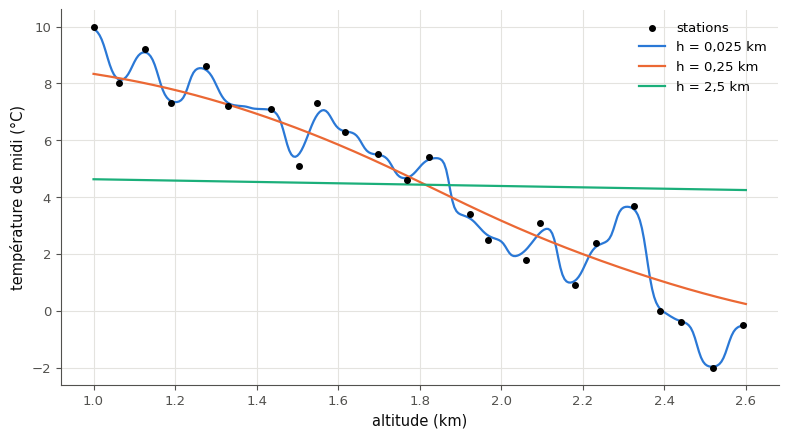

✅ Ex MB3.17 : tes deux fonctions sont justes, sur les stations du notebook et sur des appels cachés.


In [32]:
for letter, answer in zip("defg", [answer_MB3_17d, answer_MB3_17e, answer_MB3_17f, answer_MB3_17g]):
    check_answer(f"MB3.17{letter}", answer)

HIDDEN_C17 = {'X': [0.831, 0.857, 0.949, 1.001, 1.064, 1.189, 1.362, 1.445, 1.46, 1.554, 2.076, 2.082, 2.109, 2.133, 2.156],
 'Y': [9.3, 9.1, 9.9, 9.5, 6.6, 7.0, 7.2, 4.1, 5.3, 3.6, 0.8, 2.0, -0.5, 1.6, 2.0],
 'x': [0.6, 1.05, 1.42, 1.77, 2.1, 2.5],
 'hs': [0.005, 0.3, 3.0],
 'draw_hs': [0.1, 0.6],
 'id': 'MB3.17h'}   # hidden stations, altitudes, widths, and the sub-ID of the predictions expected

with checked("MB3.17"):
    results_17 = []
    report_17 = reporter(results_17, stop=False)
    X_c17, Y_c17, x_c17 = (np.array(HIDDEN_C17[key]) for key in ("X", "Y", "x"))
    got_c17 = [as_floats(call_safely("Ex MB3.17 : nw_predict_17 (appel caché)", nw_predict_17, x_c17.copy(), X_c17.copy(),
                                     Y_c17.copy(), h)) for h in HIDDEN_C17["hs"]]
    if any(g is None or g.shape != x_c17.shape for g in got_c17):
        report_17(False, "", "nw_predict_17 rend une prévision par altitude de x : un tableau de forme (len(x),)")
    elif any(np.isnan(g).any() for g in got_c17):
        report_17(False, "", "nw_predict_17 rend nan sur un appel caché : avec une très petite largeur, toutes les "
                             "exponentielles valent 0 en float64 ; retranche le plus grand score de chaque altitude avant "
                             "l'exponentielle (une softmax stable)")
    else:
        report_17(passes(HIDDEN_C17["id"], [g.tolist() for g in got_c17]),
                  "nw_predict_17 : un appel caché (d'autres stations, d'autres largeurs, dont une très petite) est juste",
                  "nw_predict_17 sur un appel caché : ce n'est pas la prévision de Nadaraya-Watson à noyau gaussien "
                  "exp(−(x − xᵢ)²/(2h²)), une softmax des scores sur les stations, pour chaque altitude de x")

    def unlinked_points_c17(ax, X, Y):
        """True when every station (X[k], Y[k]) is a point of a scatter or of a line with a marker and no line drawn."""
        points = []
        for line in ax.lines:
            if line.get_marker() in (None, "", " ", "None", "none") or line.get_linestyle() not in ("None", "none", "", " "):
                continue
            points += list(zip(np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)))
        for collection in ax.collections:
            offsets = np.asarray(collection.get_offsets(), dtype=float)
            if offsets.ndim == 2 and offsets.shape[1] == 2 and type(collection).__name__ == "PathCollection":
                points += [tuple(point) for point in offsets]
        points = np.array(points or [(np.nan, np.nan)], dtype=float)
        return all(np.any(np.isclose(points[:, 0], x) & np.isclose(points[:, 1], y)) for x, y in zip(X, Y))

    def curves_why_c17(ax, X, Y, hs, curves):
        """What is wrong in a call of draw_bandwidths_17 (French phrases)."""
        if not isinstance(curves, (list, tuple)) or len(curves) != len(hs):
            return [f"draw_bandwidths_17 doit rendre la liste des {len(hs)} courbes tracées, reçu {shown(curves)}"]
        curves = [as_floats(c) for c in curves]
        if any(c is None or c.shape != GRID_17.shape for c in curves):
            return ["chaque courbe rendue est un tableau des prévisions sur GRID_17, de forme (321,)"]
        problems = []
        if not all(matches(c, nw_predict_17(GRID_17, X, Y, h), rtol=1e-9, atol=1e-9) for c, h in zip(curves, hs)):
            problems.append("les courbes rendues sont les prévisions nw_predict_17(GRID_17, X, Y, h), une par h, "
                            "dans l'ordre de hs")
        if not all(line_with(ax, GRID_17, c) for c in curves):
            problems.append("chaque courbe tracée en fonction de GRID_17 (ax.plot(GRID_17, courbe))")
        if not unlinked_points_c17(ax, X, Y):
            problems.append("les stations, un point par station, sans les relier (ax.scatter, ou ax.plot avec un "
                            'marqueur et linestyle="none")')
        if ax.get_legend() is None or len(ax.get_legend().get_texts()) < len(hs):
            problems.append("une légende qui nomme chaque largeur (label=…, puis ax.legend())")
        if not ax.get_xlabel() or not ax.get_ylabel():
            problems.append("des noms d'axes")
        return problems

    fig_17, ax_17 = plt.subplots(figsize=(8, 4.5))
    try:
        result_17 = []
        opened_17 = drawn(lambda: result_17.append(call_safely("Ex MB3.17 : draw_bandwidths_17", draw_bandwidths_17,
                                                               ax_17, X_17, Y_17, H_17)))
        problems_17 = curves_why_c17(ax_17, X_17, Y_17, H_17, result_17[0])
        report_17(not problems_17, "draw_bandwidths_17 (h = 0,025 ; 0,25 ; 2,5) : les courbes, les stations, la légende et "
                  "les noms d'axes", "draw_bandwidths_17 : il manque " + " ; ".join(problems_17))
        fig_c17, axes_c17 = plt.subplots(1, 2)        # the 2nd axes is the current one: plt.plot would draw there
        try:
            hidden_c17 = []
            opened_17 += drawn(lambda: hidden_c17.append(call_safely("Ex MB3.17 : draw_bandwidths_17 (appel caché)",
                                                                     draw_bandwidths_17, axes_c17[0], X_c17, Y_c17,
                                                                     tuple(HIDDEN_C17["draw_hs"]))))
            problems_c17 = curves_why_c17(axes_c17[0], X_c17, Y_c17, HIDDEN_C17["draw_hs"], hidden_c17[0])
            elsewhere_17 = bool(axes_c17[1].lines or axes_c17[1].collections or axes_c17[1].get_legend())
        finally:
            plt.close(fig_c17)
        report_17(not problems_c17, "un appel caché de draw_bandwidths_17 (d'autres stations, deux largeurs) est juste aussi",
                  "un appel caché de draw_bandwidths_17 (d'autres stations, deux largeurs) : il manque "
                  + " ; ".join(problems_c17))
        report_17(not opened_17 and not elsewhere_17, "draw_bandwidths_17 dessine dans les axes reçus",
                  "draw_bandwidths_17 doit dessiner dans les axes reçus (ax.plot, ax.legend…), sans ouvrir de figure ni "
                  "dessiner dans l'axe courant (plt.plot, plt.legend…)")
    except BaseException:
        plt.close(fig_17)
        raise
    fig_17.tight_layout()
    plt.show()
    verdict("MB3.17", all(results_17) and len(results_17) == 4, "tes deux fonctions sont justes, sur les stations du "
            "notebook et sur des appels cachés.", "relis les lignes ❌ ci-dessus.")

**Ce qu'il faut regarder** (après l'expérience) : à quoi ressemblent les trois courbes, et laquelle choisirais-tu ? Que dit d) sur la température du modèle ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 Prédictions attendues : a) (A) ; b) (B) ; c) (A). `nw_predict_17` : les scores `-(x[:, None] - X[None, :]) ** 2 / (2 * h ** 2)`, moins leur maximum par ligne, puis `np.exp`, la normalisation par ligne et le produit par `Y`. d) $(0{,}9653 ;\ 0{,}1099 ;\ 0{,}0424)$ ; e) $(5{,}343 ;\ 4{,}186 ;\ 4{,}427)$ °C ; f) $(0{,}033 ;\ 1{,}220 ;\ 10{,}147)$ ; g) $(11{,}887 ;\ 8{,}095 ;\ 0{,}380)$ °C.

### Ex MB3.18 — La softmax en ligne selon l'ordre et la taille des blocs : le nombre de remises à l'échelle (les états après chaque bloc) pour des scores croissants, décroissants ou mélangés, comparé à H_N − 1, et la mémoire gardée 🔬 ★★ ⏱️ 30 min
**Objectif :** compter les remises à l'échelle de la softmax en ligne selon l'ordre des scores et la taille des blocs, comparer à H_N − 1, et mesurer la mémoire gardée.  
**Prérequis :** fiche §8 et §9 ; R8, M02b ; Ex MB3.15 · **Parcours :** C

Le notebook fournit `S_18`, 600 scores, `V_18`, leurs valeurs, de forme $(600, 3)$, et `ORDERS_18`, 300 ordres de lecture tirés une fois pour toutes par la cellule fournie (300 permutations de `range(600)`, graine 7318). Une remise à l'échelle a lieu quand $m$ change d'un état au suivant (après le premier bloc qui a un score fini). Écris `count_rescalings_18(states)`, qui la compte sur une liste d'états rendue par `mymath.positional.online_softmax(..., history=True)`, puis `draw_rescalings_18(ax, Ns, means, harmonic)`, qui trace dans les axes reçus `means` et `harmonic` en fonction de `Ns`, en abscisse logarithmique, avec une légende qui nomme chaque série (celle de `harmonic` contient « H_N − 1 ») et des noms d'axes. Pour des blocs de $B = 1$, 6 et 60 scores (`BLOCKS_18`, soit $N = 600$, 100 et 10 blocs), relève (chaque fois une liste de 3, dans l'ordre de `BLOCKS_18`) :
- a) le nombre de remises à l'échelle quand les scores sont lus en ordre croissant (les valeurs permutées avec leurs scores) ;
- b) en ordre décroissant ;
- c) leur moyenne sur les 300 ordres de `ORDERS_18` (les valeurs permutées avec leurs scores, le même ordre pour les trois tailles de blocs) ;
- d) $H_N - 1$ pour chaque $N$, où $H_N = 1 + \frac12 + \cdots + \frac1N$ ;
- e) le nombre de flottants que la lecture garde à la fois : l'état ($2 + 3$ nombres) et un bloc ($B$ scores et $B$ valeurs de longueur 3), à comparer aux $600 \times 4 = 2\,400$ d'une lecture qui garde tout ;
- f) vrai ou faux : les neuf états finaux (croissant, décroissant et l'ordre de `S_18`, pour les trois tailles) sont égaux à $10^{-12}$ près (relatif, $m$, $l$ et l'accumulateur).

La vérification essaie `count_rescalings_18` sur des cas cachés, puis trace c) et d) en fonction de $N$ par ta fonction `draw_rescalings_18`.

In [33]:
rng_18 = np.random.default_rng(7318)
S_18 = rng_18.normal(0, 1, 600)                                         # 600 scores
V_18 = rng_18.normal(0, 1, (600, 3))                                    # their values, of length 3
ORDERS_18 = np.array([rng_18.permutation(600) for _ in range(300)])     # the 300 random orders of c), drawn once here
BLOCKS_18 = (1, 6, 60)                                                  # B: N = 600, 100 and 10 blocks
for _array in (S_18, V_18, ORDERS_18):
    _array.setflags(write=False)

In [34]:
def count_rescalings_18(states):
    """The number of rescalings in a list of states (m, l, acc) returned by online_softmax(..., history=True): the
    number of times m changes from one state to the next, after the first block that holds a finite score."""
    ms = [m for m, _, _ in states]
    return sum(1 for before, after in zip(ms[:-1], ms[1:]) if before > -math.inf and after != before)


def draw_rescalings_18(ax, Ns, means, harmonic):
    """In the axes ax: means and harmonic as functions of Ns, the abscissa on a logarithmic scale, with a legend and
    axis labels. Opens no figure."""
    ax.plot(Ns, means, "o-", label="moyenne des remises à l'échelle (300 ordres)")
    ax.plot(Ns, harmonic, "s--", label="$H_N - 1$")
    ax.set_xscale("log")
    ax.set_xlabel("nombre de blocs N")
    ax.set_ylabel("remises à l'échelle")
    ax.legend()


online_softmax = mymath.positional.online_softmax
up_18, down_18 = np.argsort(S_18), np.argsort(S_18)[::-1]
answer_MB3_18a = [count_rescalings_18(online_softmax(S_18[up_18], V_18[up_18], block_size=B, history=True))
                  for B in BLOCKS_18]
answer_MB3_18b = [count_rescalings_18(online_softmax(S_18[down_18], V_18[down_18], block_size=B, history=True))
                  for B in BLOCKS_18]
counts_18 = np.array([[count_rescalings_18(online_softmax(S_18[order], V_18[order], block_size=B, history=True))
                       for B in BLOCKS_18] for order in ORDERS_18])
answer_MB3_18c = counts_18.mean(axis=0).tolist()
answer_MB3_18d = [sum(1 / k for k in range(1, 600 // B + 1)) - 1 for B in BLOCKS_18]
answer_MB3_18e = [5 + 4 * B for B in BLOCKS_18]
finals_18 = [online_softmax(S_18[order], V_18[order], block_size=B)
             for order in (up_18, down_18, np.arange(600)) for B in BLOCKS_18]
answer_MB3_18f = all(math.isclose(m, finals_18[0][0], rel_tol=1e-12) and math.isclose(l, finals_18[0][1], rel_tol=1e-12)
                     and np.allclose(acc, finals_18[0][2], rtol=1e-12, atol=0) for m, l, acc in finals_18)
print("a)", answer_MB3_18a, " b)", answer_MB3_18b, " c)", np.round(answer_MB3_18c, 4).tolist(),
      " (erreurs types :", np.round(counts_18.std(axis=0, ddof=1) / math.sqrt(300), 3).tolist(), ")")
print("d)", np.round(answer_MB3_18d, 4).tolist(), " e)", answer_MB3_18e, " f)", answer_MB3_18f)

a) [599, 99, 9]  b) [0, 0, 0]  c) [5.7233, 4.0067, 1.85]  (erreurs types : [0.123, 0.1, 0.062] )
d) [5.975, 4.1874, 1.929]  e) [9, 29, 245]  f) True


In [35]:
def rescalings_18r(scores, size):
    """The oracle: the block maxima read in order; a rescaling when the running maximum grows, after the first finite
    block (no mymath function)."""
    running, count = -math.inf, 0
    for start in range(0, len(scores), size):
        top = max(scores[start:start + size])
        if top > running:
            count += running > -math.inf
            running = top
    return int(count)


rng_18r = np.random.default_rng(7318)
S_18r = rng_18r.normal(0, 1, 600)
rng_18r.normal(0, 1, (600, 3))                                         # the values: drawn, not needed here
orders_18r = [rng_18r.permutation(600) for _ in range(300)]
sizes_18r = (1, 6, 60)
up_18r = np.sort(S_18r)
a_18r = [rescalings_18r(up_18r, B) for B in sizes_18r]
wbm.record("MB3.18a", a_18r,
           mistakes={"la lecture du premier bloc n'est pas une remise à l'échelle : rien n'était accumulé avant":
                         [a + 1 for a in a_18r],
                     "la liste suit l'ordre de BLOCKS_18 : B = 1, 6, 60": a_18r[::-1]})
wbm.record("MB3.18b", [rescalings_18r(up_18r[::-1], B) for B in sizes_18r],
           mistakes={"la lecture du premier bloc n'est pas une remise à l'échelle : rien n'était accumulé avant": [1, 1, 1]})
c_18r = [float(np.mean([rescalings_18r(S_18r[order], B) for order in orders_18r])) for B in sizes_18r]
wbm.record("MB3.18c", c_18r, decimals=6,
           mistakes={"la lecture du premier bloc n'est pas une remise à l'échelle : rien n'était accumulé avant":
                         [c + 1 for c in c_18r],
                     "la liste suit l'ordre de BLOCKS_18 : B = 1, 6, 60": c_18r[::-1]})
harmonic_18r = [sum(1 / k for k in range(1, 600 // B + 1)) for B in sizes_18r]
wbm.record("MB3.18d", [h - 1 for h in harmonic_18r], decimals=5,
           mistakes={"c'est H_N − 1 : le premier bloc ne compte pas": harmonic_18r,
                     "H_N est la somme 1 + 1/2 + … + 1/N, pas ln N": [math.log(600 // B) - 1 for B in sizes_18r]})
wbm.record("MB3.18e", [5 + 4 * B for B in sizes_18r],
           mistakes={"l'état compte aussi : m, l et les 3 nombres de l'accumulateur": [4 * B for B in sizes_18r],
                     "chaque valeur est un vecteur de longueur 3 : B scores et 3B nombres": [5 + 2 * B for B in sizes_18r]})
wbm.record("MB3.18f", True,
           mistakes={"l'état final ne dépend ni de l'ordre ni de la taille des blocs : compare m, l et l'accumulateur à "
                     "10⁻¹² près (relatif), pas avec == ; s'ils diffèrent vraiment, relance les tests de online_softmax":
                         False})
for scores_18r, size_18r, id_18r in [([-math.inf, -math.inf, 0.3, 1.2, 1.2, 0.5, 2.0, -math.inf, 2.5, 2.5, 3.1], 1, 'MB3.18g'),
 ([-math.inf, -math.inf, -math.inf, -math.inf, 0.7, -0.2, 1.9, 0.1, 1.4, 1.9, -1.0, 0.0, 3.3, 2.2, 3.0, 0.4, 1.0, 2.9, 3.6, 0.2], 4,
  'MB3.18h')]:                # the hidden cases of count_rescalings_18
    wbm.record(id_18r, rescalings_18r(scores_18r, size_18r))

WBM_ANSWER {"decimals": 0, "element_hashes": ["b8095ed8f900d4f97b3a90d55fffe3e85d67b3de28e9f975a8d4c59d75615132", "b2f96508443f49e52d53ce93d50a19d07a3c7c6b77a4718ebd392b15ec1b4ebd", "6979a85bbd1a2230e21508069c6674347aab7bb26c4e0546228b0bf3a18131c7"], "hash": "d6704e92740ff7a605af29d3ad360ecc6bc7ef6191c5e32a29c12707cf4be1d1", "id": "MB3.18a", "integer": true, "kind": "array", "mistakes": {"67f04beaa481c9905bf8ffca8cb52336ec44f255e05e028842691989e093b3b8": "la liste suit l'ordre de BLOCKS_18 : B = 1, 6, 60", "d95c64962646f4bd71ae899c6e3dd0b406c8c2123f5e6c1a4a7ee5697cb0bc53": "la lecture du premier bloc n'est pas une remise à l'échelle : rien n'était accumulé avant"}, "shape": [3]}
📝 Ex MB3.18a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["ec786f4c75285b4c482e5f629011ed46334d3039152c9e6774d55fa7c0078655", "95d1d163be401f50739a191f42308dbb91774a44d02c99129c0404a845b8e410", "c91adae63eaac0093831068f1cbb0f25e8a8757bc0ff885a1186a2da732febe5"], "hash

WBM_ANSWER {"array_rounded": {"1": "f9fe9df279404e91a6c5ae1f3623e9f613a73af2c8f1a43b648c1e2d1cd8ea56", "2": "8f2c43427e59fc2a55421fb0306385217b0954d867c5ddd1f2c812263a704e51", "3": "fbe3e650c8448ff511fb72e769847f49e53e6b4bdcdf1f55fa459a1c2e9eee04", "4": "d4685ff4af43df1dff6f3e13aafc3e97f22dc38d84004e8d6d7103353d801104", "5": "eec6db1afda506811d8f3752206bd9e1fd3a066fa1c5ea6930268c6e82d26382"}, "decimals": 6, "element_coarse": [["bbeb55dff1a50db5f3e3560abf071b6046a6044c7ca411ade2f033d7e9bf2ff2"], ["603dc9ad6df3a7b13553bb3e53359f93c769791b57cb329e3e99143ecef13805"], ["fc659e495218e2774002a4912d2792d7cb10cb7cf6a219fc14f16720c3384381"]], "element_coarse_any": [["95cbd029fff5a26cccd89e0ef29be780fc8ddec71184b351a4967bf073eb8909", "756247e335c569011c64a7f350e84e677eade96fdd338ba31b2325128f681ac2", "bc0dd6b6ba9526bf66260108003970679fb3cce27c5826ccafd08b15a975ff4c", "83cae0a822eccb62c391fff215ef4e83ed4c69685059e2550fc1d23545d60e35", "30c4434480c4cf1ce803ffb169d31ffbbb8ccb43beb537e5c1d82ce476d346

✅ Ex MB3.18a : Bien joué !
✅ Ex MB3.18b : C'est ça !
✅ Ex MB3.18c : Parfait !
✅ Ex MB3.18d : Bravo !
✅ Ex MB3.18e : Exact !
✅ Ex MB3.18f : Bien joué !
✅ count_rescalings_18 : cas caché 1 (des blocs masqués, un maximum atteint deux fois), comme attendu
✅ count_rescalings_18 : cas caché 2 (des blocs masqués, un maximum atteint deux fois), comme attendu
✅ draw_rescalings_18 trace les deux séries, en abscisse logarithmique
✅ draw_rescalings_18 dessine dans les axes reçus


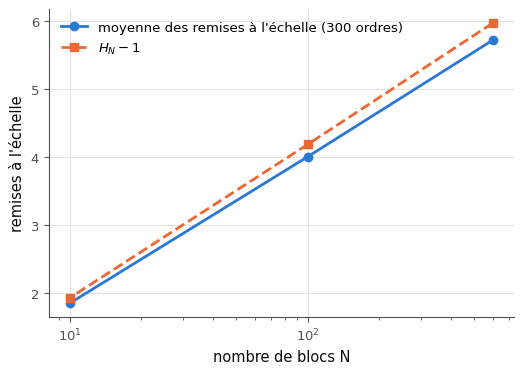

✅ Ex MB3.18 : count_rescalings_18 et draw_rescalings_18 sont justes sur les cas cachés.


In [36]:
for letter, answer in zip("abcdef", [answer_MB3_18a, answer_MB3_18b, answer_MB3_18c, answer_MB3_18d, answer_MB3_18e, answer_MB3_18f]):
    check_answer(f"MB3.18{letter}", answer)

HIDDEN_C18 = [([-math.inf, -math.inf, 0.3, 1.2, 1.2, 0.5, 2.0, -math.inf, 2.5, 2.5, 3.1], 1, 'MB3.18g'),
 ([-math.inf, -math.inf, -math.inf, -math.inf, 0.7, -0.2, 1.9, 0.1, 1.4, 1.9, -1.0, 0.0, 3.3, 2.2, 3.0, 0.4, 1.0, 2.9, 3.6, 0.2], 4,
  'MB3.18h')]   # hidden scores and block sizes, and the sub-IDs of their numbers of rescalings

with checked("MB3.18"):
    results_18 = []
    report_18 = reporter(results_18, stop=False)
    for k_c18, (scores_c18, size_c18, id_c18) in enumerate(HIDDEN_C18, start=1):
        states_c18 = ref_pos.online_softmax(np.array(scores_c18), block_size=size_c18, history=True)
        got_c18 = call_safely(f"Ex MB3.18 : count_rescalings_18 (cas caché {k_c18})", count_rescalings_18, states_c18)
        report_18(passes(id_c18, got_c18), f"count_rescalings_18 : cas caché {k_c18} (des blocs masqués, un maximum "
                  "atteint deux fois), comme attendu",
                  f"count_rescalings_18, cas caché {k_c18} (des blocs masqués, un maximum atteint deux fois) : rendu "
                  f"{shown(got_c18)} ; une remise à l'échelle a lieu quand m change d'un état au suivant, après le premier "
                  "bloc qui a un score fini (rien n'était accumulé avant)")
    Ns_c18, means_c18, harmonic_c18 = [700, 70, 7], [5.2, 3.4, 1.6], [5.6, 3.8, 1.5]     # a test of the drawing only
    fig_c18, axes_c18 = plt.subplots(1, 2)            # the 2nd axes is the current one: plt.plot would draw there
    try:
        opened_c18 = drawn(lambda: call_safely("Ex MB3.18 : draw_rescalings_18", draw_rescalings_18, axes_c18[0],
                                               Ns_c18, means_c18, harmonic_c18))
        ax_c18 = axes_c18[0]
        missing_c18 = []
        for values_c18, what_c18 in ((means_c18, "les moyennes"), (harmonic_c18, "H_N − 1")):
            if not (points_at(ax_c18, Ns_c18, values_c18) or line_with(ax_c18, Ns_c18, values_c18)):
                missing_c18.append(f"{what_c18} en fonction de N (ax.plot(Ns, …), avec ou sans marqueurs)")
        def labels_at_c18(xs, ys):
            """The labels of the lines and scatters of ax_c18 drawn exactly at the points (xs, ys)."""
            found = []
            for line in ax_c18.lines:
                x, y = np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)
                if x.shape == (len(xs),) and np.allclose(x, xs) and np.allclose(y, ys):
                    found.append(str(line.get_label()))
            for collection in ax_c18.collections:
                offsets = np.asarray(collection.get_offsets(), dtype=float)
                if offsets.shape == (len(xs), 2) and np.allclose(offsets, np.column_stack([xs, ys])):
                    found.append(str(collection.get_label()))
            return found

        def names_h_c18(label):
            return "H" in label or "harmon" in label.lower()

        if not missing_c18 and (not any(names_h_c18(label) for label in labels_at_c18(Ns_c18, harmonic_c18))
                                or any(names_h_c18(label) for label in labels_at_c18(Ns_c18, means_c18))):
            missing_c18.append("le bon nom de chaque série dans la légende : « H_N − 1 » pour harmonic, et pas pour "
                               "means (label=…)")
        if ax_c18.get_xscale() != "log":
            missing_c18.append('l\'abscisse logarithmique (ax.set_xscale("log"))')
        if ax_c18.get_legend() is None:
            missing_c18.append("une légende")
        if not ax_c18.get_xlabel() or not ax_c18.get_ylabel():
            missing_c18.append("des noms d'axes")
        elsewhere_c18 = bool(axes_c18[1].lines or axes_c18[1].collections)
    finally:
        plt.close(fig_c18)
    report_18(not missing_c18, "draw_rescalings_18 trace les deux séries, en abscisse logarithmique",
              "draw_rescalings_18 (sur des nombres de test) : il manque " + " ; ".join(missing_c18))
    report_18(not opened_c18 and not elsewhere_c18, "draw_rescalings_18 dessine dans les axes reçus",
              "draw_rescalings_18 doit dessiner dans les axes reçus, sans ouvrir de figure ni dessiner dans l'axe courant")
    if filled(answer_MB3_18c, answer_MB3_18d):                    # your figure, with your answers c) and d)
        fig_18, ax_18 = plt.subplots(figsize=(6, 4))
        call_safely("Ex MB3.18 : draw_rescalings_18", draw_rescalings_18, ax_18, [600 // B for B in BLOCKS_18],
                    answer_MB3_18c, answer_MB3_18d)
        plt.show()
    verdict("MB3.18", all(results_18) and len(results_18) == len(HIDDEN_C18) + 2,
            "count_rescalings_18 et draw_rescalings_18 sont justes sur les cas cachés.", "relis les lignes ❌ ci-dessus.")

**Ce qu'il faut regarder** : comment la moyenne de c) grandit-elle avec $N$ ? Qu'est-ce que l'ordre change, et qu'est-ce qu'il ne change pas ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 `count_rescalings_18` : `ms = [m for m, _, _ in states]`, puis le nombre de `k` tels que `ms[k - 1] > -inf` et `ms[k] != ms[k - 1]`. a) 599, 99 et 9. b) 0, 0 et 0. c) $\approx 5{,}72$, $4{,}01$ et $1{,}85$. d) $H_N - 1 \approx 5{,}975$ ; $4{,}187$ ; $1{,}929$. e) 9, 29 et 245 flottants, contre 2 400. f) Vrai.

### Ex MB3.19 — Trois horloges (la journée, la semaine, l'année) : l'encodage d'une date sur trois cercles, un décalage comme trois rotations, et le produit scalaire de deux encodages en fonction de l'écart 🎨 ★ ⏱️ 30 min
**Objectif :** encoder une date par trois horloges, la dessiner sur trois cercles, lire un décalage comme trois rotations, et tracer le produit scalaire de deux encodages en fonction de leur écart.  
**Prérequis :** fiche §3 et §4 ; Ex MB3.3 et MB3.14 · **Parcours :** C, E

Une date est repérée par $t$, le nombre d'heures écoulées depuis le lundi 1ᵉʳ janvier à 0 h d'une année de 365 jours. Elle est encodée par trois horloges de périodes 24 h, 168 h et 8 760 h (`PERIODS_19`), de pulsations $\omega_k = 2\pi/\tau_k$ (`W_19`) : `encode_19(t)` rend les six nombres $\mathbf{E}(t) = (\cos\omega_1t, \sin\omega_1t, \cos\omega_2t, \sin\omega_2t, \cos\omega_3t, \sin\omega_3t)$. Écris `encode_19(t)`, puis `draw_clocks_19(axes, times, labels)`, qui reçoit une ligne de trois axes (une horloge par axe) et y trace le cercle unité, le point de chaque date de `times` avec son nom (pris dans `labels`) et une même échelle sur les deux axes (`ax.set_aspect("equal")`), et rend la liste des trois tableaux tracés (un tableau de forme `(len(times), 2)` par horloge) ; puis `draw_dot_curve_19(ax, deltas)`, qui trace $\mathbf{E}(0)\cdot\mathbf{E}(\delta)$ en fonction de l'écart $\delta$, en jours sur l'axe des abscisses ($\delta/24$), et rend le tableau des produits scalaires. Les fonctions dessinent dans les axes reçus, sans ouvrir de figure.

La vérification appelle `draw_clocks_19` avec les quatre dates de `DATES_19` (le 3 mars à 8 h, $t = 1\,472$, le 3 mars à 20 h, le 10 mars à 8 h et le 3 septembre à 8 h), puis `draw_dot_curve_19` avec `DELTAS_19` ($\delta = 0, 1, \ldots, 8\,760$ h), affiche la figure, et essaie tes fonctions sur des appels cachés. Relève :
- a) `encode_19(1472)` (6 nombres) ;
- b) $\mathbf{E}(0)\cdot\mathbf{E}(\delta)$ pour $\delta = 12$, 84, 4 380 et 8 760 h (une liste de 4 nombres) ;
- c) l'écart $\delta \in \{1, \ldots, 8\,760\}$ (en heures entières) où ce produit scalaire est le plus grand, puis sa valeur (une liste de 2) ;
- d) vrai ou faux : `encode_19(1472 + 30)` égale $\mathbf{M}$ fois `encode_19(1472)` à $10^{-12}$ près, où $\mathbf{M}$ est le produit des trois rotations `givens_rotation(6, 0, 1, 30 * W_19[0])`, `givens_rotation(6, 2, 3, 30 * W_19[1])` et `givens_rotation(6, 4, 5, 30 * W_19[2])` (ta fonction de MB3.14).

In [37]:
PERIODS_19 = np.array([24.0, 168.0, 8760.0])      # the day, the week, the year (hours)
W_19 = 2 * np.pi / PERIODS_19                         # their angular frequencies omega_k
DATES_19 = {"3 mars 8 h": 1472, "3 mars 20 h": 1484, "10 mars 8 h": 1640, "3 septembre 8 h": 5888}   # t in hours
DELTAS_19 = np.arange(0, 8761)                        # the gaps of the curve (hours)
for _array in (PERIODS_19, W_19, DELTAS_19):
    _array.setflags(write=False)

In [38]:
def encode_19(t):
    """The six numbers (cos w1 t, sin w1 t, cos w2 t, sin w2 t, cos w3 t, sin w3 t) of the time t (hours), w = W_19."""
    return np.array([f(w * t) for w in W_19 for f in (np.cos, np.sin)])


def draw_clocks_19(axes, times, labels):
    """axes: a row of 3 axes (the day, the week, the year). In each: the unit circle, the point of each time of times on
    that clock, with its name (labels) next to it, the same scale on both axes. Returns the list of the 3 arrays drawn,
    each of shape (len(times), 2). Opens no figure."""
    codes = np.array([encode_19(t) for t in times])
    angles = np.linspace(0, 2 * np.pi, 361)
    arrays = []
    for k, (ax, name) in enumerate(zip(axes, ("la journée (24 h)", "la semaine (168 h)", "l'année (8 760 h)"))):
        points = codes[:, 2 * k:2 * k + 2]
        ax.plot(np.cos(angles), np.sin(angles), color="0.7", lw=1)
        ax.scatter(points[:, 0], points[:, 1], s=30, zorder=3)
        for rank, (label, (x, y)) in enumerate(zip(labels, points)):    # shifted by rank: dates at the same point
            ax.annotate(label, (x, y), textcoords="offset points", xytext=(4, 4 + 9 * rank), fontsize=7)
        ax.set_aspect("equal")
        ax.set_title(name, fontsize=10)
        arrays.append(points)
    return arrays


def draw_dot_curve_19(ax, deltas):
    """In the axes ax: E(0)·E(delta) as a function of the gap delta in days (delta / 24), with axis labels. Returns the
    array of the dot products. Opens no figure."""
    e0 = encode_19(0)
    dots = np.array([e0 @ encode_19(d) for d in deltas])
    ax.plot(np.asarray(deltas) / 24, dots, lw=0.6)
    ax.set_xlabel("écart (jours)")
    ax.set_ylabel("E(0)·E(δ)")
    return dots


givens_rotation = mymath.positional.givens_rotation
answer_MB3_19a = encode_19(1472).tolist()
answer_MB3_19b = [float(encode_19(0) @ encode_19(d)) for d in (12, 84, 4380, 8760)]
dots_19 = np.array([encode_19(0) @ encode_19(d) for d in range(1, 8761)])
answer_MB3_19c = [int(np.argmax(dots_19)) + 1, float(dots_19.max())]
M_19 = (givens_rotation(6, 0, 1, 30 * W_19[0]) @ givens_rotation(6, 2, 3, 30 * W_19[1])
        @ givens_rotation(6, 4, 5, 30 * W_19[2]))
answer_MB3_19d = bool(np.allclose(encode_19(1472 + 30), M_19 @ encode_19(1472), rtol=0, atol=1e-12))
print("a)", np.round(answer_MB3_19a, 6).tolist(), " b)", np.round(answer_MB3_19b, 6).tolist())
print("c)", answer_MB3_19c, " d)", answer_MB3_19d)

a) [-0.5, 0.866025, 0.07473, -0.997204, 0.492528, 0.870297]  b) [0.900932, -1.001814, -1.099031, 2.62349]
c) [8736, 2.999851839209116]  d) True


In [39]:
W_19r = [2 * math.pi / p for p in (24.0, 168.0, 8760.0)]


def encode_19r(t, w=W_19r, swap=False):
    """The oracle: (cos, sin) of w_k t for the three clocks, with math (swap: the classic error (sin, cos))."""
    return [f(x * t) for x in w for f in ((math.sin, math.cos) if swap else (math.cos, math.sin))]


def dot_19r(delta, w=W_19r):
    return sum(math.cos(x * delta) for x in w)


wbm.record("MB3.19a", encode_19r(1472), decimals=6,
           mistakes={"pour chaque horloge, (cos ω_k t, sin ω_k t), le cosinus d'abord": encode_19r(1472, swap=True),
                     "ω_k = 2π/τ_k : un tour par période": encode_19r(1472, w=[1 / p for p in (24.0, 168.0, 8760.0)])})
gaps_19r = (12, 84, 4380, 8760)
wbm.record("MB3.19b", [dot_19r(d) for d in gaps_19r], decimals=6,
           mistakes={"le produit scalaire de deux encodages est la somme des produits des six coordonnées, pas leur "
                     "moyenne": [dot_19r(d) / 3 for d in gaps_19r],
                     "E(0) = (1, 0, 1, 0, 1, 0) : le produit scalaire garde les trois cosinus, de toutes les horloges":
                         [math.cos(W_19r[0] * d) for d in gaps_19r]})
values_19r = [dot_19r(d) for d in range(1, 8761)]
best_19r = max(range(8760), key=lambda k: values_19r[k])
wbm.record("MB3.19c", [best_19r + 1, values_19r[best_19r]], decimals=6,
           mistakes={"cherche le plus grand produit scalaire sur tous les écarts de 1 à 8 760 h, pas seulement l'année "
                     "exacte": [8760, values_19r[-1]],
                     "l'écart se donne en heures": [(best_19r + 1) / 24, values_19r[best_19r]]})
wbm.record("MB3.19d", True,
           mistakes={"chaque horloge tourne de 30 ω_k dans son propre plan : compare les deux vecteurs à 10⁻¹² près, "
                     "avec np.allclose ; s'ils diffèrent vraiment, relance les tests de givens_rotation": False})
HIDDEN_19r = {'t': [5.5, 2000.25, 7000.0],
 'id': 'MB3.19e',
 'dates': [100, 4321],
 'labels': ['date A', 'date B'],
 'deltas': [0, 7, 14, 21, 28, 35, 42, 49, 56, 63, 70, 77, 84, 91, 98, 105, 112, 119, 126, 133, 140, 147, 154,
            161, 168, 175, 182, 189, 196, 203, 210, 217, 224, 231, 238, 245, 252, 259, 266, 273, 280, 287, 294,
            301, 308, 315, 322, 329, 336, 343, 350, 357, 364, 371, 378, 385, 392, 399]}                                                  # the hidden times of the check
wbm.record(HIDDEN_19r["id"], [encode_19r(t) for t in HIDDEN_19r["t"]], decimals=6)

WBM_ANSWER {"array_rounded": {"1": "faf32ec364c0df5d0401176b416cd3649bc6f20c86e52b7134d2628462408cbe", "2": "6cf6980fd1c86461ab545f2c028ee5a45fd2c068b0d3d9110f6d1bd4085231b3", "3": "1a9635ae0ca9ca71c871ef61095dbec6c2309d9b5a17722814bb884115d7caf7", "4": "97c8195649b71ee168b0c73e4d80aefb784697f1ad6dc701b738b17a27c5a1a4", "5": "a97c1effb87e516934b3cbe2ecdf463454e8f1bcf9deaa1f877d29a1b478088e"}, "decimals": 6, "element_coarse": [["b15a80b451bb558d961660b879de2f81fcdf6ec7af93ca36cb46a13277d0dad8"], ["acf95553780f6cb7a266ff0ef873961b6eeaa0cbe709df06ece1d937dab4dff1"], ["ba3ca8524bf8d59095bf1af300da875566b74cdba34905cc94d0f03f930787b7"], ["a093aaf8f9a48f3bfd3589e4e1617e76a6188dece9471176e60b46faa4e9aa28"], ["041880a80dafc833da4036fa113341d0a843e11adb1968296e1c14a66cc4cd7c"], ["2d45529aea78b5bc2113d8b21b7b1a88d976d673a5a5d6eba873df3eccd36205"]], "element_coarse_any": [["f2a8525aa3a39676cf9a9b671d5a35f19caebde8e5a43866e70c93aac3b95a07", "e066be28ea033b696c61364df9d78643a9161e2ffb11f4ab8ffcf2a3

✅ Ex MB3.19a : C'est ça !
✅ Ex MB3.19b : Parfait !
✅ Ex MB3.19c : Bravo !
✅ Ex MB3.19d : Exact !
✅ encode_19 : des instants cachés, comme attendu
✅ draw_clocks_19 : les trois horloges, les cercles, les points, les noms et l'échelle


✅ draw_dot_curve_19 : E(0)·E(δ) en fonction de l'écart en jours
✅ des appels cachés (deux autres dates, d'autres écarts) sont justes aussi
✅ tes fonctions dessinent dans les axes reçus


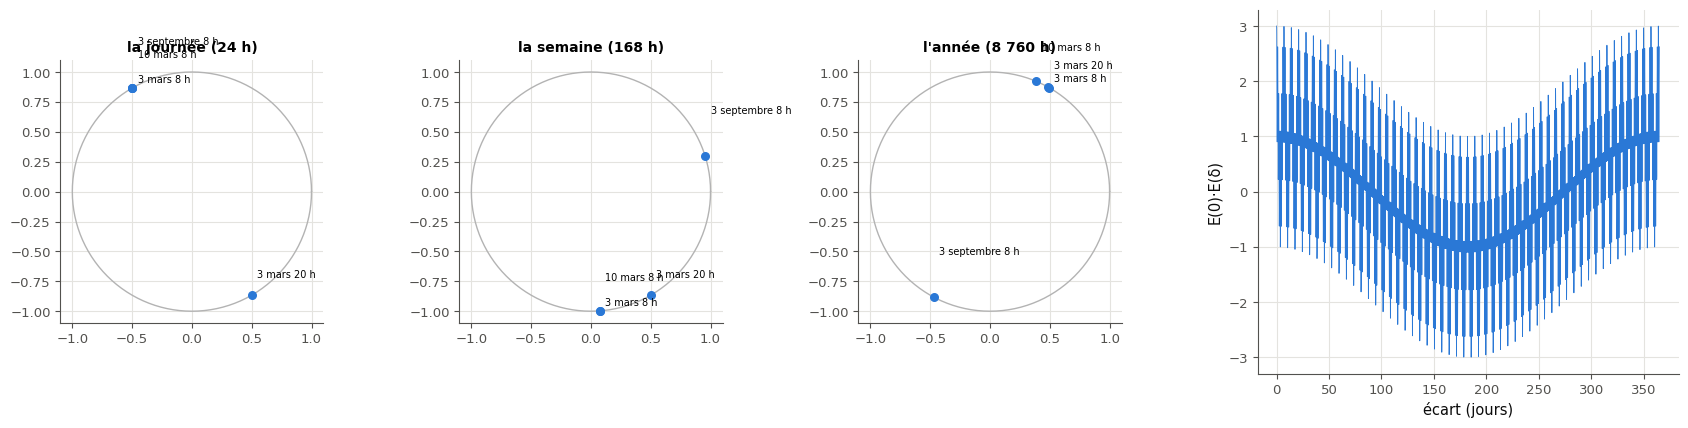

✅ Ex MB3.19 : ton encodage et tes deux figures sont justes.


In [40]:
for letter, answer in zip("abcd", [answer_MB3_19a, answer_MB3_19b, answer_MB3_19c, answer_MB3_19d]):
    check_answer(f"MB3.19{letter}", answer)

HIDDEN_C19 = {'t': [5.5, 2000.25, 7000.0],
 'id': 'MB3.19e',
 'dates': [100, 4321],
 'labels': ['date A', 'date B'],
 'deltas': [0, 7, 14, 21, 28, 35, 42, 49, 56, 63, 70, 77, 84, 91, 98, 105, 112, 119, 126, 133, 140, 147, 154,
            161, 168, 175, 182, 189, 196, 203, 210, 217, 224, 231, 238, 245, 252, 259, 266, 273, 280, 287, 294,
            301, 308, 315, 322, 329, 336, 343, 350, 357, 364, 371, 378, 385, 392, 399]}   # hidden times and the sub-ID of their encodings; hidden dates and gaps for the figures


def on_unit_circle_c19(ax):
    """True when ax shows the unit circle: a Circle patch of radius 1 at (0, 0), or a line of at least 50 points of
    norm 1 that goes around."""
    for patch in ax.patches:
        if type(patch).__name__ == "Circle" and abs(patch.get_radius() - 1) < 1e-9 and np.allclose(patch.center, 0):
            return True
    for line in ax.lines:
        x, y = np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)
        if x.size >= 50 and np.allclose(x ** 2 + y ** 2, 1, atol=1e-6) and np.ptp(np.arctan2(y, x)) > 6:
            return True
    return False


def clocks_why_c19(axes, times, labels, arrays):
    """What is wrong in a call of draw_clocks_19 (French phrases)."""
    if not isinstance(arrays, (list, tuple)) or len(arrays) != 3:
        return [f"draw_clocks_19 doit rendre la liste des 3 tableaux tracés (un par horloge), reçu {shown(arrays)}"]
    arrays = [as_floats(a) for a in arrays]
    if any(a is None or a.shape != (len(times), 2) for a in arrays):
        return [f"chaque tableau tracé a une ligne par date et deux colonnes (cos, sin) : la forme ({len(times)}, 2)"]
    codes = np.array([as_floats(encode_19(t)) for t in times])
    problems = []
    if not all(matches(a, codes[:, 2 * k:2 * k + 2]) for k, a in enumerate(arrays)):
        problems.append("les tableaux tracés sont les points (cos ω_k t, sin ω_k t) de chaque date, horloge par horloge, "
                        "dans l'ordre journée, semaine, année")
    for k, (ax, a) in enumerate(zip(axes, arrays)):
        missing = []
        if not on_unit_circle_c19(ax):
            missing.append("le cercle unité (une courbe d'au moins 50 points, ou plt.Circle)")
        if not points_at(ax, a[:, 0], a[:, 1]):
            missing.append("un point par date (ax.scatter, ou ax.plot avec un marqueur)")
        if not all(name_near(ax, name, x, y, 2.0) for name, (x, y) in zip(labels, a)):
            missing.append("le nom de chaque date près de son point (ax.annotate ou ax.text)")
        if ax.get_aspect() not in (1.0, "equal"):
            missing.append('la même échelle sur les deux axes (ax.set_aspect("equal"))')
        if missing:
            problems.append(f"horloge {k + 1} : il manque " + " ; ".join(missing))
    return problems


def curve_why_c19(ax, deltas, dots):
    """What is wrong in a call of draw_dot_curve_19 (French phrases)."""
    dots = as_floats(dots)
    if dots is None or dots.shape != (len(deltas),):
        return [f"draw_dot_curve_19 rend le tableau des produits scalaires, de forme ({len(deltas)},), reçu {shown(dots)}"]
    problems = []
    e0 = as_floats(encode_19(0))
    if not matches(dots, [float(e0 @ as_floats(encode_19(d))) for d in deltas], rtol=1e-9, atol=1e-9):
        problems.append("le tableau rendu est E(0)·E(δ) pour chaque écart δ de deltas")
    if not line_with(ax, np.asarray(deltas, dtype=float) / 24, dots):
        problems.append("la courbe en fonction de l'écart en jours, δ/24, en abscisse (ax.plot(deltas / 24, …))")
    if not ax.get_xlabel():
        problems.append("un nom pour l'axe des abscisses")
    return problems


with checked("MB3.19"):
    results_19 = []
    report_19 = reporter(results_19, stop=False)
    codes_c19 = [as_floats(call_safely("Ex MB3.19 : encode_19 (appel caché)", encode_19, t)) for t in HIDDEN_C19["t"]]
    if any(c is None or c.shape != (6,) for c in codes_c19):
        report_19(False, "", "encode_19(t) rend les six nombres (cos ω₁t, sin ω₁t, cos ω₂t, sin ω₂t, cos ω₃t, sin ω₃t)")
    else:
        report_19(passes(HIDDEN_C19["id"], [c.tolist() for c in codes_c19]), "encode_19 : des instants cachés, comme attendu",
                  "encode_19 sur des instants cachés : relis l'ordre (cos, sin) par horloge, et ω_k = 2π/τ_k, t en heures")
    fig_19, axes_19 = plt.subplots(1, 4, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
    try:
        names_19, times_19 = list(DATES_19), list(DATES_19.values())
        drawn_19 = []
        opened_19 = drawn(lambda: drawn_19.append(call_safely("Ex MB3.19 : draw_clocks_19", draw_clocks_19, axes_19[:3],
                                                              times_19, names_19)))
        problems_19 = clocks_why_c19(axes_19[:3], times_19, names_19, drawn_19[0])
        report_19(not problems_19, "draw_clocks_19 : les trois horloges, les cercles, les points, les noms et l'échelle",
                  "draw_clocks_19 : " + " ; ".join(problems_19))
        dots_19 = []
        opened_19 += drawn(lambda: dots_19.append(call_safely("Ex MB3.19 : draw_dot_curve_19", draw_dot_curve_19,
                                                              axes_19[3], DELTAS_19)))
        problems_19 = curve_why_c19(axes_19[3], DELTAS_19, dots_19[0])
        report_19(not problems_19, "draw_dot_curve_19 : E(0)·E(δ) en fonction de l'écart en jours",
                  "draw_dot_curve_19 : " + " ; ".join(problems_19))
        fig_c19, axes_c19 = plt.subplots(1, 5)          # the 5th axes is the current one: plt.plot would draw there
        try:
            hidden_19 = []
            opened_19 += drawn(lambda: hidden_19.append(call_safely("Ex MB3.19 : draw_clocks_19 (appel caché)",
                                                                    draw_clocks_19, axes_c19[:3], HIDDEN_C19["dates"],
                                                                    HIDDEN_C19["labels"])))
            problems_c19 = clocks_why_c19(axes_c19[:3], HIDDEN_C19["dates"], HIDDEN_C19["labels"], hidden_19[0])
            hidden_dots_19 = []
            opened_19 += drawn(lambda: hidden_dots_19.append(call_safely("Ex MB3.19 : draw_dot_curve_19 (appel caché)",
                                                                         draw_dot_curve_19, axes_c19[3],
                                                                         np.array(HIDDEN_C19["deltas"]))))
            problems_c19 += curve_why_c19(axes_c19[3], HIDDEN_C19["deltas"], hidden_dots_19[0])
            elsewhere_19 = bool(axes_c19[4].lines or axes_c19[4].collections or axes_c19[4].texts or axes_c19[4].patches)
        finally:
            plt.close(fig_c19)
        report_19(not problems_c19, "des appels cachés (deux autres dates, d'autres écarts) sont justes aussi",
                  "des appels cachés (deux autres dates, d'autres écarts) : " + " ; ".join(problems_c19))
        report_19(not opened_19 and not elsewhere_19, "tes fonctions dessinent dans les axes reçus",
                  "tes fonctions doivent dessiner dans les axes reçus (ax.plot, ax.annotate…), sans ouvrir de figure ni "
                  "dessiner dans l'axe courant (plt.plot, plt.text…)")
    except BaseException:
        plt.close(fig_19)
        raise
    fig_19.tight_layout()
    plt.show()
    verdict("MB3.19", all(results_19) and len(results_19) == 5, "ton encodage et tes deux figures sont justes.",
            "relis les lignes ❌ ci-dessus.")

**Ce qu'il faut regarder** : quelle horloge sépare le 3 mars à 8 h du 3 mars à 20 h ? Et du 3 septembre ? Que vaut le produit scalaire après un an exactement, et pourquoi ? Quand s'approche-t-il le plus de 3 ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 `encode_19` : `np.array([f(w * t) for w in W_19 for f in (np.cos, np.sin)])`. a) $(-0{,}5 ;\ 0{,}866025 ;\ 0{,}074730 ;\ -0{,}997204 ;\ 0{,}492528 ;\ 0{,}870297)$. b) $(0{,}900932 ;\ -1{,}001814 ;\ -1{,}099031 ;\ 2{,}623490)$. c) $\delta = 8\,736$ h (52 semaines), où le produit vaut $\approx 2{,}999852$. d) Vrai.

## Partie C · Déboguer, tester

Fiche §3, §4 et §8. Trois erreurs classiques à corriger ; un test de propriété de la softmax en ligne et de la fusion.

### Ex MB3.20 — Chasse à l'erreur : deux rotations de l'espace composées dans le mauvais ordre, une direction moyenne prise comme la moyenne des angles, une softmax en ligne qui remet l à l'échelle mais pas l'accumulateur 🐛 ★ ⏱️ 25 min
**Objectif :** reconnaître trois erreurs classiques sur l'ordre de deux rotations, la moyenne de directions et la remise à l'échelle de la softmax en ligne, qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §3, §4 et §8 ; Ex MB3.2, MB3.3 et MB3.7 · **Parcours :** C, E

Un collègue a écrit trois fonctions, chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `rotate_e3_then_e1(x, alpha, beta)` doit tourner $\mathbf{x}$ d'abord de $\alpha$ autour de $\mathbf{e}_3$, puis de $\beta$ autour de $\mathbf{e}_1$ ; elle rend `R12(alpha) @ R23(beta) @ x`, où `R12` et `R23` sont ces deux rotations. Il l'a vérifiée avec $\alpha = \beta = \pi$.
2. `mean_direction_bad(angles)` doit rendre la direction moyenne de directions données en degrés, dans $[0, 360[$ ; elle rend `np.mean(angles) % 360`. Il l'a vérifiée sur les relevés 40°, 60° et 80°.
3. `online_softmax_bad(scores, values, block_size)` doit rendre l'état de la softmax en ligne ; quand le maximum change, elle remet $l$ à l'échelle, mais pas l'accumulateur. Il l'a vérifiée en comparant $a/l$ à la moyenne pondérée calculée en une fois, pour des scores rangés en ordre décroissant.

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `rotate_e3_then_e1_fixed`, `mean_direction_fixed` et `online_softmax_fixed`, avec les mêmes arguments (sans `mymath`). Puis réponds :
- a) pour $\mathbf{x} = (2, 0, 1)$, $\alpha = \frac\pi6$ et $\beta = \frac\pi2$ : le résultat de la fonction corrigée, puis de la fonction fautive (une liste de 6 nombres) ;
- b) la direction moyenne des relevés 340°, 10°, 25° et 355°, par la fonction corrigée, puis par la fonction fautive (une liste de 2 nombres) ;
- c) pour les scores $(0{,}4 ;\ 2 ;\ 1{,}1 ;\ 3{,}2 ;\ -0{,}5 ;\ 2{,}7)$, les valeurs $(5, 1, 4, 2, 6, 3)$ et des blocs de 2 : $a/l$ par la fonction corrigée, puis par la fonction fautive (une liste de 2 nombres).

Dans ta copie : pour chacune des trois erreurs, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas cachés : d'autres angles et d'autres vecteurs, des directions de part et d'autre de 0° et autour de 180°, des scores dans un ordre quelconque et des valeurs 2-D.

In [41]:
# The colleague's code
def R12(t):
    """The rotation of space by t about e_3 (in the plane of e_1 and e_2)."""
    return np.array([[math.cos(t), -math.sin(t), 0.0], [math.sin(t), math.cos(t), 0.0], [0.0, 0.0, 1.0]])


def R23(t):
    """The rotation of space by t about e_1 (in the plane of e_2 and e_3)."""
    return np.array([[1.0, 0.0, 0.0], [0.0, math.cos(t), -math.sin(t)], [0.0, math.sin(t), math.cos(t)]])


def rotate_e3_then_e1(x, alpha, beta):
    """x turned first by alpha about e_3, then by beta about e_1."""
    return R12(alpha) @ R23(beta) @ np.asarray(x, dtype=float)


def mean_direction_bad(angles):
    """The mean direction of directions given in degrees, in [0, 360)."""
    return float(np.mean(angles)) % 360


def online_softmax_bad(scores, values, block_size):
    """The state (m, l, acc) of the online softmax of the scores and the values read by blocks of block_size."""
    s, v = np.asarray(scores, dtype=float), np.asarray(values, dtype=float)
    m, l, acc = -math.inf, 0.0, 0.0
    for start in range(0, len(s), block_size):
        block, block_values = s[start:start + block_size], v[start:start + block_size]
        m_new = max(m, float(block.max()))
        factor = math.exp(m - m_new)
        weights = np.exp(block - m_new)
        l = l * factor + float(weights.sum())
        acc = acc + weights @ block_values
        m = m_new
    return m, l, acc


# The colleague's checks: all pass
print("(1)", bool(np.allclose(rotate_e3_then_e1([1.0, 2.0, 3.0], np.pi, np.pi), [-1.0, 2.0, -3.0])),
      "(attendu True : avec alpha = beta = pi, à la main)")
print("(2)", math.isclose(mean_direction_bad([40, 60, 80]), 60.0), "(attendu True : sur 40°, 60° et 80°)")
s_20, v_20 = np.array([3.2, 2.7, 2.0, 1.1, 0.4, -0.5]), np.array([2.0, 3.0, 1.0, 4.0, 5.0, 6.0])
m_20, l_20, acc_20 = online_softmax_bad(s_20, v_20, 2)
direct_20 = float(np.exp(s_20 - s_20.max()) @ v_20 / np.exp(s_20 - s_20.max()).sum())
print("(3)", math.isclose(acc_20 / l_20, direct_20), "(attendu True : des scores rangés en ordre décroissant)")

(1) True (attendu True : avec alpha = beta = pi, à la main)
(2) True (attendu True : sur 40°, 60° et 80°)
(3) True (attendu True : des scores rangés en ordre décroissant)


In [42]:
def rotate_e3_then_e1_fixed(x, alpha, beta):
    """x turned first by alpha about e_3, then by beta about e_1."""
    return R23(beta) @ R12(alpha) @ np.asarray(x, dtype=float)          # the matrix on the right acts first


def mean_direction_fixed(angles):
    """The mean direction of directions given in degrees, in [0, 360)."""
    a = np.radians(np.asarray(angles, dtype=float))
    return float(np.degrees(np.arctan2(np.sin(a).mean(), np.cos(a).mean()))) % 360      # the mean of the vectors


def online_softmax_fixed(scores, values, block_size):
    """The state (m, l, acc) of the online softmax of the scores and the values read by blocks of block_size."""
    s, v = np.asarray(scores, dtype=float), np.asarray(values, dtype=float)
    m, l, acc = -math.inf, 0.0, 0.0
    for start in range(0, len(s), block_size):
        block, block_values = s[start:start + block_size], v[start:start + block_size]
        m_new = max(m, float(block.max()))
        factor = math.exp(m - m_new)
        weights = np.exp(block - m_new)
        l = l * factor + float(weights.sum())
        acc = acc * factor + weights @ block_values                     # acc rescaled like l
        m = m_new
    return m, l, acc


x_20 = np.array([2.0, 0.0, 1.0])
answer_MB3_20a = (rotate_e3_then_e1_fixed(x_20, np.pi / 6, np.pi / 2).tolist()
                  + rotate_e3_then_e1(x_20, np.pi / 6, np.pi / 2).tolist())
answer_MB3_20b = [mean_direction_fixed([340, 10, 25, 355]), mean_direction_bad([340, 10, 25, 355])]
scores_c_20, values_c_20 = [0.4, 2.0, 1.1, 3.2, -0.5, 2.7], [5.0, 1.0, 4.0, 2.0, 6.0, 3.0]
answer_MB3_20c = [(lambda m, l, acc: float(acc / l))(*online_softmax_fixed(scores_c_20, values_c_20, 2)),
                  (lambda m, l, acc: float(acc / l))(*online_softmax_bad(scores_c_20, values_c_20, 2))]
print("a)", np.round(answer_MB3_20a, 6).tolist(), " b)", np.round(answer_MB3_20b, 6).tolist(),
      " c)", np.round(answer_MB3_20c, 6).tolist())

a) [1.732051, -1.0, 1.0, 2.232051, 0.133975, 0.0]  b) [2.5, 182.5]  c) [2.393046, 3.056764]


In [43]:
from scipy.spatial.transform import Rotation as Rotation_20r
from scipy.special import softmax as softmax_20r


def turned_20r(x, alpha, beta, first="z"):
    """The oracle: x turned by alpha about e_3, then by beta about e_1 (scipy, extrinsic rotations); first="x" is the
    colleague's order."""
    angles = [alpha, beta] if first == "z" else [beta, alpha]
    return Rotation_20r.from_euler("zx" if first == "z" else "xz", angles).apply(np.asarray(x, dtype=float)).tolist()


def direction_20r(angles):
    a = np.radians(angles)
    return math.degrees(math.atan2(float(np.mean(np.sin(a))), float(np.mean(np.cos(a))))) % 360


right_a_20r, bad_a_20r = turned_20r([2.0, 0, 1], math.pi / 6, math.pi / 2), turned_20r([2.0, 0, 1], math.pi / 6,
                                                                                     math.pi / 2, first="x")
wbm.record("MB3.20a", right_a_20r + bad_a_20r, decimals=6,
           mistakes={"rotate_e3_then_e1_fixed applique encore d'abord la rotation autour de e₁ : dans un produit de "
                     "matrices appliqué à x, c'est la matrice de droite qui agit la première": bad_a_20r + bad_a_20r,
                     "les trois derniers nombres sont ceux de la version FAUSSE, rotate_e3_then_e1": right_a_20r + right_a_20r,
                     "la version corrigée d'abord, puis la version fautive": bad_a_20r + right_a_20r})
readings_20r = [340, 10, 25, 355]
right_b_20r, bad_b_20r = direction_20r(readings_20r), float(np.mean(readings_20r)) % 360
wbm.record("MB3.20b", [right_b_20r, bad_b_20r], decimals=6,
           mistakes={"mean_direction_fixed rend encore la moyenne des angles : moyenne les vecteurs (cos θ, sin θ)":
                         [bad_b_20r, bad_b_20r],
                     "le second nombre est celui de la version FAUSSE, mean_direction_bad": [right_b_20r, right_b_20r],
                     "la direction se donne en degrés": [math.radians(right_b_20r), bad_b_20r]})
s_20r, v_20r = np.array([0.4, 2.0, 1.1, 3.2, -0.5, 2.7]), np.array([5.0, 1, 4, 2, 6, 3])
right_c_20r = float(softmax_20r(s_20r) @ v_20r)
m_20r, l_20r, acc_20r = -math.inf, 0.0, 0.0                              # the colleague's error, written again
for start_20r in range(0, 6, 2):
    new_20r = max(m_20r, float(s_20r[start_20r:start_20r + 2].max()))
    w_20r = np.exp(s_20r[start_20r:start_20r + 2] - new_20r)
    l_20r, acc_20r, m_20r = l_20r * math.exp(m_20r - new_20r) + w_20r.sum(), acc_20r + w_20r @ v_20r[start_20r:start_20r + 2], new_20r
bad_c_20r = float(acc_20r / l_20r)
wbm.record("MB3.20c", [right_c_20r, bad_c_20r], decimals=6,
           mistakes={"online_softmax_fixed ne remet toujours pas l'accumulateur à l'échelle quand le maximum change":
                         [bad_c_20r, bad_c_20r],
                     "le second nombre est celui de la version FAUSSE, online_softmax_bad": [right_c_20r, right_c_20r]})
CASES_20r = {'rotations': [([2.5, -1.5, 0.5], 1.1, -0.7), ([0.5, 2.5, -1.0], -2.1, 2.0), ([-1.5, 0.5, 2.5], 0.35, 0.35)],
 'directions': [[350, 340, 15, 325], [170, 200, 185, 160], [80, 110, 300, 95]],
 'softmax': [([-2.94, 0.11, -0.59, 0.39, -1.45, 0.63, 2.98],
              [[1.3, -0.99], [0.93, -0.92], [-1.54, 1.03], [0.03, -0.57], [0.0, -0.66], [-0.04, -1.28],
               [1.1, -0.08]],
              3),
             ([-3.69, -1.53, -0.88, 0.82, 1.32, 1.45, 1.41, 1.98, 2.33],
              [4.71, 7.75, 3.75, 4.97, 8.71, 3.33, 5.43, 2.62, 5.61], 2),
             ([-0.69, 0.81, 3.27, -1.23, -2.49],
              [[-0.3, 0.25, 1.06], [0.11, 0.05, -1.13], [0.66, -0.76, -0.26], [1.36, 1.28, -1.21],
               [1.1, -0.16, -0.27]],
              1)],
 'ids': ['MB3.20d', 'MB3.20e']}                                                   # the hidden cases of the check
wbm.record(CASES_20r["ids"][0], [turned_20r(x, a, b) for x, a, b in CASES_20r["rotations"]], decimals=6)
wbm.record(CASES_20r["ids"][1], [direction_20r(angles) for angles in CASES_20r["directions"]], decimals=6)

WBM_ANSWER {"array_rounded": {"1": "1eaded8d84ce955017a687e18f65e9769cd9bbc32caf458a800e0b815e1cceb0", "2": "1e217aedf8bed38de7f2b2aaf3ad641a6cb4377109348455c7aac47386f6500e", "3": "6f188522f5a2adbe267565e19421bf9ea22d469a2e2fa12886b36fb4b649cc4b", "4": "59bbfa69200eca7e0f477d801966f1d6eac22499def54c68f1bcec1c3dbd515f", "5": "e681ab5adead31ed2897b8d8a4ca6586e30848ecfb7d3fdf3efe44d4912266a9"}, "decimals": 6, "element_coarse": [["95f8b7c28ff35dd2c9f41f4239c4f2518ef67adf5be99a465038695c62ec73d8"], ["596a77eb0ad984ebcf725169c0f681718d797da243dcd3a5e5f273895363c79e"], ["af223cc5df0925d5b7e18c0358705227754e44446a1107e8b02948415d7061ff"], ["6708a4ccbdfd9b6c93799d83c60f9db19e36898cf460bd0db6b38e67e8341823"], ["749ad78d74376b316220c9f1efa81432294e7fe5cc0a313c4419e6d50e8463be"], ["74cb07d0992a79236896d8a60234cb9e75043dcc27b096661b0a47ac65945de8"]], "element_coarse_any": [["85edf294a2d92c73243432d99252d3d1c56d59b593decc083aa80751db87abad", "497b0b79c2b063deea93a9be784bb46be57780e1e3c2261248757271

In [44]:
for letter, answer in zip("abc", [answer_MB3_20a, answer_MB3_20b, answer_MB3_20c]):
    check_answer(f"MB3.20{letter}", answer)

CASES_C20 = {'rotations': [([2.5, -1.5, 0.5], 1.1, -0.7), ([0.5, 2.5, -1.0], -2.1, 2.0), ([-1.5, 0.5, 2.5], 0.35, 0.35)],
 'directions': [[350, 340, 15, 325], [170, 200, 185, 160], [80, 110, 300, 95]],
 'softmax': [([-2.94, 0.11, -0.59, 0.39, -1.45, 0.63, 2.98],
              [[1.3, -0.99], [0.93, -0.92], [-1.54, 1.03], [0.03, -0.57], [0.0, -0.66], [-0.04, -1.28],
               [1.1, -0.08]],
              3),
             ([-3.69, -1.53, -0.88, 0.82, 1.32, 1.45, 1.41, 1.98, 2.33],
              [4.71, 7.75, 3.75, 4.97, 8.71, 3.33, 5.43, 2.62, 5.61], 2),
             ([-0.69, 0.81, 3.27, -1.23, -2.49],
              [[-0.3, 0.25, 1.06], [0.11, 0.05, -1.13], [0.66, -0.76, -0.26], [1.36, 1.28, -1.21],
               [1.1, -0.16, -0.27]],
              1)],
 'ids': ['MB3.20d', 'MB3.20e']}   # the hidden cases of the three corrected functions, and the sub-IDs expected

results_20, parts_20 = [], []


def report_20(ok, success, failure):
    results_20.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def references_c20():
    """The functions of positional.py, yours and the reference's: a corrected function calls none of them."""
    names = ("givens_rotation", "online_softmax", "merge_softmax_states")
    found = {f"ref_pos.{name}": getattr(ref_pos, name) for name in names}
    try:
        found.update({f"mymath.positional.{name}": getattr(mymath.positional, name) for name in names})
    except Exception:  # noqa: BLE001 - no positional.py of yours yet: only the reference is watched
        pass
    return found


def call_20(part, name, function, *args):
    """function(*args), without mymath; an error of the learner's code becomes one ❌ line that names the function."""
    try:
        with watched(references_c20()) as seen_c20:
            got = function(*args)
    except ReferenceCalled:
        got = None
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_20(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:160]}")
        parts_20.append(part)
        raise StopCheck from None
    if seen_c20:
        report_20(False, "", f"({part}) {name} appelle {seen_c20[0]} : l'énoncé demande la correction sans mymath, en "
                  "corrigeant le code du collègue")
        parts_20.append(part)
        raise StopCheck
    return got


with checked("MB3.20"):                                      # (1) rotate_e3_then_e1_fixed
    got_c20, wrong_c20 = [], []
    for x_c20, alpha_c20, beta_c20 in CASES_C20["rotations"]:
        x_c20 = np.array(x_c20)                              # floats: a change in place would show
        before_c20 = x_c20.copy()
        got_c20.append(as_floats(call_20(1, "rotate_e3_then_e1_fixed", rotate_e3_then_e1_fixed, x_c20, alpha_c20, beta_c20)))
        if not np.array_equal(x_c20, before_c20):
            wrong_c20.append("ta fonction modifie le vecteur reçu : travaille sur une copie")
    if any(g is None or g.shape != (3,) for g in got_c20):
        wrong_c20.append("rotate_e3_then_e1_fixed rend un vecteur de 3 nombres")
    elif not passes(CASES_C20["ids"][0], [g.tolist() for g in got_c20]):
        same_c20 = all(np.allclose(g, rotate_e3_then_e1(x, a, b)) for g, (x, a, b) in zip(got_c20, CASES_C20["rotations"]))
        wrong_c20.append("ta correction rend encore le résultat de la version du collègue : dans un produit de matrices "
                         "appliqué à x, c'est la matrice de droite qui agit la première" if same_c20 else
                         "sur d'autres angles et d'autres vecteurs, ce n'est pas x tourné d'abord de alpha autour de e₃, "
                         "puis de beta autour de e₁")
    report_20(not wrong_c20, "(1) rotate_e3_then_e1_fixed : trois cas cachés (d'autres angles, d'autres vecteurs)",
              "(1) rotate_e3_then_e1_fixed : " + " ; ".join(dict.fromkeys(wrong_c20)))
    parts_20.append(1)

with checked("MB3.20"):                                      # (2) mean_direction_fixed
    got_c20 = [call_20(2, "mean_direction_fixed", mean_direction_fixed, list(angles)) for angles in CASES_C20["directions"]]
    numbers_c20 = as_floats(got_c20)
    if numbers_c20 is None or numbers_c20.shape != (len(got_c20),):
        why_c20 = f"mean_direction_fixed rend un nombre (des degrés), reçu {shown(got_c20)}"
    elif np.any(numbers_c20 < 0) or np.any(numbers_c20 >= 360):
        why_c20 = "la direction moyenne est dans [0, 360[ : ajoute 360 à un angle négatif (ou % 360)"
    elif passes(CASES_C20["ids"][1], numbers_c20.tolist()):
        why_c20 = ""
    elif all(math.isclose(g, mean_direction_bad(a), abs_tol=1e-6) for g, a in zip(numbers_c20, CASES_C20["directions"])):
        why_c20 = "ta correction rend encore la moyenne des angles : moyenne les vecteurs (cos θ, sin θ)"
    else:
        why_c20 = ("sur des directions de part et d'autre de 0°, ou autour de 180°, ce n'est pas l'angle du vecteur moyen "
                   "des (cos θ, sin θ), en degrés (np.arctan2 garde le bon quadrant)")
    report_20(not why_c20, "(2) mean_direction_fixed : des directions cachées, de part et d'autre de 0° et autour de 180°",
              f"(2) mean_direction_fixed : {why_c20}")
    parts_20.append(2)

with checked("MB3.20"):                                      # (3) online_softmax_fixed, compared with the reference
    wrong_c20 = []
    for scores_c20, values_c20, size_c20 in CASES_C20["softmax"]:
        scores_c20, values_c20 = np.array(scores_c20), np.array(values_c20)
        before_c20 = (scores_c20.copy(), values_c20.copy())
        got_c20 = call_20(3, "online_softmax_fixed", online_softmax_fixed, scores_c20, values_c20, size_c20)
        want_c20 = ref_pos.online_softmax(before_c20[0], before_c20[1], block_size=size_c20)
        if not (np.array_equal(scores_c20, before_c20[0]) and np.array_equal(values_c20, before_c20[1])):
            wrong_c20.append("ta fonction modifie les tableaux reçus : travaille sur des copies")
        elif state_parts(got_c20) is None:
            wrong_c20.append(f"online_softmax_fixed rend l'état (m, l, acc), reçu {shown(got_c20)}")
        elif not same_state(got_c20, want_c20, rtol=1e-9):
            bad_c20 = online_softmax_bad(before_c20[0], before_c20[1], size_c20)
            wrong_c20.append("l'accumulateur n'est toujours pas remis à l'échelle quand le maximum change"
                             if same_state(got_c20, bad_c20) else
                             "sur des scores dans un ordre quelconque et des valeurs 2-D, ce n'est pas l'état (m, l, acc) "
                             "de la softmax en ligne : quand le maximum change, l ET acc sont multipliés par e^(m − m')")
    report_20(not wrong_c20, "(3) online_softmax_fixed : des scores cachés dans un ordre quelconque, des valeurs 1-D et 2-D",
              "(3) online_softmax_fixed : " + " ; ".join(list(dict.fromkeys(wrong_c20))[:2]))
    parts_20.append(3)

if len(set(parts_20)) == 3:
    verdict("MB3.20", all(results_20), "les trois fonctions corrigées passent tous les cas.", "relis les lignes ❌ ci-dessus.")

✅ Ex MB3.20a : Bravo !
✅ Ex MB3.20b : Exact !
✅ Ex MB3.20c : Bien joué !
✅ (1) rotate_e3_then_e1_fixed : trois cas cachés (d'autres angles, d'autres vecteurs)
✅ (2) mean_direction_fixed : des directions cachées, de part et d'autre de 0° et autour de 180°
✅ (3) online_softmax_fixed : des scores cachés dans un ordre quelconque, des valeurs 1-D et 2-D
✅ Ex MB3.20 : les trois fonctions corrigées passent tous les cas.


**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas, et quelle vérification l'aurait vue ?

💡 (1) `rotate_e3_then_e1` applique d'abord la rotation autour de $\mathbf{e}_1$ (la matrice de droite agit la première) ; correction : `R23(beta) @ R12(alpha) @ x`. a) $(1{,}732051 ;\ -1 ;\ 1)$, puis $(2{,}232051 ;\ 0{,}133975 ;\ 0)$. (2) La moyenne des angles ignore que 0° et 360° sont la même direction ; correction : `np.degrees(np.arctan2(np.sin(a).mean(), np.cos(a).mean())) % 360` pour `a` en radians. b) 2,5°, puis 182,5°. (3) L'accumulateur se remet à l'échelle comme $l$ : `acc = acc * factor + weights @ block_values`. c) $\approx 2{,}393046$, puis $\approx 3{,}056764$.

### Ex MB3.21 — Un test de propriété : la softmax en ligne ne dépend ni de la taille des blocs, ni d'une même permutation des scores et des valeurs, ni d'une constante ajoutée aux scores, et la fusion de trois états est associative 🛠️ ★ ⏱️ 35 min
**Objectif :** écrire les contrôles d'un test de propriété de la softmax en ligne et de la fusion, sur des cas tirés au hasard, et voir ce qu'il attrape et ce qu'il ne peut pas attraper.  
**Prérequis :** fiche §8 ; Ex MB3.15 et MB3.16 · **Parcours :** C

La cellule fournie donne la boucle du test, `softmax_property_test_21(n_trials, rng, func=None, merge=None, rtol=1e-9, checks=None)` : quand `func` vaut `None`, elle prend `mymath.positional.online_softmax` **au moment de l'appel**, quand `merge` vaut `None`, `mymath.positional.merge_softmax_states`, et, quand `checks` vaut `None`, ta fonction `failed_checks_21`. Pour chacun des `n_trials` essais, dans cet ordre, elle tire `n = int(rng.integers(3, 13))`, `scores = rng.normal(0, 3, n)`, puis, si `rng.random() < 0.3`, met à $-\infty$ les scores où `rng.random(n) < 0.25` et redonne au score d'indice `int(rng.integers(n))` la valeur `float(rng.normal(0, 3))` ; puis `values = rng.normal(0, 1, (n, 2))`, `block_size = int(rng.integers(1, n + 1))`, `perm = rng.permutation(n)`, `shift = float(rng.normal(0, 20))` et deux coupures `i < j` tirées par `sorted(rng.choice(np.arange(1, n), 2, replace=False))` ; elle appelle `checks(scores, values, block_size, perm, shift, (i, j), f, m, rtol)`, où `f` et `m` sont les fonctions testées, et ajoute 1 au compteur de chaque nom rendu ; elle rend le dictionnaire des quatre compteurs `"blocks"`, `"permutation"`, `"shift"` et `"associative"`.

Écris les contrôles, `failed_checks_21(scores, values, block_size, perm, shift, cuts, func, merge, rtol=1e-9)`, qui rend l'**ensemble** des noms des contrôles qui échouent (`set()` si tout passe), avec `ref = func(scores, values, block_size=1)` :
- `"blocks"` échoue si l'état lu par blocs de `block_size` diffère de `ref` ;
- `"permutation"`, si l'état de `scores[perm]` et `values[perm]`, lu par blocs de 1, diffère de `ref` ;
- `"shift"`, si l'état de `scores + shift`, lu par blocs de 1, diffère de $(m + \text{shift}, l, a)$, où $(m, l, a)$ = `ref` ;
- `"associative"`, si, avec les états des trois morceaux `scores[:i]`, `scores[i:j]` et `scores[j:]` (et de leurs valeurs), lus par `func` avec des blocs de 1, `merge(merge(A, B), C)` diffère de `merge(A, merge(B, C))`.

Pour dire si deux états « diffèrent », sers-toi de la fonction fournie `differ_21(state1, state2, rtol)` : elle rend `True` si leurs $m$ ne sont pas tous deux $-\infty$ et s'écartent de plus de $\texttt{rtol}\cdot\max(1, \lvert m\rvert)$, si leurs $l$ s'écartent de plus de $\texttt{rtol}\cdot\max(1, l)$, ou si leurs accumulateurs ne sont pas égaux par `np.allclose(rtol=rtol, atol=rtol * max(1, abs(acc).max()))`. Une exception levée par `func` ou `merge` fait échouer les quatre contrôles. La cellule fournie donne aussi quatre versions fausses : `rescale_l_only` (la softmax en ligne du 🐛 MB3.20), `centered` (une softmax en ligne qui retranche d'abord aux scores la moyenne des scores finis), `merge_no_rescale` (une fusion qui additionne les $l$ et les accumulateurs sans les remettre à l'échelle) et `merge_mean` (une fusion qui fait la moyenne des deux états remis à l'échelle au lieu de leur somme). Puis :
- a) avec `rng = np.random.default_rng(7321)` et 200 essais, avec tes fonctions `online_softmax` et `merge_softmax_states` et tes contrôles : vrai ou faux, les quatre compteurs sont nuls ;
- b) avec le même départ (un nouveau `default_rng(7321)` chaque fois, 200 essais) et chacune des quatre versions fausses, dans l'ordre `rescale_l_only`, `centered` (pour `func`), `merge_no_rescale`, `merge_mean` (pour `merge`) : les quatre compteurs, dans l'ordre `"blocks"`, `"permutation"`, `"shift"`, `"associative"` (une liste de 4 listes de 4 entiers) ;
- c) dans ta copie : lesquelles passent un contrôle, ou tous, et pourquoi c'est normal ; qu'est-ce qui, dans le dépôt, vérifie ce qu'elles ont de faux ?

La vérification lance aussi ton test sur deux départs cachés de 40 essais, avec les fonctions justes (compteurs nuls) et avec six versions fausses cachées, qui faussent chacune une ou plusieurs des propriétés, ou aucune : l'une d'elles lève une erreur sur des scores tous égaux à $-\infty$, une autre se trompe seulement sur les valeurs 2-D ; elle remplace aussi un instant `mymath.positional.online_softmax` par l'une d'elles, pour l'appel sans `func`. Ce qu'il faut retenir : chaque contrôle attrape certaines erreurs et en laisse passer d'autres ; un test se juge aux erreurs qu'il attrape, et à celles qu'il ne peut pas attraper.

In [45]:
def differ_21(state1, state2, rtol=1e-9):
    """True when the two states (m, l, acc) differ: their m are not both -inf and differ by more than rtol·max(1, |m|),
    their l differ by more than rtol·max(1, l), or their accumulators are not
    np.allclose(rtol=rtol, atol=rtol * max(1, abs(acc).max())) (m, l and acc of state1 for the tolerances)."""
    m1, l1, a1 = state1
    m2, l2, a2 = state2
    m1, l1, m2, l2 = float(m1), float(l1), float(m2), float(l2)
    if not (m1 == -math.inf and m2 == -math.inf) and not abs(m1 - m2) <= rtol * max(1.0, abs(m1)):
        return True
    if not abs(l1 - l2) <= rtol * max(1.0, abs(l1)):
        return True
    if a1 is None or a2 is None:
        return (a1 is None) != (a2 is None)
    a1, a2 = np.atleast_1d(np.asarray(a1, dtype=float)), np.atleast_1d(np.asarray(a2, dtype=float))
    return a1.shape != a2.shape or not np.allclose(a1, a2, rtol=rtol, atol=rtol * max(1.0, float(np.abs(a1).max())))


def rescale_l_only(scores, values=None, block_size=1, history=False):
    """WRONG: the online softmax of 🐛 MB3.20, which rescales l but not the accumulator."""
    s, v = np.asarray(scores, dtype=float), np.asarray(values, dtype=float)
    m, l, acc = -math.inf, 0.0, np.zeros(v.shape[1:])
    for start in range(0, len(s), block_size):
        block, block_values = s[start:start + block_size], v[start:start + block_size]
        if np.all(np.isneginf(block)):
            continue
        m_new = max(m, float(block.max()))
        weights = np.exp(block - m_new)
        l = l * math.exp(m - m_new) + float(weights.sum())
        acc = acc + weights @ block_values
        m = m_new
    return m, l, acc


def centered(scores, values=None, block_size=1, history=False):
    """WRONG: an online softmax that first subtracts from the scores the mean of the finite scores."""
    s = np.asarray(scores, dtype=float)
    finite = np.isfinite(s)
    return ref_pos.online_softmax(s - (float(s[finite].mean()) if finite.any() else 0.0), values, block_size=block_size)


def merge_no_rescale(state1, state2):
    """WRONG: a merge that adds the l and the accumulators without rescaling them."""
    return max(state1[0], state2[0]), state1[1] + state2[1], np.asarray(state1[2], dtype=float) + np.asarray(state2[2], dtype=float)


def merge_mean(state1, state2):
    """WRONG: a merge that takes the mean of the two states rescaled, instead of their sum."""
    m = max(state1[0], state2[0])
    f1 = math.exp(state1[0] - m) if state1[0] > -math.inf else 0.0
    f2 = math.exp(state2[0] - m) if state2[0] > -math.inf else 0.0
    return (m, (state1[1] * f1 + state2[1] * f2) / 2,
            (np.asarray(state1[2], dtype=float) * f1 + np.asarray(state2[2], dtype=float) * f2) / 2)


# The loop of the property test (provided): the draws, in a fixed order, and the counters
def softmax_property_test_21(n_trials, rng, func=None, merge=None, rtol=1e-9, checks=None):
    """n_trials random cases, drawn in this order: n = int(rng.integers(3, 13)), scores = rng.normal(0, 3, n), then, if
    rng.random() < 0.3, the scores where rng.random(n) < 0.25 set to -inf and the score of index int(rng.integers(n))
    given the value float(rng.normal(0, 3)); then values = rng.normal(0, 1, (n, 2)), block_size =
    int(rng.integers(1, n + 1)), perm = rng.permutation(n), shift = float(rng.normal(0, 20)) and the cuts
    sorted(rng.choice(np.arange(1, n), 2, replace=False)). func defaults to mymath.positional.online_softmax, merge to
    mymath.positional.merge_softmax_states, checks to your failed_checks_21, all looked up at the call; each name
    returned by checks adds 1 to its counter. Returns the counters "blocks", "permutation", "shift", "associative"."""
    f = mymath.positional.online_softmax if func is None else func
    mg = mymath.positional.merge_softmax_states if merge is None else merge
    chk = failed_checks_21 if checks is None else checks
    counts = {"blocks": 0, "permutation": 0, "shift": 0, "associative": 0}
    for _ in range(n_trials):
        n = int(rng.integers(3, 13))
        scores = rng.normal(0, 3, n)
        if rng.random() < 0.3:
            scores[rng.random(n) < 0.25] = -np.inf
            scores[int(rng.integers(n))] = float(rng.normal(0, 3))
        values = rng.normal(0, 1, (n, 2))
        block_size = int(rng.integers(1, n + 1))
        perm = rng.permutation(n)
        shift = float(rng.normal(0, 20))
        i, j = (int(c) for c in sorted(rng.choice(np.arange(1, n), 2, replace=False)))
        names = chk(scores, values, block_size, perm, shift, (i, j), f, mg, rtol)
        if not isinstance(names, (set, frozenset, list, tuple)):     # None: shown by wbm.attempt as one ❌ line
            raise TypeError(f"failed_checks_21 doit rendre un ensemble de noms (set() si tout passe), reçu un objet de "
                            f"type {type(names).__name__!r} : as-tu oublié le return ?")
        for name in names:
            if name not in counts:
                raise ValueError(f"les contrôles rendent {name!r} : les noms sont 'blocks', 'permutation', 'shift' et "
                                 "'associative'")
            counts[name] += 1
    return counts

In [46]:
def failed_checks_21(scores, values, block_size, perm, shift, cuts, func, merge, rtol=1e-9):
    """The set of the names of the checks that fail, among "blocks", "permutation", "shift" and "associative" (set() when
    all pass); func and merge are the functions tested."""
    try:
        ref = func(scores, values, block_size=1)
        failed = set()
        if differ_21(func(scores, values, block_size=block_size), ref, rtol):
            failed.add("blocks")
        if differ_21(func(scores[perm], values[perm], block_size=1), ref, rtol):
            failed.add("permutation")
        m, l, acc = ref
        if differ_21(func(scores + shift, values, block_size=1), (m + shift, l, acc), rtol):
            failed.add("shift")
        i, j = cuts
        A, B, C = (func(scores[a:b], values[a:b], block_size=1) for a, b in ((0, i), (i, j), (j, len(scores))))
        if differ_21(merge(merge(A, B), C), merge(A, merge(B, C)), rtol):
            failed.add("associative")
        return failed
    except Exception:  # noqa: BLE001 - an exception of the functions tested fails the four checks
        return {"blocks", "permutation", "shift", "associative"}


KEYS_21 = ("blocks", "permutation", "shift", "associative")
with np.errstate(over="ignore", invalid="ignore"):
    mine_21 = softmax_property_test_21(200, np.random.default_rng(7321))
    wrong_21 = {name: softmax_property_test_21(200, np.random.default_rng(7321), **{role: function})
                for name, role, function in (("rescale_l_only", "func", rescale_l_only), ("centered", "func", centered),
                                             ("merge_no_rescale", "merge", merge_no_rescale),
                                             ("merge_mean", "merge", merge_mean))}
answer_MB3_21a = all(mine_21[key] == 0 for key in KEYS_21)
answer_MB3_21b = [[counts[key] for key in KEYS_21] for counts in wrong_21.values()]
for name_21, counts_21 in {"tes fonctions": mine_21, **wrong_21}.items():
    print(f"{name_21:17s}", counts_21)
print("a)", answer_MB3_21a, " b)", answer_MB3_21b)

tes fonctions     {'blocks': 0, 'permutation': 0, 'shift': 0, 'associative': 0}
rescale_l_only    {'blocks': 126, 'permutation': 191, 'shift': 0, 'associative': 0}
centered          {'blocks': 0, 'permutation': 0, 'shift': 200, 'associative': 0}
merge_no_rescale  {'blocks': 0, 'permutation': 0, 'shift': 0, 'associative': 0}
merge_mean        {'blocks': 0, 'permutation': 0, 'shift': 0, 'associative': 199}
a) True  b) [[126, 191, 0, 0], [0, 0, 200, 0], [0, 0, 0, 0], [0, 0, 0, 199]]


In [47]:
def counters_21r(seed, func, merge, n_trials=200, variant="right"):
    """The loop and the checks of the statement written again (the oracle), with classic variants of the checks:
    "no shift" (ref compared without adding shift to m), "against ref" (merge(merge(A, B), C) compared with ref),
    "one try each" (an exception fails only the check where it happens)."""
    def close(s1, s2):
        (m1, l1, a1), (m2, l2, a2) = s1, s2
        if not (m1 == -math.inf and m2 == -math.inf) and not abs(m1 - m2) <= 1e-9 * max(1.0, abs(m1)):
            return False
        a1, a2 = np.atleast_1d(np.asarray(a1, dtype=float)), np.atleast_1d(np.asarray(a2, dtype=float))
        return (abs(l1 - l2) <= 1e-9 * max(1.0, abs(l1)) and a1.shape == a2.shape
                and bool(np.allclose(a1, a2, rtol=1e-9, atol=1e-9 * max(1.0, float(np.abs(a1).max())))))

    rng, counts = np.random.default_rng(seed), [0, 0, 0, 0]
    for _ in range(n_trials):
        n = int(rng.integers(3, 13))
        s = rng.normal(0, 3, n)
        if rng.random() < 0.3:
            s[rng.random(n) < 0.25] = -np.inf
            s[int(rng.integers(n))] = float(rng.normal(0, 3))
        v = rng.normal(0, 1, (n, 2))
        size = int(rng.integers(1, n + 1))
        perm = rng.permutation(n)
        shift = float(rng.normal(0, 20))
        i, j = (int(c) for c in sorted(rng.choice(np.arange(1, n), 2, replace=False)))
        tests = [lambda: not close(func(s, v, block_size=size), func(s, v, block_size=1)),
                 lambda: not close(func(s[perm], v[perm], block_size=1), func(s, v, block_size=1)),
                 lambda: not close(func(s + shift, v, block_size=1),
                                   (lambda m, l, a: (m + (0.0 if variant == "no shift" else shift), l, a))(
                                       *func(s, v, block_size=1))),
                 lambda: not close(merge(merge(*(func(s[a:b], v[a:b], block_size=1) for a, b in ((0, i), (i, j)))),
                                         func(s[j:], v[j:], block_size=1)),
                                   func(s, v, block_size=1) if variant == "against ref" else
                                   merge(func(s[:i], v[:i], block_size=1),
                                         merge(*(func(s[a:b], v[a:b], block_size=1) for a, b in ((i, j), (j, n))))))]
        if variant == "one try each":
            outcome = []
            for test in tests:
                try:
                    outcome.append(test())
                except Exception:  # noqa: BLE001
                    outcome.append(True)
        else:
            try:
                outcome = [test() for test in tests]
            except Exception:  # noqa: BLE001 - an exception fails the four checks
                outcome = [True] * 4
        counts = [c + bool(o) for c, o in zip(counts, outcome)]
    return counts


os_21r, merge_21r = mymath.positional.online_softmax, mymath.positional.merge_softmax_states   # the reference here
versions_21r = [(rescale_l_only, merge_21r), (centered, merge_21r), (os_21r, merge_no_rescale), (os_21r, merge_mean)]
with np.errstate(over="ignore", invalid="ignore"):
    right_21r = [counters_21r(7321, f, m) for f, m in versions_21r]
    wbm.record("MB3.21a", all(c == 0 for c in counters_21r(7321, os_21r, merge_21r)),
               mistakes={"avec des fonctions justes, aucun contrôle ne doit compter : relis ce que compare chacun, et à "
                         "quoi (par exemple, le contrôle « shift » ajoute shift à m, et « permutation » permute les "
                         "valeurs avec les scores)": False})
    mistakes_21r, seen_21r = {}, [right_21r]
    for message_21r, variant_21r in (("le contrôle « shift » compare à (m + shift, l, acc) : ajouter une constante aux "
                                      "scores déplace m, et ne change ni l ni acc", "no shift"),
                                     ("le contrôle « associative » compare deux groupements, merge(merge(A, B), C) et "
                                      "merge(A, merge(B, C)), pas l'un d'eux à ref", "against ref"),
                                     ("une exception levée fait échouer les quatre contrôles, pas seulement celui où elle "
                                      "arrive", "one try each")):
        counts_21r = [counters_21r(7321, f, m, variant=variant_21r) for f, m in versions_21r]
        if counts_21r not in seen_21r:
            mistakes_21r[message_21r] = counts_21r
            seen_21r.append(counts_21r)
    if right_21r[::-1] not in seen_21r:
        mistakes_21r["l'ordre des versions : rescale_l_only, centered, merge_no_rescale, merge_mean"] = right_21r[::-1]
    wbm.record("MB3.21b", right_21r, mistakes=mistakes_21r)
for seed_21r, ids_21r in [(7341,
  {'col2_c21': {'blocks': 'MB3.21d', 'permutation': 'MB3.21e'},
   'minf_raises_c21': {'blocks': 'MB3.21f',
                       'permutation': 'MB3.21g',
                       'shift': 'MB3.21h',
                       'associative': 'MB3.21i'},
   'scaled_m_c21': {'shift': 'MB3.21j'},
   'drop_tail_c21': {'blocks': 'MB3.21k'},
   'merge_left_c21': {'associative': 'MB3.21l'},
   'merge_first_c21': {}}),
 (7342,
  {'col2_c21': {'blocks': 'MB3.21m', 'permutation': 'MB3.21n'},
   'minf_raises_c21': {'blocks': 'MB3.21o',
                       'permutation': 'MB3.21p',
                       'shift': 'MB3.21q',
                       'associative': 'MB3.21r'},
   'scaled_m_c21': {'shift': 'MB3.21s'},
   'drop_tail_c21': {'blocks': 'MB3.21t'},
   'merge_left_c21': {'associative': 'MB3.21u'},
   'merge_first_c21': {}})]:                    # the counters of the hidden versions, on the hidden starts
    for version_21r, keys_21r in ids_21r.items():
        for key_21r, sub_id_21r in keys_21r.items():
            wbm.record(sub_id_21r, {'MB3.21d': 22,
 'MB3.21e': 35,
 'MB3.21f': 9,
 'MB3.21g': 9,
 'MB3.21h': 9,
 'MB3.21i': 9,
 'MB3.21j': 40,
 'MB3.21k': 21,
 'MB3.21l': 13,
 'MB3.21m': 28,
 'MB3.21n': 35,
 'MB3.21o': 1,
 'MB3.21p': 1,
 'MB3.21q': 1,
 'MB3.21r': 1,
 'MB3.21s': 40,
 'MB3.21t': 22,
 'MB3.21u': 20}[sub_id_21r])

WBM_ANSWER {"hash": "748fbd831ce6241920c2c7dad04bebb737654cd69c67ba86a9a8b0f4a7c5d59f", "id": "MB3.21a", "kind": "bool", "mistakes": {"ff8e5b7fdbba76a9bd1e353f8cad3c6083f7d09fc50de470112b1066b90e3eb2": "avec des fonctions justes, aucun contrôle ne doit compter : relis ce que compare chacun, et à quoi (par exemple, le contrôle « shift » ajoute shift à m, et « permutation » permute les valeurs avec les scores)"}}
📝 Ex MB3.21a : réponse enregistrée (bool).


WBM_ANSWER {"decimals": 0, "element_hashes": ["c6f3643792d87dd2f51a4154eeea44cc4397462d533e03c184c30c9b07f40f28", "ac9a50b27d9aa46484551b322f5637b939b204a8d639149f1cf644d299651cb2", "bba38b263e9141b825d67ac83da17bdc9662e69f1e0d9b1b60aa1fab223386ac", "59ceefb0228a78853873b5ec719907037c9e2cb4b9b574fbfd98b85f5318231e", "32ad128ffd75e4682962889cbbd5f2e6eb1d5243a70ec8d8cd055f3420b15655", "a9ea50638e3e987c7728a6b3ecab7b64f45aa73ae02c1e77d716742ace0b2731", "a6a1aa9e07560033b8af3117a491ab0c64081d4c775a6bd56a24945b99ebb22a", "7d87a413dd4ea50bb175583d76c34cea126d7bdbe4e8a7500671dd7a133855e2", "d10c140bba8c953bd5e9b23532cce4ccc6eb16cf2e53f499a24a8049c23621dd", "61ac62958c73970da393bd90cb116be4210813c014f026d86c518cabb3015959", "6a0176aeea551d967a356eec8fe3887c5b39ec1af0f21de4af4b924cbfa43097", "5ee27e3e7029dcb15dc1d4c7b949bb01c451f29991bcc53f6d95d09a57eca483", "521ac35ee7f211dc0f865039f21f97ba4badde0fc6a14829f2b5fdde9453d1bd", "a1aad2afbe5c652126a0fd3ba7e0680167544ea22219cd7db92aca09e0ead92f", "e

In [48]:
for letter, answer in zip("ab", [answer_MB3_21a, answer_MB3_21b]):
    check_answer(f"MB3.21{letter}", answer)

OS_C21, MERGE_C21 = ref_pos.online_softmax, ref_pos.merge_softmax_states   # captured: never a function replaced later


def col2_c21(scores, values=None, block_size=1, history=False):
    """WRONG for values of two columns or more: the columns after the first are never rescaled."""
    s, v = np.asarray(scores, dtype=float), np.asarray(values, dtype=float)
    m, l, acc = -math.inf, 0.0, np.zeros(v.shape[1:])
    for start in range(0, len(s), block_size):
        block = s[start:start + block_size]
        if np.all(np.isneginf(block)):
            continue
        m_new = max(m, float(block.max()))
        f, w = math.exp(m - m_new), np.exp(block - m_new)
        l = l * f + float(w.sum())
        acc = acc * np.where(np.arange(acc.size) == 0, f, 1.0) + w @ v[start:start + block_size]
        m = m_new
    return m, l, acc


class AllMaskedError_c21(ValueError):
    """The error of minf_raises_c21."""


def minf_raises_c21(scores, values=None, block_size=1, history=False):
    """WRONG: an error when every score is -inf (the empty state is not returned)."""
    if np.all(np.isneginf(np.asarray(scores, dtype=float))):
        raise AllMaskedError_c21("aucun score fini")
    return OS_C21(scores, values, block_size=block_size)


def scaled_m_c21(scores, values=None, block_size=1, history=False):
    """WRONG: m returned multiplied by 1.001 (l and acc right)."""
    m, l, acc = OS_C21(scores, values, block_size=block_size)
    return m * 1.001, l, acc


def drop_tail_c21(scores, values=None, block_size=1, history=False):
    """WRONG: the last block is forgotten when it is shorter than block_size."""
    s = np.asarray(scores, dtype=float)
    keep = len(s) - len(s) % block_size or len(s)
    return OS_C21(s[:keep], None if values is None else np.asarray(values)[:keep], block_size=block_size)


def merge_left_c21(state1, state2):
    """WRONG: only the first state is rescaled to the common maximum."""
    m = max(state1[0], state2[0])
    if m == -math.inf:
        return state1
    f1 = math.exp(state1[0] - m)
    return m, state1[1] * f1 + state2[1], np.asarray(state1[2], dtype=float) * f1 + np.asarray(state2[2], dtype=float)


def merge_first_c21(state1, state2):
    """WRONG, but associative: the first state that is not empty, the other one ignored."""
    return state1 if state1[0] > -math.inf else state2


BROKEN_C21 = {"col2_c21": ("func", ("blocks", "permutation")), "minf_raises_c21": ("func", ("blocks", "permutation", "shift", "associative")),
              "scaled_m_c21": ("func", ("shift",)), "drop_tail_c21": ("func", ("blocks",)),
              "merge_left_c21": ("merge", ("associative",)), "merge_first_c21": ("merge", ())}   # role, properties broken
HIDDEN_C21 = [(7341,
  {'col2_c21': {'blocks': 'MB3.21d', 'permutation': 'MB3.21e'},
   'minf_raises_c21': {'blocks': 'MB3.21f',
                       'permutation': 'MB3.21g',
                       'shift': 'MB3.21h',
                       'associative': 'MB3.21i'},
   'scaled_m_c21': {'shift': 'MB3.21j'},
   'drop_tail_c21': {'blocks': 'MB3.21k'},
   'merge_left_c21': {'associative': 'MB3.21l'},
   'merge_first_c21': {}}),
 (7342,
  {'col2_c21': {'blocks': 'MB3.21m', 'permutation': 'MB3.21n'},
   'minf_raises_c21': {'blocks': 'MB3.21o',
                       'permutation': 'MB3.21p',
                       'shift': 'MB3.21q',
                       'associative': 'MB3.21r'},
   'scaled_m_c21': {'shift': 'MB3.21s'},
   'drop_tail_c21': {'blocks': 'MB3.21t'},
   'merge_left_c21': {'associative': 'MB3.21u'},
   'merge_first_c21': {}})]   # two hidden starts, and the sub-IDs of the counters expected for each version

with checked("MB3.21"):
    results_21 = []
    report_21 = reporter(results_21, stop=False)
    N_C21 = 40
    PROPERTIES_C21 = {"blocks": "l'état lu par blocs de block_size comparé à ref",
                      "permutation": "l'état des scores et des valeurs permutés par perm comparé à ref",
                      "shift": "l'état de scores + shift comparé à (m + shift, l, acc)",
                      "associative": "merge(merge(A, B), C) comparé à merge(A, merge(B, C))"}

    def run_c21(label, seed, **kwargs):
        """The loop of the notebook with your failed_checks_21, on a hidden start: its counters."""
        try:
            return softmax_property_test_21(N_C21, np.random.default_rng(seed), checks=failed_checks_21, **kwargs)
        except (NotImplementedError, MymathMissingError):
            raise
        except Exception as exc:  # noqa: BLE001 - the learner's error
            hint = (" ; failed_checks_21 doit rendre un ensemble de noms (set() si tout passe) : as-tu oublié le return ?"
                    if isinstance(exc, TypeError) and "NoneType" in str(exc) and "return" not in str(exc) else
                    " ; c'est la fonction testée qui lève : une exception de func ou de merge doit faire échouer les quatre "
                    "contrôles (appelle-les dans un try)" if isinstance(exc, AllMaskedError_c21) else "")
            print(f"❌ Ex MB3.21 : failed_checks_21 ({label}) lève {type(exc).__name__} : {str(exc)[:200]}{hint}")
            raise StopCheck from None

    def compare_c21(label, got, version, ids):
        """One ✅ when the four counters are those expected; else one ❌ per counter, naming the property."""
        wrong = []
        for key in ("blocks", "permutation", "shift", "associative"):
            if version is None or key not in BROKEN_C21[version][1]:            # 0 by construction
                if got[key] != 0:
                    wrong.append((key, f"vaut {got[key]}, attendu 0 : "
                                       + ("avec des fonctions justes, aucun contrôle ne compte : ton contrôle compte trop "
                                          "(ce qu'il compare, et à quoi)" if version is None else
                                          "cette version ne fausse pas cette propriété : ton contrôle compte trop (ce "
                                          "qu'il compare, et à quoi)")))
            elif not passes(ids[key], got[key]):
                wrong.append((key, ("vaut 0 : tes contrôles ne vérifient pas " + PROPERTIES_C21[key]
                                    + ", avec les fonctions reçues (func et merge, pas celles de mymath)") if got[key] == 0
                                   else (f"vaut {got[key]}, ce n'est pas le compte attendu : relis ce que ce contrôle "
                                         "compare, et avec quels blocs")))
        if not wrong:
            report_21(True, f"{label} : les quatre compteurs comme attendu", "")
        for key, why in wrong:
            report_21(False, "", f"{label} : le compteur {key!r} {why}")

    for start_c21, (seed_c21, ids_c21) in enumerate(HIDDEN_C21, start=1):
        compare_c21(f"les fonctions justes, départ caché {start_c21}",
                    run_c21("les fonctions justes", seed_c21, func=OS_C21, merge=MERGE_C21), None, {})
        for number_c21, (name_c21, (role_c21, _)) in enumerate(BROKEN_C21.items(), start=1):
            label_c21 = f"une version fausse cachée n° {number_c21}, départ caché {start_c21}"
            functions_c21 = {"func": OS_C21, "merge": MERGE_C21, role_c21: globals()[name_c21]}
            compare_c21(label_c21, run_c21(label_c21, seed_c21, **functions_c21), name_c21, ids_c21[name_c21])
    learner_c21 = (mymath.positional.online_softmax, mymath.positional.merge_softmax_states)   # put back even on failure
    try:
        mymath.positional.online_softmax, mymath.positional.merge_softmax_states = col2_c21, MERGE_C21
        got_c21 = run_c21("func=None", HIDDEN_C21[0][0])
    finally:
        mymath.positional.online_softmax, mymath.positional.merge_softmax_states = learner_c21
    compare_c21("la version fausse n° 1 mise un instant à la place de mymath.positional.online_softmax, sans func", got_c21,
                "col2_c21", HIDDEN_C21[0][1]["col2_c21"])
    verdict("MB3.21", all(results_21), "tes contrôles comptent juste sur les fonctions justes et sur les versions fausses "
            "cachées.", "relis les lignes ❌ ci-dessus.")

✅ Ex MB3.21a : Exact !
✅ Ex MB3.21b : Bien joué !
✅ les fonctions justes, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 1, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 2, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 3, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 4, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 5, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 6, départ caché 1 : les quatre compteurs comme attendu


✅ les fonctions justes, départ caché 2 : les quatre compteurs comme attendu


✅ une version fausse cachée n° 1, départ caché 2 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 2, départ caché 2 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 3, départ caché 2 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 4, départ caché 2 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 5, départ caché 2 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 6, départ caché 2 : les quatre compteurs comme attendu
✅ la version fausse n° 1 mise un instant à la place de mymath.positional.online_softmax, sans func : les quatre compteurs comme attendu
✅ Ex MB3.21 : tes contrôles comptent juste sur les fonctions justes et sur les versions fausses cachées.


💡 `failed_checks_21` : un `try` autour des appels, `ref = func(scores, values, block_size=1)`, puis les quatre contrôles par `differ_21`. a) Vrai. b) `rescale_l_only` : (126, 191, 0, 0) ; `centered` : (0, 0, 200, 0) ; `merge_no_rescale` : (0, 0, 0, 0) ; `merge_mean` : (0, 0, 0, 199). c) `merge_no_rescale` passe tout : additionner sans remettre à l'échelle est associatif, mais faux, et ce sont les tests de `tests/test_mb3_positional.py` qui l'attrapent. La vérification lance ton test avec les fonctions justes et six versions fausses cachées, dont une qui lève une erreur sur des scores tous égaux à $-\infty$, une qui se trompe seulement sur les valeurs 2-D, et une fusion fausse mais associative.

## Partie D · Défi

Fiche §4 et §5. La production d'une éolienne prévue par Nadaraya-Watson sur un encodage cyclique, la largeur choisie par validation croisée, vérifiée sur des éoliennes cachées.

### Ex MB3.22 — Défi : prévoir la production d'une éolienne par Nadaraya-Watson sur l'encodage cyclique de la direction du vent et du jour de l'année, la largeur de bande choisie par validation croisée « un de côté », sous une erreur quadratique moyenne donnée 🏆 ★★★ ⏱️ 45 min
**Objectif :** prévoir par Nadaraya-Watson sur un encodage cyclique, choisir la largeur de bande par validation croisée « un de côté », et le vérifier sur des éoliennes cachées.  
**Prérequis :** fiche §4 et §5 ; M08 ; Ex MB3.17 · **Parcours :** C

Une éolienne reçoit surtout un vent dominant venu des directions proches de 0°, qui souffle le plus fort en hiver. Le notebook fournit `TRAIN_22`, 400 relevés de l'année passée, de forme $(400, 3)$ : la direction d'où vient le vent $\theta$ (en degrés, de 0 à 360 ; 0° et 360° sont la même direction), le jour de l'année $d$ (de 0 à 365) et la production moyenne de l'heure $y$ (en kW) ; et `TEST_22`, de forme $(400, 2)$, les directions et les jours de 400 heures à prévoir, autour du nouvel an, par vent dominant. Écris `predict_22(train, test)`, qui rend 400 prévisions par Nadaraya-Watson à noyau gaussien sur l'encodage cyclique des deux variables, $(\cos\theta, \sin\theta, \cos\frac{2\pi d}{365}, \sin\frac{2\pi d}{365})$, que rend la fonction fournie `encode_22(theta, day)` (un tableau de forme $(n, 4)$), avec une largeur de bande choisie par validation croisée « un de côté » (fiche §5) sur une grille d'une trentaine de valeurs en progression géométrique, par exemple `GRID_22` (30 valeurs de 0,03 à 1,5). Tout NumPy et SciPy sont permis. La cellule fournie donne aussi `mse_22(predictions)`, qui rend l'erreur quadratique moyenne de 400 prévisions de `TEST_22` par rapport à la production moyenne attendue (`TRUTH_22`), sans montrer la loi cachée.

**Critère de réussite** (c'est l'« erreur quadratique moyenne donnée » du titre) **:** sur `TEST_22`, et sur trois éoliennes cachées, tirées à chaque exécution, de bruit faible, moyen et fort (chacune du même type, avec ses relevés et ses heures à prévoir), une erreur quadratique moyenne au plus 1,3 fois celle de la méthode de la vérification (Nadaraya-Watson sur le même encodage, sa largeur choisie sur les 30 valeurs de `GRID_22`) sur le même jeu, en moins de 10 secondes en tout. La vérification recalcule aussi ta réponse b) avec ta fonction (les heures de `TEST_22` dans un autre ordre), et refuse une fonction qui rend les mêmes prévisions pour deux jeux. Les éoliennes cachées viennent d'un processus à part, qui ne rend que l'erreur et le seuil de chacune ; ta fonction ne doit ni lire ni exécuter le module caché du défi (`solutions/challenges/mb3_22.py`), ni lire la vérification ou `TRUTH_22` : la vérification le contrôle. Relève :
- a) la largeur de bande que choisit la validation croisée « un de côté » sur `TRAIN_22`, avec la grille `GRID_22` (un nombre ; 3 décimales dans ta copie) ;
- b) `mse_22` de tes prévisions, `mse_22(predict_22(TRAIN_22, TEST_22))` (un nombre) ;
- c) `mse_22` de la même méthode appliquée aux nombres bruts $(\theta, d)$, sa largeur choisie de la même façon, sur la grille `GRID_RAW_22` (30 valeurs de 1 à 200) (un nombre) ;
- d) la largeur que choisirait la validation croisée sur `GRID_22` si tu ne laissais pas chaque relevé de côté (un nombre).

Point de départ : regarde où sont les heures à prévoir, et ce que deviennent 359° et 1°, ou le jour 364 et le jour 0, dans chaque représentation.

In [49]:
TRAIN_22 = np.array([[4.25, 97.91, 728.8], [354.46, 235.05, 680.4], [7.76, 17.12, 1205.1], [0.77, 271.86, 948.5],
 [339.36, 81.6, 813.4], [347.47, 316.84, 1317.4], [320.52, 203.17, 171.4], [24.48, 30.56, 920.1],
 [329.83, 172.12, 321.9], [98.67, 278.32, 5.3], [325.57, 293.67, 839.3], [339.0, 301.39, 1056.2],
 [3.59, 192.59, 409.2], [306.67, 183.1, 124.8], [44.1, 58.75, 438.8], [316.81, 309.89, 674.4],
 [312.33, 266.62, 437.7], [304.87, 95.85, 192.0], [353.64, 280.91, 951.3], [31.26, 87.08, 532.9],
 [334.42, 276.65, 790.4], [335.5, 302.81, 1100.2], [332.96, 102.99, 708.2], [289.11, 187.66, 1.4],
 [8.69, 252.71, 711.9], [8.37, 354.92, 1285.9], [290.06, 164.12, 117.9], [55.97, 184.83, 110.2],
 [300.54, 159.48, 286.4], [31.53, 251.88, 577.4], [307.65, 143.78, 195.7], [312.25, 181.56, 197.5],
 [328.96, 136.23, 455.1], [17.63, 71.29, 705.6], [343.85, 11.62, 1199.9], [322.78, 244.71, 605.1],
 [0.73, 172.03, 329.5], [1.61, 314.49, 1247.5], [335.34, 154.04, 351.9], [338.57, 168.28, 279.3],
 [18.55, 239.92, 578.1], [8.2, 37.59, 1203.0], [343.24, 134.26, 429.8], [301.3, 357.82, 540.6],
 [18.06, 266.04, 823.1], [332.72, 304.2, 1050.0], [30.05, 119.12, 371.4], [24.29, 260.01, 688.7],
 [293.95, 209.06, 279.4], [295.06, 265.72, 329.9], [312.91, 125.83, 274.8], [324.59, 265.04, 652.7],
 [315.79, 256.78, 528.3], [326.38, 100.21, 450.7], [342.44, 239.96, 664.2], [45.71, 46.63, 509.0],
 [45.39, 3.4, 656.5], [304.69, 360.5, 491.1], [0.4, 70.71, 934.8], [327.99, 357.42, 1055.7],
 [338.03, 250.67, 705.5], [60.03, 237.71, 263.6], [326.28, 96.98, 523.2], [351.49, 62.63, 947.8],
 [351.23, 161.48, 268.6], [58.01, 255.45, 276.2], [287.58, 316.56, 369.1], [20.3, 262.21, 821.6],
 [265.52, 267.94, 120.5], [335.34, 171.66, 403.5], [282.3, 363.82, 212.1], [334.94, 260.15, 782.4],
 [21.99, 41.44, 910.7], [336.2, 2.84, 1104.3], [351.33, 87.87, 799.4], [304.53, 160.15, 105.7],
 [329.58, 192.85, 297.9], [46.39, 144.89, 157.3], [356.8, 324.3, 1337.5], [37.97, 279.25, 513.5],
 [358.22, 36.39, 1201.7], [24.86, 350.15, 1044.8], [311.31, 147.44, 248.8], [23.1, 107.48, 512.9],
 [344.73, 221.8, 505.0], [356.49, 358.51, 1291.5], [59.62, 2.97, 514.9], [45.46, 302.87, 551.8],
 [25.94, 37.92, 861.4], [338.53, 147.75, 339.5], [299.5, 3.64, 502.8], [64.66, 266.47, 260.3],
 [313.45, 37.34, 674.4], [329.8, 163.89, 182.4], [331.63, 130.56, 325.2], [321.97, 353.53, 956.8],
 [298.94, 210.32, 235.5], [46.47, 328.29, 599.8], [30.48, 94.83, 437.2], [331.0, 117.22, 437.9],
 [294.61, 70.37, 274.3], [303.91, 57.28, 483.3], [324.89, 129.45, 351.4], [43.74, 186.42, 203.3],
 [354.06, 8.46, 1260.8], [34.92, 32.35, 802.3], [21.52, 36.47, 911.8], [336.8, 120.79, 420.3],
 [35.37, 54.86, 525.5], [24.91, 195.11, 262.5], [54.34, 86.28, 224.2], [352.57, 44.59, 1131.0],
 [339.42, 222.6, 464.1], [324.54, 22.47, 1012.7], [351.74, 213.33, 485.6], [35.54, 36.87, 792.9],
 [29.53, 193.24, 372.7], [335.97, 241.44, 579.6], [83.84, 293.58, 113.5], [312.79, 325.58, 693.5],
 [20.91, 13.47, 1035.4], [58.49, 175.33, 127.3], [352.27, 169.77, 275.0], [18.44, 138.36, 348.3],
 [7.91, 247.56, 688.3], [17.92, 8.32, 1106.4], [46.39, 240.76, 393.4], [6.41, 37.66, 1161.1],
 [46.18, 197.17, 37.8], [282.37, 298.31, 303.2], [16.96, 208.23, 354.2], [353.46, 110.81, 610.4],
 [358.44, 194.94, 443.7], [323.3, 2.24, 989.2], [348.14, 353.34, 1264.4], [280.96, 185.81, 68.1],
 [352.62, 92.47, 649.6], [106.77, 89.02, 24.9], [4.1, 233.41, 631.6], [347.02, 317.4, 1247.1],
 [16.77, 325.37, 1039.9], [37.27, 166.89, 226.6], [349.69, 195.78, 381.1], [3.0, 181.47, 430.6],
 [2.29, 151.46, 459.7], [305.21, 310.35, 545.9], [327.47, 269.66, 709.1], [318.89, 241.59, 416.2],
 [78.29, 172.29, 0.0], [336.32, 132.22, 351.3], [22.9, 236.66, 523.8], [351.8, 117.56, 571.1],
 [38.59, 308.48, 720.6], [25.83, 200.91, 356.4], [21.16, 126.2, 493.0], [61.98, 322.78, 246.7],
 [12.07, 355.93, 1112.4], [321.05, 194.46, 405.9], [22.23, 92.88, 552.0], [11.02, 68.2, 818.8],
 [0.03, 184.83, 328.5], [349.55, 71.11, 846.8], [0.59, 54.5, 1046.8], [328.39, 262.77, 629.8],
 [346.76, 361.2, 1369.0], [22.35, 4.75, 1103.2], [0.92, 232.76, 562.8], [57.9, 96.65, 262.4],
 [284.54, 56.14, 190.0], [2.38, 65.79, 951.9], [33.59, 347.51, 963.9], [56.5, 344.35, 474.7],
 [296.51, 354.43, 457.1], [356.55, 214.81, 519.9], [296.54, 273.4, 289.9], [263.39, 44.39, 96.1],
 [341.96, 317.38, 1216.9], [338.83, 279.59, 981.9], [34.43, 201.17, 260.9], [320.11, 162.69, 308.3],
 [15.39, 95.76, 675.3], [18.06, 310.54, 1045.5], [299.68, 290.04, 396.2], [7.19, 289.22, 1110.4],
 [57.38, 339.39, 391.0], [6.81, 90.27, 800.1], [353.53, 28.47, 1268.1], [15.71, 217.56, 402.2],
 [341.6, 237.23, 583.3], [11.6, 313.3, 1131.4], [260.67, 107.13, 122.3], [291.73, 9.23, 296.8],
 [315.99, 58.58, 685.6], [326.05, 282.07, 649.0], [341.06, 320.64, 1182.0], [331.38, 24.01, 1175.5],
 [69.7, 289.16, 244.3], [323.69, 290.54, 750.8], [338.14, 94.24, 731.9], [306.61, 50.5, 580.3],
 [1.62, 256.81, 842.7], [44.11, 0.64, 684.6], [355.65, 255.0, 774.5], [10.12, 181.64, 251.3],
 [10.81, 280.95, 981.2], [336.07, 73.14, 797.2], [324.17, 238.25, 491.3], [298.94, 268.52, 318.3],
 [62.58, 281.39, 208.8], [357.33, 138.31, 370.9], [49.39, 297.85, 506.6], [355.23, 158.03, 409.2],
 [352.78, 67.93, 931.1], [54.73, 128.13, 209.3], [43.55, 10.24, 708.9], [334.24, 356.58, 1174.7],
 [356.78, 207.64, 472.3], [1.21, 90.19, 783.1], [357.51, 214.35, 416.3], [49.67, 281.87, 468.5],
 [345.91, 326.21, 1204.7], [0.3, 280.38, 1058.3], [341.93, 21.41, 1256.8], [283.17, 173.14, 154.2],
 [341.49, 267.74, 930.0], [327.84, 343.11, 991.1], [5.49, 242.29, 695.7], [318.76, 185.87, 223.1],
 [298.44, 163.3, 137.3], [302.56, 15.44, 513.7], [276.12, 133.8, 34.9], [81.51, 145.19, 91.3],
 [60.48, 173.16, 133.1], [326.88, 227.95, 483.9], [10.29, 175.79, 410.1], [43.24, 196.11, 226.4],
 [3.39, 94.5, 544.3], [323.02, 233.86, 538.5], [349.09, 84.82, 813.8], [313.71, 190.26, 209.4],
 [349.15, 352.87, 1277.6], [255.51, 154.88, 64.9], [317.87, 329.16, 849.4], [328.33, 269.23, 698.4],
 [2.2, 144.07, 420.4], [323.76, 148.99, 332.1], [77.89, 240.55, 212.1], [26.06, 84.13, 664.8],
 [355.49, 152.23, 425.3], [335.35, 35.32, 1088.8], [324.83, 198.2, 244.0], [358.75, 191.75, 429.1],
 [37.79, 137.62, 303.6], [325.38, 31.02, 783.3], [331.47, 80.43, 618.6], [350.94, 229.48, 542.9],
 [326.29, 205.98, 319.6], [55.43, 254.57, 342.7], [324.07, 225.35, 529.3], [350.08, 92.18, 692.8],
 [48.12, 242.3, 279.3], [4.0, 2.44, 1360.6], [331.1, 319.67, 988.9], [55.93, 7.77, 437.3],
 [359.4, 92.93, 664.2], [321.0, 353.87, 930.4], [307.64, 16.76, 610.7], [336.56, 277.77, 870.0],
 [348.7, 31.11, 1184.6], [11.03, 17.33, 1192.1], [350.91, 164.06, 324.1], [330.47, 321.23, 1071.8],
 [10.46, 216.24, 499.0], [23.24, 235.25, 590.6], [307.84, 12.42, 635.5], [23.67, 286.87, 794.2],
 [292.97, 15.48, 416.3], [338.16, 179.94, 352.2], [357.87, 18.79, 1193.6], [24.02, 1.73, 1053.0],
 [320.41, 300.51, 785.3], [337.44, 8.08, 1240.0], [7.33, 0.19, 1396.2], [356.52, 111.23, 597.5],
 [278.93, 37.51, 293.4], [26.32, 182.65, 251.9], [347.64, 5.33, 1402.9], [42.11, 191.46, 196.4],
 [347.92, 2.07, 1375.6], [350.11, 345.14, 1309.4], [22.73, 65.97, 843.4], [42.89, 238.93, 296.9],
 [342.73, 187.71, 398.6], [3.44, 105.62, 581.3], [36.86, 201.59, 277.5], [336.55, 227.72, 475.4],
 [24.34, 143.31, 330.7], [323.68, 293.83, 822.3], [10.67, 139.75, 336.8], [356.29, 172.71, 436.5],
 [347.43, 43.08, 1050.3], [18.2, 126.84, 438.4], [305.72, 90.48, 463.8], [44.29, 130.77, 258.6],
 [46.45, 286.36, 402.1], [296.28, 79.4, 292.9], [24.13, 58.63, 780.9], [22.15, 44.82, 864.5],
 [330.07, 34.95, 977.0], [280.56, 179.09, 14.0], [344.95, 93.0, 745.0], [352.88, 241.94, 598.9],
 [329.82, 7.99, 1201.2], [334.76, 205.21, 462.1], [6.88, 220.24, 468.2], [7.08, 264.24, 888.9],
 [357.08, 281.36, 959.5], [323.71, 299.61, 974.6], [304.81, 335.36, 616.3], [312.74, 16.01, 710.5],
 [2.26, 226.45, 472.6], [321.52, 95.38, 469.2], [342.24, 68.2, 880.9], [24.71, 98.15, 517.2],
 [326.3, 196.62, 209.0], [312.85, 72.36, 478.9], [69.87, 164.65, 84.3], [90.26, 270.63, 74.0],
 [69.15, 354.1, 149.9], [7.23, 203.78, 552.4], [356.29, 129.49, 372.3], [97.14, 309.75, 77.5],
 [32.06, 34.34, 644.8], [8.81, 154.65, 390.2], [10.26, 230.17, 509.5], [294.72, 215.7, 207.1],
 [21.38, 239.02, 549.5], [321.62, 232.02, 472.8], [353.13, 65.27, 768.0], [352.86, 145.22, 431.0],
 [18.33, 213.86, 389.9], [1.25, 220.41, 511.8], [314.91, 17.43, 742.7], [25.36, 326.17, 994.7],
 [326.48, 300.99, 947.6], [70.69, 22.32, 221.6], [4.57, 150.09, 335.0], [339.74, 73.71, 822.4],
 [2.27, 309.99, 1241.1], [354.55, 348.3, 1330.6], [318.47, 77.26, 562.0], [327.47, 58.86, 744.8],
 [25.38, 240.04, 517.8], [338.97, 310.01, 1198.5], [322.27, 36.08, 848.9], [96.31, 132.42, 140.5],
 [58.24, 74.9, 397.2], [45.58, 189.29, 184.4], [352.28, 133.4, 426.6], [14.49, 67.77, 837.0],
 [329.89, 323.8, 965.2], [47.77, 126.0, 239.2], [351.93, 172.07, 303.3], [16.19, 217.42, 442.8],
 [350.7, 80.42, 819.8], [329.85, 321.83, 1061.5], [66.66, 147.73, 51.8], [311.85, 320.66, 723.8],
 [335.77, 135.93, 292.0], [346.43, 151.43, 349.6], [311.76, 188.22, 258.7], [4.68, 78.19, 795.9],
 [359.63, 287.34, 1020.4], [75.42, 102.12, 78.5], [3.97, 48.12, 1056.4], [24.08, 184.34, 293.4],
 [324.59, 191.96, 211.6], [17.9, 189.57, 383.8], [347.05, 359.5, 1406.8], [13.83, 358.32, 1126.0],
 [307.89, 61.28, 527.6], [16.87, 100.34, 598.9], [350.13, 175.95, 325.1], [44.53, 64.7, 407.1],
 [339.66, 141.99, 477.6], [291.4, 31.2, 420.9], [5.96, 191.66, 391.8], [14.77, 254.92, 731.1],
 [335.79, 243.06, 620.6], [303.26, 270.72, 380.6], [328.85, 115.65, 405.5], [85.43, 359.23, 186.0],
 [328.77, 212.41, 374.8], [22.51, 341.1, 1093.7], [40.06, 149.18, 168.2], [337.13, 341.64, 1142.4],
 [30.6, 345.0, 836.1], [3.09, 169.91, 277.3], [325.98, 274.02, 728.2], [19.4, 325.17, 1092.5]])   # 400 relevés: direction of the wind (degrees), day of the year, production (kW)
TEST_22 = np.array([[330.27, 349.15], [5.29, 0.86], [324.93, 350.43], [348.49, 350.32], [9.3, 12.31], [17.44, 4.75],
 [348.39, 22.05], [323.16, 3.8], [327.84, 4.96], [325.35, 9.67], [339.13, 359.48], [18.65, 14.32],
 [339.23, 340.08], [329.89, 342.3], [6.28, 357.9], [350.35, 344.32], [324.86, 357.36], [22.62, 4.67],
 [337.16, 348.02], [327.62, 20.74], [349.58, 360.84], [19.91, 363.42], [5.2, 7.31], [334.99, 362.5],
 [36.03, 348.41], [11.21, 18.19], [16.47, 357.65], [353.62, 12.32], [18.38, 350.93], [345.56, 342.54],
 [38.45, 354.09], [32.9, 340.78], [10.26, 359.39], [17.44, 362.96], [349.9, 349.59], [27.0, 8.63],
 [18.0, 352.96], [338.42, 23.93], [355.75, 23.66], [346.63, 346.8], [38.94, 350.59], [7.02, 358.38],
 [6.1, 16.68], [15.53, 3.74], [16.06, 359.68], [334.54, 14.02], [339.83, 342.67], [340.98, 341.27],
 [14.78, 347.43], [17.95, 352.61], [7.78, 340.1], [336.08, 13.31], [13.89, 20.36], [32.04, 19.34],
 [9.23, 353.15], [332.75, 351.95], [327.75, 354.6], [37.41, 11.34], [359.62, 364.91], [12.37, 11.73],
 [341.56, 3.35], [351.38, 23.81], [332.04, 16.93], [5.15, 7.84], [358.88, 9.88], [358.17, 356.7], [7.85, 0.72],
 [342.44, 16.02], [32.51, 9.49], [3.29, 344.24], [23.55, 0.22], [326.43, 15.96], [11.23, 3.38],
 [356.56, 341.58], [6.2, 343.46], [359.62, 354.47], [26.11, 17.42], [339.84, 348.08], [22.13, 6.74],
 [321.35, 10.81], [2.95, 4.32], [18.08, 351.29], [324.19, 12.81], [1.33, 4.02], [23.39, 345.87], [35.9, 354.31],
 [329.72, 356.9], [323.11, 344.1], [324.71, 3.9], [357.51, 17.75], [27.14, 15.48], [12.61, 8.05],
 [324.18, 0.08], [23.65, 9.52], [8.69, 11.84], [346.14, 341.02], [339.47, 14.71], [326.86, 8.71],
 [328.37, 350.5], [30.27, 11.24], [331.34, 346.85], [346.65, 341.57], [2.0, 18.68], [359.88, 9.27],
 [322.62, 16.2], [25.92, 340.27], [352.3, 14.28], [342.97, 353.68], [341.92, 357.99], [354.5, 357.18],
 [0.8, 349.26], [27.29, 340.61], [15.47, 350.42], [355.85, 363.29], [1.1, 354.22], [343.25, 357.13],
 [22.22, 341.33], [325.67, 342.73], [7.91, 5.39], [19.8, 22.2], [324.69, 356.64], [333.26, 353.47],
 [342.41, 343.4], [326.95, 22.94], [33.85, 23.57], [7.78, 8.24], [2.42, 342.99], [18.72, 340.81],
 [355.62, 15.49], [324.76, 6.02], [328.05, 347.01], [345.95, 355.16], [1.31, 13.97], [8.45, 2.47],
 [25.28, 15.7], [7.14, 357.0], [9.79, 354.65], [0.69, 12.36], [0.99, 357.62], [324.84, 350.02],
 [330.46, 358.05], [358.83, 17.91], [29.11, 355.68], [357.01, 1.24], [38.48, 349.15], [334.97, 341.9],
 [341.81, 348.51], [13.09, 358.8], [28.44, 17.68], [3.05, 351.81], [37.14, 15.22], [332.27, 356.33],
 [6.95, 1.03], [355.83, 353.94], [330.55, 355.84], [36.38, 346.69], [34.92, 2.79], [13.17, 24.93],
 [324.46, 364.41], [334.81, 353.46], [38.39, 21.56], [342.71, 24.39], [25.63, 346.35], [353.61, 350.39],
 [25.64, 364.13], [14.33, 363.64], [35.61, 6.92], [20.07, 6.54], [13.56, 341.35], [344.08, 350.23],
 [358.31, 11.87], [1.55, 346.4], [342.63, 361.98], [32.9, 357.46], [334.88, 346.19], [19.26, 358.72],
 [330.07, 347.81], [16.0, 9.75], [358.82, 360.29], [29.22, 3.41], [25.06, 358.9], [30.31, 340.25],
 [35.43, 17.82], [339.13, 14.81], [335.57, 3.39], [28.2, 340.1], [30.18, 350.12], [39.58, 344.94],
 [15.86, 6.65], [333.84, 21.1], [338.76, 9.39], [343.16, 9.18], [16.55, 11.24], [19.4, 5.23], [24.93, 1.11],
 [332.9, 360.5], [39.57, 10.17], [347.44, 5.28], [31.58, 14.77], [323.99, 7.05], [350.41, 24.21],
 [9.56, 357.52], [327.62, 358.64], [327.5, 355.18], [6.25, 2.26], [330.13, 343.26], [20.74, 8.03],
 [357.74, 13.71], [343.88, 15.59], [320.36, 342.2], [350.82, 345.63], [329.96, 359.06], [10.26, 8.12],
 [31.93, 4.1], [356.58, 355.03], [16.65, 18.14], [21.35, 354.27], [353.34, 18.73], [21.22, 362.09],
 [1.28, 353.01], [6.62, 21.68], [326.84, 363.19], [1.21, 19.68], [34.58, 346.7], [22.09, 360.0],
 [335.7, 340.14], [352.39, 364.13], [324.64, 364.57], [27.83, 5.56], [322.79, 0.72], [324.39, 350.6],
 [350.48, 364.23], [27.13, 19.89], [17.27, 18.18], [4.91, 363.21], [35.49, 23.34], [22.74, 349.52],
 [14.85, 343.38], [3.8, 9.96], [335.44, 23.85], [27.27, 340.49], [27.83, 22.37], [25.42, 8.93], [34.06, 14.25],
 [37.68, 8.29], [6.55, 356.34], [17.99, 347.01], [333.86, 352.7], [25.23, 24.65], [2.63, 23.35],
 [39.93, 344.63], [32.55, 340.48], [340.12, 359.8], [13.52, 22.91], [346.0, 5.89], [38.09, 349.09],
 [347.52, 350.53], [349.37, 351.71], [356.01, 361.16], [322.68, 341.52], [12.96, 355.36], [4.47, 346.71],
 [358.64, 12.38], [26.1, 11.4], [38.22, 359.6], [6.59, 345.44], [327.22, 23.24], [335.61, 362.93],
 [21.24, 355.31], [24.61, 363.17], [337.6, 17.63], [11.28, 364.05], [17.45, 355.46], [343.61, 354.22],
 [12.9, 17.08], [10.69, 5.47], [37.75, 24.02], [28.47, 362.41], [343.74, 3.26], [331.85, 359.79], [8.3, 346.56],
 [333.17, 350.03], [347.13, 363.91], [351.55, 340.05], [330.03, 362.98], [15.48, 342.69], [356.9, 349.01],
 [340.36, 12.15], [326.33, 17.17], [346.02, 19.1], [19.13, 345.08], [326.71, 8.06], [14.72, 3.05],
 [330.5, 341.43], [31.68, 363.37], [351.87, 7.96], [359.75, 23.75], [349.32, 357.8], [322.28, 7.93],
 [10.12, 20.96], [39.89, 19.12], [352.75, 7.83], [4.94, 20.43], [339.44, 21.64], [350.55, 5.41],
 [25.03, 345.27], [35.61, 15.36], [19.95, 24.23], [327.91, 353.12], [2.25, 345.73], [320.26, 360.82],
 [18.97, 3.75], [28.04, 352.81], [338.79, 9.53], [320.35, 348.42], [19.77, 20.73], [26.16, 5.45],
 [359.4, 364.76], [330.24, 9.75], [353.01, 4.12], [342.43, 2.78], [323.62, 0.97], [37.94, 7.86], [18.72, 2.19],
 [8.16, 347.08], [31.93, 14.67], [357.87, 360.01], [4.23, 14.52], [13.19, 361.99], [31.34, 357.81],
 [321.93, 3.94], [20.52, 19.35], [22.31, 10.72], [324.36, 352.81], [16.54, 344.98], [6.72, 359.71],
 [328.16, 9.04], [13.63, 343.95], [36.38, 359.04], [17.54, 11.7], [328.8, 3.23], [0.76, 9.2], [5.7, 18.82],
 [22.23, 349.31], [359.85, 20.08], [331.24, 358.49], [346.16, 16.38], [23.87, 363.31], [330.33, 344.7],
 [26.63, 359.32], [324.85, 22.47], [27.55, 18.19], [342.64, 8.94], [341.45, 14.63], [18.01, 10.5],
 [321.21, 354.32], [356.9, 24.88], [327.08, 342.77], [5.55, 356.0], [4.06, 5.95], [355.02, 348.62],
 [335.99, 4.32], [12.35, 11.96], [4.43, 342.23], [358.92, 342.84], [14.44, 2.9], [17.87, 361.53],
 [346.26, 349.62], [27.74, 348.54], [331.57, 7.21], [9.58, 355.3], [345.99, 5.62], [327.93, 341.59],
 [343.99, 5.77], [327.54, 21.25], [347.15, 3.78], [11.24, 352.07], [13.74, 9.94], [38.83, 355.21],
 [342.02, 345.13], [329.95, 13.98], [28.2, 364.5], [357.87, 24.89], [28.72, 347.83], [18.93, 345.24],
 [335.75, 22.83], [11.34, 12.53], [26.06, 21.8], [2.9, 6.37], [340.74, 6.75], [37.19, 344.58], [10.71, 15.36],
 [0.39, 349.25], [19.06, 15.94], [351.84, 343.3], [326.47, 22.17], [8.73, 352.58], [29.85, 363.73],
 [338.82, 6.01], [325.19, 12.08]])     # 400 hours to predict: direction (degrees), day
TRUTH_22 = np.array([1087.857, 1306.333, 987.643, 1328.666, 1238.312, 1151.767, 1241.637, 938.426, 1025.148, 968.217, 1227.202,
 1105.973, 1223.021, 1075.986, 1309.558, 1335.886, 984.814, 1064.657, 1201.783, 976.442, 1330.025, 1122.84,
 1291.343, 1162.037, 821.519, 1194.979, 1185.026, 1305.879, 1156.581, 1299.091, 774.03, 878.483, 1267.938,
 1164.135, 1337.249, 975.401, 1162.787, 1133.113, 1259.372, 1312.848, 764.542, 1302.567, 1251.694, 1183.085,
 1189.541, 1116.254, 1234.722, 1247.622, 1211.185, 1163.638, 1288.482, 1142.15, 1152.683, 851.33, 1283.257,
 1131.957, 1041.381, 769.306, 1338.561, 1204.672, 1244.091, 1248.725, 1066.033, 1290.179, 1314.549, 1352.589,
 1284.255, 1215.483, 867.791, 1329.898, 1055.837, 971.014, 1241.753, 1347.93, 1307.685, 1350.436, 967.527,
 1239.627, 1068.821, 889.178, 1314.364, 1161.528, 938.404, 1323.327, 1066.874, 824.399, 1076.873, 948.95,
 968.158, 1286.703, 954.645, 1212.765, 964.0, 1034.996, 1246.213, 1302.082, 1184.706, 998.754, 1053.293,
 907.019, 1105.883, 1307.241, 1269.562, 1313.861, 899.392, 1013.997, 1294.754, 1278.731, 1264.306, 1352.346,
 1346.291, 988.254, 1202.203, 1346.236, 1345.185, 1280.149, 1083.68, 997.502, 1273.17, 1058.42, 981.9, 1140.475,
 1267.567, 956.438, 804.289, 1266.566, 1333.393, 1143.312, 1296.606, 965.084, 1046.049, 1308.114, 1292.07,
 1274.713, 988.038, 1302.591, 1276.65, 1300.543, 1343.658, 985.817, 1089.507, 1283.915, 958.885, 1340.557,
 773.315, 1162.442, 1264.728, 1233.04, 923.831, 1335.626, 765.87, 1122.511, 1292.087, 1355.433, 1092.442,
 813.907, 832.661, 1141.427, 970.329, 1166.088, 726.249, 1181.847, 1025.314, 1352.425, 1018.558, 1209.917,
 812.522, 1104.795, 1222.342, 1290.671, 1308.855, 1341.34, 1268.109, 882.966, 1165.282, 1139.125, 1083.695,
 1160.914, 1347.848, 943.385, 1035.105, 929.025, 791.675, 1179.902, 1161.094, 970.048, 938.35, 750.115,
 1171.381, 1079.28, 1192.629, 1246.926, 1148.284, 1119.011, 1028.962, 1129.982, 730.464, 1297.187, 873.021,
 948.246, 1242.397, 1277.558, 1036.787, 1036.473, 1295.657, 1081.353, 1089.809, 1302.913, 1232.296, 892.964,
 1339.58, 1079.697, 1241.029, 889.36, 1355.085, 1123.018, 1105.532, 1279.305, 1101.942, 1344.705, 1225.584,
 1017.489, 1268.589, 849.673, 1088.785, 1171.53, 1338.107, 973.598, 966.214, 936.047, 977.145, 1329.757,
 940.769, 1113.615, 1313.984, 774.629, 1080.562, 1206.695, 1292.987, 1091.901, 988.492, 919.387, 1004.178,
 826.932, 769.991, 1308.366, 1161.492, 1150.634, 957.252, 1244.519, 743.138, 885.087, 1240.123, 1146.355,
 1283.889, 780.968, 1321.698, 1334.533, 1349.51, 938.087, 1237.173, 1324.388, 1306.4, 985.365, 776.255,
 1306.412, 960.074, 1171.25, 1107.117, 1039.14, 1148.645, 1249.547, 1170.926, 1285.564, 1178.81, 1243.218,
 730.955, 966.374, 1268.735, 1112.639, 1291.119, 1138.88, 1308.519, 1335.489, 1076.774, 1196.636, 1355.047,
 1204.906, 965.391, 1237.544, 1141.268, 997.484, 1196.318, 1085.928, 902.285, 1314.981, 1254.109, 1331.724,
 913.484, 1195.373, 705.035, 1318.422, 1244.272, 1156.592, 1316.386, 1035.92, 794.589, 1047.535, 1044.715,
 1337.308, 891.726, 1129.306, 980.539, 1192.626, 896.773, 1064.801, 998.091, 1339.467, 1057.309, 1329.405,
 1255.504, 951.867, 765.749, 1136.504, 1292.906, 866.608, 1349.915, 1274.003, 1228.069, 913.782, 914.247,
 1057.94, 1055.601, 976.609, 1182.952, 1303.935, 1021.874, 1224.591, 812.876, 1131.762, 1046.141, 1311.023,
 1245.834, 1089.735, 1271.574, 1103.07, 1250.113, 1052.672, 1086.306, 1004.912, 920.46, 938.686, 1241.976,
 1209.461, 1127.989, 914.202, 1253.078, 1024.432, 1316.979, 1303.237, 1354.295, 1165.573, 1204.17, 1319.865,
 1346.706, 1200.612, 1159.125, 1311.201, 985.812, 1086.836, 1278.723, 1284.514, 1039.115, 1265.214, 973.171,
 1298.697, 1260.086, 1192.374, 766.32, 1264.849, 1040.148, 969.074, 1252.157, 966.4, 1144.743, 1100.906,
 1214.642, 953.384, 1309.247, 1225.783, 796.73, 1211.852, 1347.851, 1093.939, 1341.523, 950.755, 1288.67,
 937.891, 1202.623, 959.138])   # the mean production expected at the 400 hours of TEST_22 (the law is not shown)
GRID_22 = np.geomspace(0.03, 1.5, 30)        # 30 widths, from 0.03 to 1.5 (the grid of the method of the check)
GRID_RAW_22 = np.geomspace(1.0, 200.0, 30)   # 30 widths, from 1 to 200 (for the raw numbers of c))
for _array in (TRAIN_22, TEST_22, TRUTH_22, GRID_22, GRID_RAW_22):
    _array.setflags(write=False)


def encode_22(theta, day):
    """The cyclic encoding (cos θ, sin θ, cos 2πd/365, sin 2πd/365) of the directions theta (degrees) and the days: an
    array of shape (n, 4)."""
    a = np.radians(np.asarray(theta, dtype=float))
    b = 2 * np.pi * np.asarray(day, dtype=float) / 365
    return np.column_stack([np.cos(a), np.sin(a), np.cos(b), np.sin(b)])


def mse_22(predictions):
    """The mean squared error (kW²) of 400 predictions of the hours of TEST_22, against the mean production expected."""
    p = np.asarray(predictions, dtype=float)
    if p.shape != TRUTH_22.shape:
        raise ValueError(f"mse_22 attend 400 prévisions, une par heure de TEST_22, reçu la forme {p.shape}")
    return float(np.mean((p - TRUTH_22) ** 2))

In [50]:
def loo_width_22(Z, y, grid, leave_out=True):
    """The width of grid with the smallest leave-one-out error (leave_out=False: each point predicts itself too)."""
    D2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=-1)                  # the squared distances of all the pairs
    errors = []
    for h in grid:
        S = -D2 / (2 * h ** 2)
        if leave_out:
            np.fill_diagonal(S, -np.inf)                                     # a relevé does not predict itself
        W = np.exp(S - S.max(axis=1, keepdims=True))
        errors.append(float(np.mean((W @ y / W.sum(axis=1) - y) ** 2)))
    return float(grid[int(np.argmin(errors))])


def nw_22(Z, y, Z_test, h):
    """The Nadaraya-Watson predictions at the rows of Z_test, by a stable softmax."""
    S = -((Z_test[:, None, :] - Z[None, :, :]) ** 2).sum(axis=-1) / (2 * h ** 2)
    W = np.exp(S - S.max(axis=1, keepdims=True))
    return W @ y / W.sum(axis=1)


def predict_22(train, test):
    """400 predictions of the mean production at the hours of test (an array (400, 2): direction in degrees, day), by
    Nadaraya-Watson with a Gaussian kernel on encode_22, from train (an array (400, 3): direction, day, production), the
    width chosen by leave-one-out cross-validation."""
    Z, y, Z_test = encode_22(train[:, 0], train[:, 1]), np.asarray(train[:, 2], dtype=float), encode_22(test[:, 0], test[:, 1])
    return nw_22(Z, y, Z_test, loo_width_22(Z, y, GRID_22))


start_22 = time.perf_counter()
Z_22, y_22 = encode_22(TRAIN_22[:, 0], TRAIN_22[:, 1]), TRAIN_22[:, 2]
answer_MB3_22a = loo_width_22(Z_22, y_22, GRID_22)
answer_MB3_22b = mse_22(predict_22(TRAIN_22, TEST_22))
raw_22, raw_test_22 = TRAIN_22[:, :2], TEST_22
answer_MB3_22c = mse_22(nw_22(raw_22, y_22, raw_test_22, loo_width_22(raw_22, y_22, GRID_RAW_22)))
answer_MB3_22d = loo_width_22(Z_22, y_22, GRID_22, leave_out=False)
print(f"a) {answer_MB3_22a:.6f}  b) {answer_MB3_22b:.1f}  c) {answer_MB3_22c:.1f} (soit {answer_MB3_22c / answer_MB3_22b:.2f} "
      f"fois b)  d) {answer_MB3_22d}  ({time.perf_counter() - start_22:.2f} s)")

a) 0.151406  b) 2110.5  c) 3837.7 (soit 1.82 fois b)  d) 0.03  (0.21 s)


In [51]:
from scipy.special import softmax as softmax_22r

train_22r, test_22r, truth_22r = np.array([[4.25, 97.91, 728.8], [354.46, 235.05, 680.4], [7.76, 17.12, 1205.1], [0.77, 271.86, 948.5],
 [339.36, 81.6, 813.4], [347.47, 316.84, 1317.4], [320.52, 203.17, 171.4], [24.48, 30.56, 920.1],
 [329.83, 172.12, 321.9], [98.67, 278.32, 5.3], [325.57, 293.67, 839.3], [339.0, 301.39, 1056.2],
 [3.59, 192.59, 409.2], [306.67, 183.1, 124.8], [44.1, 58.75, 438.8], [316.81, 309.89, 674.4],
 [312.33, 266.62, 437.7], [304.87, 95.85, 192.0], [353.64, 280.91, 951.3], [31.26, 87.08, 532.9],
 [334.42, 276.65, 790.4], [335.5, 302.81, 1100.2], [332.96, 102.99, 708.2], [289.11, 187.66, 1.4],
 [8.69, 252.71, 711.9], [8.37, 354.92, 1285.9], [290.06, 164.12, 117.9], [55.97, 184.83, 110.2],
 [300.54, 159.48, 286.4], [31.53, 251.88, 577.4], [307.65, 143.78, 195.7], [312.25, 181.56, 197.5],
 [328.96, 136.23, 455.1], [17.63, 71.29, 705.6], [343.85, 11.62, 1199.9], [322.78, 244.71, 605.1],
 [0.73, 172.03, 329.5], [1.61, 314.49, 1247.5], [335.34, 154.04, 351.9], [338.57, 168.28, 279.3],
 [18.55, 239.92, 578.1], [8.2, 37.59, 1203.0], [343.24, 134.26, 429.8], [301.3, 357.82, 540.6],
 [18.06, 266.04, 823.1], [332.72, 304.2, 1050.0], [30.05, 119.12, 371.4], [24.29, 260.01, 688.7],
 [293.95, 209.06, 279.4], [295.06, 265.72, 329.9], [312.91, 125.83, 274.8], [324.59, 265.04, 652.7],
 [315.79, 256.78, 528.3], [326.38, 100.21, 450.7], [342.44, 239.96, 664.2], [45.71, 46.63, 509.0],
 [45.39, 3.4, 656.5], [304.69, 360.5, 491.1], [0.4, 70.71, 934.8], [327.99, 357.42, 1055.7],
 [338.03, 250.67, 705.5], [60.03, 237.71, 263.6], [326.28, 96.98, 523.2], [351.49, 62.63, 947.8],
 [351.23, 161.48, 268.6], [58.01, 255.45, 276.2], [287.58, 316.56, 369.1], [20.3, 262.21, 821.6],
 [265.52, 267.94, 120.5], [335.34, 171.66, 403.5], [282.3, 363.82, 212.1], [334.94, 260.15, 782.4],
 [21.99, 41.44, 910.7], [336.2, 2.84, 1104.3], [351.33, 87.87, 799.4], [304.53, 160.15, 105.7],
 [329.58, 192.85, 297.9], [46.39, 144.89, 157.3], [356.8, 324.3, 1337.5], [37.97, 279.25, 513.5],
 [358.22, 36.39, 1201.7], [24.86, 350.15, 1044.8], [311.31, 147.44, 248.8], [23.1, 107.48, 512.9],
 [344.73, 221.8, 505.0], [356.49, 358.51, 1291.5], [59.62, 2.97, 514.9], [45.46, 302.87, 551.8],
 [25.94, 37.92, 861.4], [338.53, 147.75, 339.5], [299.5, 3.64, 502.8], [64.66, 266.47, 260.3],
 [313.45, 37.34, 674.4], [329.8, 163.89, 182.4], [331.63, 130.56, 325.2], [321.97, 353.53, 956.8],
 [298.94, 210.32, 235.5], [46.47, 328.29, 599.8], [30.48, 94.83, 437.2], [331.0, 117.22, 437.9],
 [294.61, 70.37, 274.3], [303.91, 57.28, 483.3], [324.89, 129.45, 351.4], [43.74, 186.42, 203.3],
 [354.06, 8.46, 1260.8], [34.92, 32.35, 802.3], [21.52, 36.47, 911.8], [336.8, 120.79, 420.3],
 [35.37, 54.86, 525.5], [24.91, 195.11, 262.5], [54.34, 86.28, 224.2], [352.57, 44.59, 1131.0],
 [339.42, 222.6, 464.1], [324.54, 22.47, 1012.7], [351.74, 213.33, 485.6], [35.54, 36.87, 792.9],
 [29.53, 193.24, 372.7], [335.97, 241.44, 579.6], [83.84, 293.58, 113.5], [312.79, 325.58, 693.5],
 [20.91, 13.47, 1035.4], [58.49, 175.33, 127.3], [352.27, 169.77, 275.0], [18.44, 138.36, 348.3],
 [7.91, 247.56, 688.3], [17.92, 8.32, 1106.4], [46.39, 240.76, 393.4], [6.41, 37.66, 1161.1],
 [46.18, 197.17, 37.8], [282.37, 298.31, 303.2], [16.96, 208.23, 354.2], [353.46, 110.81, 610.4],
 [358.44, 194.94, 443.7], [323.3, 2.24, 989.2], [348.14, 353.34, 1264.4], [280.96, 185.81, 68.1],
 [352.62, 92.47, 649.6], [106.77, 89.02, 24.9], [4.1, 233.41, 631.6], [347.02, 317.4, 1247.1],
 [16.77, 325.37, 1039.9], [37.27, 166.89, 226.6], [349.69, 195.78, 381.1], [3.0, 181.47, 430.6],
 [2.29, 151.46, 459.7], [305.21, 310.35, 545.9], [327.47, 269.66, 709.1], [318.89, 241.59, 416.2],
 [78.29, 172.29, 0.0], [336.32, 132.22, 351.3], [22.9, 236.66, 523.8], [351.8, 117.56, 571.1],
 [38.59, 308.48, 720.6], [25.83, 200.91, 356.4], [21.16, 126.2, 493.0], [61.98, 322.78, 246.7],
 [12.07, 355.93, 1112.4], [321.05, 194.46, 405.9], [22.23, 92.88, 552.0], [11.02, 68.2, 818.8],
 [0.03, 184.83, 328.5], [349.55, 71.11, 846.8], [0.59, 54.5, 1046.8], [328.39, 262.77, 629.8],
 [346.76, 361.2, 1369.0], [22.35, 4.75, 1103.2], [0.92, 232.76, 562.8], [57.9, 96.65, 262.4],
 [284.54, 56.14, 190.0], [2.38, 65.79, 951.9], [33.59, 347.51, 963.9], [56.5, 344.35, 474.7],
 [296.51, 354.43, 457.1], [356.55, 214.81, 519.9], [296.54, 273.4, 289.9], [263.39, 44.39, 96.1],
 [341.96, 317.38, 1216.9], [338.83, 279.59, 981.9], [34.43, 201.17, 260.9], [320.11, 162.69, 308.3],
 [15.39, 95.76, 675.3], [18.06, 310.54, 1045.5], [299.68, 290.04, 396.2], [7.19, 289.22, 1110.4],
 [57.38, 339.39, 391.0], [6.81, 90.27, 800.1], [353.53, 28.47, 1268.1], [15.71, 217.56, 402.2],
 [341.6, 237.23, 583.3], [11.6, 313.3, 1131.4], [260.67, 107.13, 122.3], [291.73, 9.23, 296.8],
 [315.99, 58.58, 685.6], [326.05, 282.07, 649.0], [341.06, 320.64, 1182.0], [331.38, 24.01, 1175.5],
 [69.7, 289.16, 244.3], [323.69, 290.54, 750.8], [338.14, 94.24, 731.9], [306.61, 50.5, 580.3],
 [1.62, 256.81, 842.7], [44.11, 0.64, 684.6], [355.65, 255.0, 774.5], [10.12, 181.64, 251.3],
 [10.81, 280.95, 981.2], [336.07, 73.14, 797.2], [324.17, 238.25, 491.3], [298.94, 268.52, 318.3],
 [62.58, 281.39, 208.8], [357.33, 138.31, 370.9], [49.39, 297.85, 506.6], [355.23, 158.03, 409.2],
 [352.78, 67.93, 931.1], [54.73, 128.13, 209.3], [43.55, 10.24, 708.9], [334.24, 356.58, 1174.7],
 [356.78, 207.64, 472.3], [1.21, 90.19, 783.1], [357.51, 214.35, 416.3], [49.67, 281.87, 468.5],
 [345.91, 326.21, 1204.7], [0.3, 280.38, 1058.3], [341.93, 21.41, 1256.8], [283.17, 173.14, 154.2],
 [341.49, 267.74, 930.0], [327.84, 343.11, 991.1], [5.49, 242.29, 695.7], [318.76, 185.87, 223.1],
 [298.44, 163.3, 137.3], [302.56, 15.44, 513.7], [276.12, 133.8, 34.9], [81.51, 145.19, 91.3],
 [60.48, 173.16, 133.1], [326.88, 227.95, 483.9], [10.29, 175.79, 410.1], [43.24, 196.11, 226.4],
 [3.39, 94.5, 544.3], [323.02, 233.86, 538.5], [349.09, 84.82, 813.8], [313.71, 190.26, 209.4],
 [349.15, 352.87, 1277.6], [255.51, 154.88, 64.9], [317.87, 329.16, 849.4], [328.33, 269.23, 698.4],
 [2.2, 144.07, 420.4], [323.76, 148.99, 332.1], [77.89, 240.55, 212.1], [26.06, 84.13, 664.8],
 [355.49, 152.23, 425.3], [335.35, 35.32, 1088.8], [324.83, 198.2, 244.0], [358.75, 191.75, 429.1],
 [37.79, 137.62, 303.6], [325.38, 31.02, 783.3], [331.47, 80.43, 618.6], [350.94, 229.48, 542.9],
 [326.29, 205.98, 319.6], [55.43, 254.57, 342.7], [324.07, 225.35, 529.3], [350.08, 92.18, 692.8],
 [48.12, 242.3, 279.3], [4.0, 2.44, 1360.6], [331.1, 319.67, 988.9], [55.93, 7.77, 437.3],
 [359.4, 92.93, 664.2], [321.0, 353.87, 930.4], [307.64, 16.76, 610.7], [336.56, 277.77, 870.0],
 [348.7, 31.11, 1184.6], [11.03, 17.33, 1192.1], [350.91, 164.06, 324.1], [330.47, 321.23, 1071.8],
 [10.46, 216.24, 499.0], [23.24, 235.25, 590.6], [307.84, 12.42, 635.5], [23.67, 286.87, 794.2],
 [292.97, 15.48, 416.3], [338.16, 179.94, 352.2], [357.87, 18.79, 1193.6], [24.02, 1.73, 1053.0],
 [320.41, 300.51, 785.3], [337.44, 8.08, 1240.0], [7.33, 0.19, 1396.2], [356.52, 111.23, 597.5],
 [278.93, 37.51, 293.4], [26.32, 182.65, 251.9], [347.64, 5.33, 1402.9], [42.11, 191.46, 196.4],
 [347.92, 2.07, 1375.6], [350.11, 345.14, 1309.4], [22.73, 65.97, 843.4], [42.89, 238.93, 296.9],
 [342.73, 187.71, 398.6], [3.44, 105.62, 581.3], [36.86, 201.59, 277.5], [336.55, 227.72, 475.4],
 [24.34, 143.31, 330.7], [323.68, 293.83, 822.3], [10.67, 139.75, 336.8], [356.29, 172.71, 436.5],
 [347.43, 43.08, 1050.3], [18.2, 126.84, 438.4], [305.72, 90.48, 463.8], [44.29, 130.77, 258.6],
 [46.45, 286.36, 402.1], [296.28, 79.4, 292.9], [24.13, 58.63, 780.9], [22.15, 44.82, 864.5],
 [330.07, 34.95, 977.0], [280.56, 179.09, 14.0], [344.95, 93.0, 745.0], [352.88, 241.94, 598.9],
 [329.82, 7.99, 1201.2], [334.76, 205.21, 462.1], [6.88, 220.24, 468.2], [7.08, 264.24, 888.9],
 [357.08, 281.36, 959.5], [323.71, 299.61, 974.6], [304.81, 335.36, 616.3], [312.74, 16.01, 710.5],
 [2.26, 226.45, 472.6], [321.52, 95.38, 469.2], [342.24, 68.2, 880.9], [24.71, 98.15, 517.2],
 [326.3, 196.62, 209.0], [312.85, 72.36, 478.9], [69.87, 164.65, 84.3], [90.26, 270.63, 74.0],
 [69.15, 354.1, 149.9], [7.23, 203.78, 552.4], [356.29, 129.49, 372.3], [97.14, 309.75, 77.5],
 [32.06, 34.34, 644.8], [8.81, 154.65, 390.2], [10.26, 230.17, 509.5], [294.72, 215.7, 207.1],
 [21.38, 239.02, 549.5], [321.62, 232.02, 472.8], [353.13, 65.27, 768.0], [352.86, 145.22, 431.0],
 [18.33, 213.86, 389.9], [1.25, 220.41, 511.8], [314.91, 17.43, 742.7], [25.36, 326.17, 994.7],
 [326.48, 300.99, 947.6], [70.69, 22.32, 221.6], [4.57, 150.09, 335.0], [339.74, 73.71, 822.4],
 [2.27, 309.99, 1241.1], [354.55, 348.3, 1330.6], [318.47, 77.26, 562.0], [327.47, 58.86, 744.8],
 [25.38, 240.04, 517.8], [338.97, 310.01, 1198.5], [322.27, 36.08, 848.9], [96.31, 132.42, 140.5],
 [58.24, 74.9, 397.2], [45.58, 189.29, 184.4], [352.28, 133.4, 426.6], [14.49, 67.77, 837.0],
 [329.89, 323.8, 965.2], [47.77, 126.0, 239.2], [351.93, 172.07, 303.3], [16.19, 217.42, 442.8],
 [350.7, 80.42, 819.8], [329.85, 321.83, 1061.5], [66.66, 147.73, 51.8], [311.85, 320.66, 723.8],
 [335.77, 135.93, 292.0], [346.43, 151.43, 349.6], [311.76, 188.22, 258.7], [4.68, 78.19, 795.9],
 [359.63, 287.34, 1020.4], [75.42, 102.12, 78.5], [3.97, 48.12, 1056.4], [24.08, 184.34, 293.4],
 [324.59, 191.96, 211.6], [17.9, 189.57, 383.8], [347.05, 359.5, 1406.8], [13.83, 358.32, 1126.0],
 [307.89, 61.28, 527.6], [16.87, 100.34, 598.9], [350.13, 175.95, 325.1], [44.53, 64.7, 407.1],
 [339.66, 141.99, 477.6], [291.4, 31.2, 420.9], [5.96, 191.66, 391.8], [14.77, 254.92, 731.1],
 [335.79, 243.06, 620.6], [303.26, 270.72, 380.6], [328.85, 115.65, 405.5], [85.43, 359.23, 186.0],
 [328.77, 212.41, 374.8], [22.51, 341.1, 1093.7], [40.06, 149.18, 168.2], [337.13, 341.64, 1142.4],
 [30.6, 345.0, 836.1], [3.09, 169.91, 277.3], [325.98, 274.02, 728.2], [19.4, 325.17, 1092.5]]), np.array([[330.27, 349.15], [5.29, 0.86], [324.93, 350.43], [348.49, 350.32], [9.3, 12.31], [17.44, 4.75],
 [348.39, 22.05], [323.16, 3.8], [327.84, 4.96], [325.35, 9.67], [339.13, 359.48], [18.65, 14.32],
 [339.23, 340.08], [329.89, 342.3], [6.28, 357.9], [350.35, 344.32], [324.86, 357.36], [22.62, 4.67],
 [337.16, 348.02], [327.62, 20.74], [349.58, 360.84], [19.91, 363.42], [5.2, 7.31], [334.99, 362.5],
 [36.03, 348.41], [11.21, 18.19], [16.47, 357.65], [353.62, 12.32], [18.38, 350.93], [345.56, 342.54],
 [38.45, 354.09], [32.9, 340.78], [10.26, 359.39], [17.44, 362.96], [349.9, 349.59], [27.0, 8.63],
 [18.0, 352.96], [338.42, 23.93], [355.75, 23.66], [346.63, 346.8], [38.94, 350.59], [7.02, 358.38],
 [6.1, 16.68], [15.53, 3.74], [16.06, 359.68], [334.54, 14.02], [339.83, 342.67], [340.98, 341.27],
 [14.78, 347.43], [17.95, 352.61], [7.78, 340.1], [336.08, 13.31], [13.89, 20.36], [32.04, 19.34],
 [9.23, 353.15], [332.75, 351.95], [327.75, 354.6], [37.41, 11.34], [359.62, 364.91], [12.37, 11.73],
 [341.56, 3.35], [351.38, 23.81], [332.04, 16.93], [5.15, 7.84], [358.88, 9.88], [358.17, 356.7], [7.85, 0.72],
 [342.44, 16.02], [32.51, 9.49], [3.29, 344.24], [23.55, 0.22], [326.43, 15.96], [11.23, 3.38],
 [356.56, 341.58], [6.2, 343.46], [359.62, 354.47], [26.11, 17.42], [339.84, 348.08], [22.13, 6.74],
 [321.35, 10.81], [2.95, 4.32], [18.08, 351.29], [324.19, 12.81], [1.33, 4.02], [23.39, 345.87], [35.9, 354.31],
 [329.72, 356.9], [323.11, 344.1], [324.71, 3.9], [357.51, 17.75], [27.14, 15.48], [12.61, 8.05],
 [324.18, 0.08], [23.65, 9.52], [8.69, 11.84], [346.14, 341.02], [339.47, 14.71], [326.86, 8.71],
 [328.37, 350.5], [30.27, 11.24], [331.34, 346.85], [346.65, 341.57], [2.0, 18.68], [359.88, 9.27],
 [322.62, 16.2], [25.92, 340.27], [352.3, 14.28], [342.97, 353.68], [341.92, 357.99], [354.5, 357.18],
 [0.8, 349.26], [27.29, 340.61], [15.47, 350.42], [355.85, 363.29], [1.1, 354.22], [343.25, 357.13],
 [22.22, 341.33], [325.67, 342.73], [7.91, 5.39], [19.8, 22.2], [324.69, 356.64], [333.26, 353.47],
 [342.41, 343.4], [326.95, 22.94], [33.85, 23.57], [7.78, 8.24], [2.42, 342.99], [18.72, 340.81],
 [355.62, 15.49], [324.76, 6.02], [328.05, 347.01], [345.95, 355.16], [1.31, 13.97], [8.45, 2.47],
 [25.28, 15.7], [7.14, 357.0], [9.79, 354.65], [0.69, 12.36], [0.99, 357.62], [324.84, 350.02],
 [330.46, 358.05], [358.83, 17.91], [29.11, 355.68], [357.01, 1.24], [38.48, 349.15], [334.97, 341.9],
 [341.81, 348.51], [13.09, 358.8], [28.44, 17.68], [3.05, 351.81], [37.14, 15.22], [332.27, 356.33],
 [6.95, 1.03], [355.83, 353.94], [330.55, 355.84], [36.38, 346.69], [34.92, 2.79], [13.17, 24.93],
 [324.46, 364.41], [334.81, 353.46], [38.39, 21.56], [342.71, 24.39], [25.63, 346.35], [353.61, 350.39],
 [25.64, 364.13], [14.33, 363.64], [35.61, 6.92], [20.07, 6.54], [13.56, 341.35], [344.08, 350.23],
 [358.31, 11.87], [1.55, 346.4], [342.63, 361.98], [32.9, 357.46], [334.88, 346.19], [19.26, 358.72],
 [330.07, 347.81], [16.0, 9.75], [358.82, 360.29], [29.22, 3.41], [25.06, 358.9], [30.31, 340.25],
 [35.43, 17.82], [339.13, 14.81], [335.57, 3.39], [28.2, 340.1], [30.18, 350.12], [39.58, 344.94],
 [15.86, 6.65], [333.84, 21.1], [338.76, 9.39], [343.16, 9.18], [16.55, 11.24], [19.4, 5.23], [24.93, 1.11],
 [332.9, 360.5], [39.57, 10.17], [347.44, 5.28], [31.58, 14.77], [323.99, 7.05], [350.41, 24.21],
 [9.56, 357.52], [327.62, 358.64], [327.5, 355.18], [6.25, 2.26], [330.13, 343.26], [20.74, 8.03],
 [357.74, 13.71], [343.88, 15.59], [320.36, 342.2], [350.82, 345.63], [329.96, 359.06], [10.26, 8.12],
 [31.93, 4.1], [356.58, 355.03], [16.65, 18.14], [21.35, 354.27], [353.34, 18.73], [21.22, 362.09],
 [1.28, 353.01], [6.62, 21.68], [326.84, 363.19], [1.21, 19.68], [34.58, 346.7], [22.09, 360.0],
 [335.7, 340.14], [352.39, 364.13], [324.64, 364.57], [27.83, 5.56], [322.79, 0.72], [324.39, 350.6],
 [350.48, 364.23], [27.13, 19.89], [17.27, 18.18], [4.91, 363.21], [35.49, 23.34], [22.74, 349.52],
 [14.85, 343.38], [3.8, 9.96], [335.44, 23.85], [27.27, 340.49], [27.83, 22.37], [25.42, 8.93], [34.06, 14.25],
 [37.68, 8.29], [6.55, 356.34], [17.99, 347.01], [333.86, 352.7], [25.23, 24.65], [2.63, 23.35],
 [39.93, 344.63], [32.55, 340.48], [340.12, 359.8], [13.52, 22.91], [346.0, 5.89], [38.09, 349.09],
 [347.52, 350.53], [349.37, 351.71], [356.01, 361.16], [322.68, 341.52], [12.96, 355.36], [4.47, 346.71],
 [358.64, 12.38], [26.1, 11.4], [38.22, 359.6], [6.59, 345.44], [327.22, 23.24], [335.61, 362.93],
 [21.24, 355.31], [24.61, 363.17], [337.6, 17.63], [11.28, 364.05], [17.45, 355.46], [343.61, 354.22],
 [12.9, 17.08], [10.69, 5.47], [37.75, 24.02], [28.47, 362.41], [343.74, 3.26], [331.85, 359.79], [8.3, 346.56],
 [333.17, 350.03], [347.13, 363.91], [351.55, 340.05], [330.03, 362.98], [15.48, 342.69], [356.9, 349.01],
 [340.36, 12.15], [326.33, 17.17], [346.02, 19.1], [19.13, 345.08], [326.71, 8.06], [14.72, 3.05],
 [330.5, 341.43], [31.68, 363.37], [351.87, 7.96], [359.75, 23.75], [349.32, 357.8], [322.28, 7.93],
 [10.12, 20.96], [39.89, 19.12], [352.75, 7.83], [4.94, 20.43], [339.44, 21.64], [350.55, 5.41],
 [25.03, 345.27], [35.61, 15.36], [19.95, 24.23], [327.91, 353.12], [2.25, 345.73], [320.26, 360.82],
 [18.97, 3.75], [28.04, 352.81], [338.79, 9.53], [320.35, 348.42], [19.77, 20.73], [26.16, 5.45],
 [359.4, 364.76], [330.24, 9.75], [353.01, 4.12], [342.43, 2.78], [323.62, 0.97], [37.94, 7.86], [18.72, 2.19],
 [8.16, 347.08], [31.93, 14.67], [357.87, 360.01], [4.23, 14.52], [13.19, 361.99], [31.34, 357.81],
 [321.93, 3.94], [20.52, 19.35], [22.31, 10.72], [324.36, 352.81], [16.54, 344.98], [6.72, 359.71],
 [328.16, 9.04], [13.63, 343.95], [36.38, 359.04], [17.54, 11.7], [328.8, 3.23], [0.76, 9.2], [5.7, 18.82],
 [22.23, 349.31], [359.85, 20.08], [331.24, 358.49], [346.16, 16.38], [23.87, 363.31], [330.33, 344.7],
 [26.63, 359.32], [324.85, 22.47], [27.55, 18.19], [342.64, 8.94], [341.45, 14.63], [18.01, 10.5],
 [321.21, 354.32], [356.9, 24.88], [327.08, 342.77], [5.55, 356.0], [4.06, 5.95], [355.02, 348.62],
 [335.99, 4.32], [12.35, 11.96], [4.43, 342.23], [358.92, 342.84], [14.44, 2.9], [17.87, 361.53],
 [346.26, 349.62], [27.74, 348.54], [331.57, 7.21], [9.58, 355.3], [345.99, 5.62], [327.93, 341.59],
 [343.99, 5.77], [327.54, 21.25], [347.15, 3.78], [11.24, 352.07], [13.74, 9.94], [38.83, 355.21],
 [342.02, 345.13], [329.95, 13.98], [28.2, 364.5], [357.87, 24.89], [28.72, 347.83], [18.93, 345.24],
 [335.75, 22.83], [11.34, 12.53], [26.06, 21.8], [2.9, 6.37], [340.74, 6.75], [37.19, 344.58], [10.71, 15.36],
 [0.39, 349.25], [19.06, 15.94], [351.84, 343.3], [326.47, 22.17], [8.73, 352.58], [29.85, 363.73],
 [338.82, 6.01], [325.19, 12.08]]), np.array([1087.857, 1306.333, 987.643, 1328.666, 1238.312, 1151.767, 1241.637, 938.426, 1025.148, 968.217, 1227.202,
 1105.973, 1223.021, 1075.986, 1309.558, 1335.886, 984.814, 1064.657, 1201.783, 976.442, 1330.025, 1122.84,
 1291.343, 1162.037, 821.519, 1194.979, 1185.026, 1305.879, 1156.581, 1299.091, 774.03, 878.483, 1267.938,
 1164.135, 1337.249, 975.401, 1162.787, 1133.113, 1259.372, 1312.848, 764.542, 1302.567, 1251.694, 1183.085,
 1189.541, 1116.254, 1234.722, 1247.622, 1211.185, 1163.638, 1288.482, 1142.15, 1152.683, 851.33, 1283.257,
 1131.957, 1041.381, 769.306, 1338.561, 1204.672, 1244.091, 1248.725, 1066.033, 1290.179, 1314.549, 1352.589,
 1284.255, 1215.483, 867.791, 1329.898, 1055.837, 971.014, 1241.753, 1347.93, 1307.685, 1350.436, 967.527,
 1239.627, 1068.821, 889.178, 1314.364, 1161.528, 938.404, 1323.327, 1066.874, 824.399, 1076.873, 948.95,
 968.158, 1286.703, 954.645, 1212.765, 964.0, 1034.996, 1246.213, 1302.082, 1184.706, 998.754, 1053.293,
 907.019, 1105.883, 1307.241, 1269.562, 1313.861, 899.392, 1013.997, 1294.754, 1278.731, 1264.306, 1352.346,
 1346.291, 988.254, 1202.203, 1346.236, 1345.185, 1280.149, 1083.68, 997.502, 1273.17, 1058.42, 981.9, 1140.475,
 1267.567, 956.438, 804.289, 1266.566, 1333.393, 1143.312, 1296.606, 965.084, 1046.049, 1308.114, 1292.07,
 1274.713, 988.038, 1302.591, 1276.65, 1300.543, 1343.658, 985.817, 1089.507, 1283.915, 958.885, 1340.557,
 773.315, 1162.442, 1264.728, 1233.04, 923.831, 1335.626, 765.87, 1122.511, 1292.087, 1355.433, 1092.442,
 813.907, 832.661, 1141.427, 970.329, 1166.088, 726.249, 1181.847, 1025.314, 1352.425, 1018.558, 1209.917,
 812.522, 1104.795, 1222.342, 1290.671, 1308.855, 1341.34, 1268.109, 882.966, 1165.282, 1139.125, 1083.695,
 1160.914, 1347.848, 943.385, 1035.105, 929.025, 791.675, 1179.902, 1161.094, 970.048, 938.35, 750.115,
 1171.381, 1079.28, 1192.629, 1246.926, 1148.284, 1119.011, 1028.962, 1129.982, 730.464, 1297.187, 873.021,
 948.246, 1242.397, 1277.558, 1036.787, 1036.473, 1295.657, 1081.353, 1089.809, 1302.913, 1232.296, 892.964,
 1339.58, 1079.697, 1241.029, 889.36, 1355.085, 1123.018, 1105.532, 1279.305, 1101.942, 1344.705, 1225.584,
 1017.489, 1268.589, 849.673, 1088.785, 1171.53, 1338.107, 973.598, 966.214, 936.047, 977.145, 1329.757,
 940.769, 1113.615, 1313.984, 774.629, 1080.562, 1206.695, 1292.987, 1091.901, 988.492, 919.387, 1004.178,
 826.932, 769.991, 1308.366, 1161.492, 1150.634, 957.252, 1244.519, 743.138, 885.087, 1240.123, 1146.355,
 1283.889, 780.968, 1321.698, 1334.533, 1349.51, 938.087, 1237.173, 1324.388, 1306.4, 985.365, 776.255,
 1306.412, 960.074, 1171.25, 1107.117, 1039.14, 1148.645, 1249.547, 1170.926, 1285.564, 1178.81, 1243.218,
 730.955, 966.374, 1268.735, 1112.639, 1291.119, 1138.88, 1308.519, 1335.489, 1076.774, 1196.636, 1355.047,
 1204.906, 965.391, 1237.544, 1141.268, 997.484, 1196.318, 1085.928, 902.285, 1314.981, 1254.109, 1331.724,
 913.484, 1195.373, 705.035, 1318.422, 1244.272, 1156.592, 1316.386, 1035.92, 794.589, 1047.535, 1044.715,
 1337.308, 891.726, 1129.306, 980.539, 1192.626, 896.773, 1064.801, 998.091, 1339.467, 1057.309, 1329.405,
 1255.504, 951.867, 765.749, 1136.504, 1292.906, 866.608, 1349.915, 1274.003, 1228.069, 913.782, 914.247,
 1057.94, 1055.601, 976.609, 1182.952, 1303.935, 1021.874, 1224.591, 812.876, 1131.762, 1046.141, 1311.023,
 1245.834, 1089.735, 1271.574, 1103.07, 1250.113, 1052.672, 1086.306, 1004.912, 920.46, 938.686, 1241.976,
 1209.461, 1127.989, 914.202, 1253.078, 1024.432, 1316.979, 1303.237, 1354.295, 1165.573, 1204.17, 1319.865,
 1346.706, 1200.612, 1159.125, 1311.201, 985.812, 1086.836, 1278.723, 1284.514, 1039.115, 1265.214, 973.171,
 1298.697, 1260.086, 1192.374, 766.32, 1264.849, 1040.148, 969.074, 1252.157, 966.4, 1144.743, 1100.906,
 1214.642, 953.384, 1309.247, 1225.783, 796.73, 1211.852, 1347.851, 1093.939, 1341.523, 950.755, 1288.67,
 937.891, 1202.623, 959.138])


def encode_22r(theta, day):
    return np.column_stack([np.cos(np.radians(theta)), np.sin(np.radians(theta)), np.cos(2 * np.pi * day / 365),
                            np.sin(2 * np.pi * day / 365)])


def width_22r(Z, y, grid, leave_out=True):
    """The oracle: the leave-one-out choice of the width (scipy.special.softmax)."""
    D2 = np.sum((Z[:, None, :] - Z[None, :, :]) ** 2, axis=-1)
    errors = []
    for h in grid:
        S = -D2 / (2 * h * h)
        if leave_out:
            np.fill_diagonal(S, -np.inf)
        errors.append(float(np.mean((softmax_22r(S, axis=1) @ y - y) ** 2)))
    return float(grid[int(np.argmin(errors))])


def mse_22r(Z, y, Z_test, h):
    D2 = np.sum((Z_test[:, None, :] - Z[None, :, :]) ** 2, axis=-1)
    return float(np.mean((softmax_22r(-D2 / (2 * h * h), axis=1) @ y - truth_22r) ** 2))


grid_22r, grid_raw_22r = np.geomspace(0.03, 1.5, 30), np.geomspace(1.0, 200.0, 30)
Z_22r, y_22r = encode_22r(train_22r[:, 0], train_22r[:, 1]), train_22r[:, 2]
Zt_22r = encode_22r(test_22r[:, 0], test_22r[:, 1])
h_22r, h_kept_22r = width_22r(Z_22r, y_22r, grid_22r), width_22r(Z_22r, y_22r, grid_22r, leave_out=False)
wbm.record("MB3.22a", h_22r, decimals=3,
           mistakes={"la validation croisée « un de côté » ne prévoit pas un relevé avec lui-même : retire-le des poids "
                     "(un score −∞ sur la diagonale)": h_kept_22r,
                     "le noyau gaussien divise par 2h², pas par h²": width_22r(Z_22r, y_22r, grid_22r / math.sqrt(2)) * math.sqrt(2)})
h_raw_22r = width_22r(train_22r[:, :2], y_22r, grid_raw_22r)
wbm.record("MB3.22c", mse_22r(train_22r[:, :2], y_22r, test_22r, h_raw_22r), decimals=1,
           mistakes={"c) applique la même méthode aux nombres bruts (θ, d), sans encodage": mse_22r(Z_22r, y_22r, Zt_22r, h_22r),
                     "c) choisit aussi sa largeur en laissant chaque relevé de côté":
                         mse_22r(train_22r[:, :2], y_22r, test_22r, width_22r(train_22r[:, :2], y_22r, grid_raw_22r, False))})
wbm.record("MB3.22d", h_kept_22r, decimals=3,
           mistakes={"d) est le choix SANS laisser le relevé de côté : chaque relevé fait alors partie des données qui le "
                     "prévoient": h_22r})

WBM_ANSWER {"coarse_any": {"1": ["57027df6f8f15ca6ad88ec4b697f78a3ee3da09fe86d758d2995f3a6d7f440aa"]}, "decimals": 3, "hash": "8deb5686cde058e92ebff79b10934e75c3ba376b23f3f1b9905c16f900733948", "hash_coarse": "7b603d46c5fe933e148185e31d6fe1f233c6dfe093e617233cc0ee5b8d06caf2", "id": "MB3.22a", "kind": "float", "magnitude": -1, "mistakes": {"970c84439c1200dac2b91e5a3b9b2896834f71f971128081de9251ae78d40e85": "la validation croisée « un de côté » ne prévoit pas un relevé avec lui-même : retire-le des poids (un score −∞ sur la diagonale)", "b56a011a0a11afecbaf60e2749d6c89041c845552c00769dc8f962d83b9fed85": "le noyau gaussien divise par 2h², pas par h²"}, "sign": 1}
📝 Ex MB3.22a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 1, "hash": "e4bd5eadbe57ad41ab08f0306d0ed211eea2b2599d3d8813373d12560c4d5f01", "hash_coarse": "be98e359fb031e5c901b9cf86a9635c44185cb7cbb2773cb3fc3f0edeb0ed6b1", "id": "MB3.22c", "kind": "float", "magnitude": 3, "mistakes": {"1236fbcd9907d49830c997db

In [52]:
for letter, answer in zip("acd", [answer_MB3_22a, answer_MB3_22c, answer_MB3_22d]):
    check_answer(f"MB3.22{letter}", answer)

LIMIT_22 = 2743.66999163531   # 1.3 times the error of the method of the check on TEST_22 (solutions/challenges/mb3_22.py)


def predictions_why_c22(p):
    """'' when p is an array of 400 finite numbers, else the reason."""
    p = as_floats(p)
    if p is None or p.shape != (400,):
        return f"predict_22 doit rendre 400 prévisions, une par heure à prévoir, reçu {shown(p)[:60]}"
    if not np.all(np.isfinite(p)):
        return "predict_22 rend des nan ou des infinis : une softmax stable (le plus grand score retranché) les évite"
    return ""


def check_c22():
    """The check of MB3.22, in a function. The hidden turbines come from another process (the hidden module run as a
    script): it draws them, sends their relevés and their hours only, and measures the predictions it receives only at
    the end; no law of a hidden turbine, nor the method of the check, lives in this process while the learner's function
    runs."""
    import json
    import subprocess
    import sys
    refuse_peeking("MB3.22", {"predict_22": predict_22}, globals(), private=("_c22", "_C22"),
                   extra=("TRUTH_22", "mse_22"))         # it predicts, it never reads the check nor the truth
    hidden_file = wbm.repo_root() / "solutions" / "challenges" / "mb3_22.py"   # reading it spoils the challenge
    results, elapsed = [], 0.0
    report = reporter(results, stop=False)
    order = np.random.default_rng().permutation(400)          # the hours of TEST_22 in a new order at each run
    start = time.perf_counter()
    mine = call_safely("Ex MB3.22 : predict_22", predict_22, TRAIN_22.copy(), TEST_22[order].copy())
    elapsed += time.perf_counter() - start
    why = predictions_why_c22(mine)
    if not why and np.allclose(as_floats(mine), TRUTH_22[order], rtol=1e-9, atol=1e-9):
        why = ("tes prévisions sont TRUTH_22 elle-même : predict_22 doit prévoir à partir des relevés et des heures "
               "reçus, sans lire TRUTH_22")
    error = float(np.mean((as_floats(mine) - TRUTH_22[order]) ** 2)) if not why else math.inf
    above = (f"erreur quadratique moyenne {fr(error, 1)} kW², au-dessus du seuil {fr(LIMIT_22, 1)} kW² (1,3 fois la "
             "méthode de la vérification) : regarde où sont les heures à prévoir, et ce que deviennent 359° et 1°, ou le "
             "jour 364 et le jour 0, dans ta représentation")
    report(not why and error <= LIMIT_22, f"le jeu du notebook (ses heures dans un autre ordre) : erreur quadratique "
           f"moyenne {fr(error, 1)} kW², sous le seuil {fr(LIMIT_22, 1)} kW²",
           f"le jeu du notebook (ses heures dans un autre ordre) : {why or above}")
    if not filled(answer_MB3_22b):
        print("⏳ Ex MB3.22b : pas encore fait.")
    elif not why:
        report(as_floats(answer_MB3_22b) is not None and as_floats(answer_MB3_22b).shape == ()
               and math.isclose(float(answer_MB3_22b), error, rel_tol=1e-6),
               "Ex MB3.22b : ta réponse est l'erreur de tes prévisions",
               "Ex MB3.22b : ta réponse n'est pas mse_22(predict_22(TRAIN_22, TEST_22)), l'erreur que donnent tes "
               "prévisions maintenant (la vérification les recalcule, les heures dans un autre ordre) : exécute à "
               "nouveau ta cellule")
    previous = [as_floats(mine), as_floats(mine)[np.argsort(order)]] if not why else []
    server = subprocess.Popen([sys.executable, "-I", str(hidden_file), "--serve"], stdin=subprocess.PIPE,
                              stdout=subprocess.PIPE, stderr=subprocess.DEVNULL)   # this kernel's Python, here or on Colab
    try:
        line = server.stdout.readline()
        if not line.endswith(b"\n"):
            raise OSError("échange interrompu")
        turbines = [(np.array(train), np.array(test)) for train, test in json.loads(line)["turbines"]]
        sent, whys = [], []
        for k, (train, test) in enumerate(turbines, start=1):   # three new hidden turbines, at each run
            start = time.perf_counter()
            got = call_safely(f"Ex MB3.22 : predict_22 (éolienne cachée {k})", predict_22, train.copy(), test.copy())
            elapsed += time.perf_counter() - start
            why_k = predictions_why_c22(got)
            if not why_k and any(np.allclose(as_floats(got), p) for p in previous):
                why_k = ("ta fonction rend les mêmes prévisions pour deux jeux différents : elle doit les calculer à "
                         "partir des relevés et des heures reçus")
            if not why_k:
                previous.append(as_floats(got))
            sent.append(None if why_k else as_floats(got).tolist())
            whys.append(why_k)
        server.stdin.write((json.dumps(sent) + "\n").encode())
        server.stdin.flush()
        line = server.stdout.readline()                          # only now: the errors and the thresholds
        if not line.endswith(b"\n"):
            raise OSError("échange interrompu")
        measured = json.loads(line)
        assert len(measured) == len(turbines)
    except (OSError, ValueError, KeyError, TypeError, AssertionError) as exc:
        print("❌ Ex MB3.22 : la vérification n'a pas pu échanger les éoliennes cachées et tes prévisions avec le "
              f"processus qui les tire ({type(exc).__name__}) : exécute à nouveau la cellule")
        raise StopCheck from None
    finally:                                                     # always, even on an error or an interruption
        if server.poll() is None:
            server.kill()
        server.wait()
        for pipe in (server.stdin, server.stdout):
            try:
                pipe.close()
            except OSError:                                      # a pipe already broken
                pass
    for k, (why_k, m) in enumerate(zip(whys, measured), start=1):
        if why_k:
            report(False, "", f"éolienne cachée {k} : {why_k}")
            continue
        like = "" if m["like"] is None else (
            f" ; tes prévisions sont celles de la largeur {fr(m['like'], 3)}, alors que la validation croisée « un de "
            f"côté » sur les relevés de cette éolienne choisit {fr(m['chosen'], 3)} : choisis la largeur sur les relevés "
            "reçus, à chaque appel")
        report(m["error"] <= m["threshold"], f"éolienne cachée {k} : erreur {fr(m['error'], 1)} kW², sous le seuil "
               f"{fr(m['threshold'], 1)} kW²",
               f"éolienne cachée {k} : erreur {fr(m['error'], 1)} kW², au-dessus du seuil {fr(m['threshold'], 1)} kW² "
               "(1,3 fois la méthode de la vérification) : relis ta représentation (359° et 1°, le jour 364 et le jour "
               "0), ta validation croisée (chaque relevé laissé de côté) et ta grille (assez fine ?)" + like)
    report(elapsed < 10, f"en {fr(elapsed, 2)} s pour les quatre jeux",
           f"trop lent : {fr(elapsed, 1)} s pour les quatre jeux, il faut moins de 10 s (calcule les distances de "
           "toutes les paires en une fois, avec la diffusion)")
    verdict("MB3.22", all(results) and len(results) >= 5, "critère atteint : une erreur au plus 1,3 fois celle de la "
            "méthode de la vérification, sur le jeu du notebook et sur trois éoliennes cachées, en moins de 10 "
            "secondes.", "critère pas encore atteint : relis les lignes ❌ ci-dessus.")


with checked("MB3.22"):
    check_c22()

✅ Ex MB3.22a : Bien joué !
✅ Ex MB3.22c : Parfait !
✅ Ex MB3.22d : Bravo !


✅ le jeu du notebook (ses heures dans un autre ordre) : erreur quadratique moyenne 2110,5 kW², sous le seuil 2743,7 kW²
✅ Ex MB3.22b : ta réponse est l'erreur de tes prévisions


✅ éolienne cachée 1 : erreur 1173,8 kW², sous le seuil 1525,9 kW²
✅ éolienne cachée 2 : erreur 1234,4 kW², sous le seuil 1604,8 kW²
✅ éolienne cachée 3 : erreur 6966,8 kW², sous le seuil 9056,8 kW²
✅ en 0,21 s pour les quatre jeux
✅ Ex MB3.22 : critère atteint : une erreur au plus 1,3 fois celle de la méthode de la vérification, sur le jeu du notebook et sur trois éoliennes cachées, en moins de 10 secondes.


**Pour réfléchir** : pourquoi les nombres bruts se trompent-ils surtout autour du nouvel an et du vent d'est ? Que se passerait-il si les heures à prévoir étaient en été, par vent d'ouest ? Pourquoi la validation croisée sans laisser le relevé de côté choisit-elle toujours la plus petite largeur ?

💡 a) $h \approx 0{,}151$ ; b) $\approx 2\,111$ kW² avec la méthode ci-dessous ; c) $\approx 3\,838$ kW², 1,82 fois plus ; d) 0,03, la plus petite largeur de la grille : sans laisser le relevé de côté, chaque relevé se prévoit lui-même. Le piège : les heures à prévoir sont autour du jour 0 et de la direction 0°, là où les nombres bruts mettent loin les uns des autres des relevés voisins (le jour 364 et le jour 0, 359° et 1°). L'encodage cyclique, une validation croisée qui laisse vraiment chaque relevé de côté (la diagonale des scores mise à $-\infty$) et une grille fine suffisent.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu démontrer les formules d'addition, et composer et inverser des rotations du plan ?
2. Sais-tu écrire une rotation de Givens, dire quand deux rotations commutent, et ce qu'une permutation des coordonnées change ?
3. Sais-tu encoder une variable cyclique, et lire un décalage comme une rotation ?
4. Sais-tu calculer une moyenne pondérée par une softmax et l'estimateur de Nadaraya-Watson, et prévoir l'effet de la largeur de bande ?
5. Sais-tu masquer une partie d'une loi, et dire ce qu'une permutation des points fait à une moyenne pondérée ?
6. Sais-tu tenir l'état d'une softmax en ligne, le remettre à l'échelle, et fusionner deux états ?

**La suite** : le chapitre bonus B3 de workbookIA, qui applique ces outils au Transformer.